# EDA – Bluesky posts & comments around migration-related events

Exploratory analysis of the data collected by `bluesky_new.py` into `output/<event_date>_<event_name>/`.
Every event folder holds:

| file | content |
|---|---|
| `posts.csv` | materials (posts) matching at least one keyword, published in the material window around the event |
| `comments.csv` | Polish replies to those posts that pass the sampling rule (within the analysis window, material ≤ 4 days old) |
| `excluded.csv` | fetched replies that were dropped, with `exclusion_reason` |
| `daily.csv` | per-day aggregates for the analysis window (`relative_day` −28 … +28, `phase` before / day_0 / after) |
| `report.json` | collection metadata (keywords, window, truncation, coverage of threads) |

**Contents**
1. Setup & loading
2. Dataset overview – posts, comments, authors per event
3. Volume over time – daily posts / comments relative to the event day, before vs after
4. Keywords – global picture, **per-event daily keyword timelines**, before→after shifts, co-occurrence
5. Engagement – likes, reposts, replies; top posts
6. Authors – activity concentration
7. Conversations – thread depth, response latency, thread coverage
8. When people post – weekday × hour
9. Text – length, hashtags, top words, words that rise after the event
10. Comment text quality – emoji-only, too short, wrong language despite the `pl` tag
11. Key findings (auto-generated)

> Note: author IDs (`A00001`, …) are pseudonyms assigned **per event**, so authors cannot be matched across events.

## 1. Setup & loading

In [47]:
import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)

OUTPUT_DIR = Path('../data')
TZ = 'Europe/Warsaw'
SAVE_FIGS = False                 # set True to also write every figure to FIG_DIR as PNG
FIG_DIR = Path('../data/eda_figures')

In [48]:
# ---- visual style -----------------------------------------------------------
# Categorical slots in fixed order (validated colour-blind-safe palette); never cycled past 8.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
TEXT_PRIMARY, TEXT_SECONDARY = '#0b0b0b', '#52514e'
GRID, SURFACE, NEUTRAL, SHADE = '#e6e5e0', '#fcfcfb', '#a9a8a2', '#f1f0ea'
POS, NEG = '#2a78d6', '#eb6834'   # diverging poles: increase / decrease
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fd', '#a9c9ef', '#2a78d6', '#0f3f7a'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': TEXT_SECONDARY, 'axes.edgecolor': GRID, 'text.color': TEXT_PRIMARY,
    'xtick.color': TEXT_SECONDARY, 'ytick.color': TEXT_SECONDARY,
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=SERIES), 'lines.linewidth': 2,
    'legend.frameon': False, 'figure.titlesize': 14, 'figure.titleweight': 'bold',
})


def savefig(fig, name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


def hbar(ax, values, labels=None, color=SERIES[0], fmt='{:,.0f}'):
    # Horizontal bar chart with value labels at the bar ends; first item on top.
    values = pd.Series(values)
    y = np.arange(len(values))
    ax.barh(y, values.values, color=color, height=0.7)
    ax.set_yticks(y, labels if labels is not None else values.index)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    xmax = np.nanmax(values.values) if len(values) and np.nanmax(values.values) > 0 else 1
    for yi, v in zip(y, values.values):
        if pd.notna(v):
            ax.text(v + xmax * 0.01, yi, fmt.format(v), va='center', fontsize=8.5, color=TEXT_SECONDARY)
    ax.set_xlim(0, xmax * 1.18)


def small_multiples(n, ncols=3, w=5.2, h=2.7, **kw):
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False, **kw)
    axes = axes.flatten()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def mark_event_day(ax, xmax=None):
    # Dashed line on day 0 and light shading over the after-phase.
    ax.axvline(0, color=TEXT_SECONDARY, lw=1, ls='--')
    if xmax is not None:
        ax.axvspan(0, xmax, color=SHADE, zorder=0, lw=0)


def short(t, n=180):
    # Collapse whitespace and truncate long texts for display in tables.
    t = re.sub(r'\s+', ' ', t)
    return t if len(t) <= n else t[:n - 1] + '…'

In [49]:
FOLDER_RE = re.compile(r'^(\d{4}-\d{2}-\d{2})_(.+)$')
TABLES = ['posts', 'comments', 'daily', 'excluded']

frames = {t: [] for t in TABLES}
reports, skipped = {}, []

for folder in sorted(p for p in OUTPUT_DIR.iterdir() if p.is_dir()):
    m = FOLDER_RE.match(folder.name)
    if not m:
        skipped.append((folder.name, 'folder name is not <date>_<event>'))
        continue
    missing = [t for t in TABLES if not (folder / f'{t}.csv').exists()]
    if missing:
        skipped.append((folder.name, 'missing: ' + ', '.join(f'{t}.csv' for t in missing)))
        continue
    event_date, event = m.groups()
    for t in TABLES:
        df = pd.read_csv(folder / f'{t}.csv', encoding='utf-8-sig')
        df['event'] = event
        df['event_date'] = pd.Timestamp(event_date)
        frames[t].append(df)
    if (folder / 'report.json').exists():
        reports[event] = json.loads((folder / 'report.json').read_text(encoding='utf-8'))

def concat(dfs):
    non_empty = [d for d in dfs if len(d)]
    return pd.concat(non_empty or dfs[:1], ignore_index=True)

posts, comments, daily, excluded = (concat(frames[t]) for t in TABLES)

# Chronological event order + readable labels used by every chart.
EVENT_DATES = posts.groupby('event')['event_date'].first().sort_values()
EVENTS = list(EVENT_DATES.index)

# Events whose analysis window had not ended at collection time: days after the collection date are empty,
# so they are excluded from before/after statistics (LAST_DAY) and marked with * in labels.
LAST_DAY, INCOMPLETE = {}, []
for e in EVENTS:
    last = daily.loc[daily['event'] == e, 'relative_day'].max()
    r = reports.get(e, {})
    if r.get('window_complete') is False and r.get('collected_at'):
        collected = pd.Timestamp(r['collected_at']).tz_convert(TZ).tz_localize(None).normalize()
        last = min(last, (collected - EVENT_DATES[e]).days - 1)   # last fully collected day
        INCOMPLETE.append(e)
    LAST_DAY[e] = last

LABEL = {e: f"{e.replace('_', ' ')} ({d:%Y-%m-%d})" + (' *' if e in INCOMPLETE else '')
         for e, d in EVENT_DATES.items()}
LABELS = [LABEL[e] for e in EVENTS]

print(f'Loaded {len(EVENTS)} events: {len(posts):,} posts, {len(comments):,} comments, '
      f'{len(excluded):,} excluded comments, {len(daily):,} daily rows')
for e in INCOMPLETE:
    print(f'* {e}: window not finished at collection time - only days up to {LAST_DAY[e]:+d} are complete')
if skipped:
    print('\nSkipped folders:')
    for name, why in skipped:
        print(f'  - {name}: {why}')

Loaded 11 events: 203,627 posts, 220,066 comments, 50,907 excluded comments, 627 daily rows
* Atak_Jaroslaw: window not finished at collection time - only days up to +22 are complete


In [50]:
# ---- derived columns ----------------------------------------------------------
def add_time_cols(df):
    df['created_at'] = pd.to_datetime(df['created_at'], utc=True, format='ISO8601', errors='coerce')
    df['created_local'] = df['created_at'].dt.tz_convert(TZ)
    df['phase'] = np.select([df['relative_day'] < 0, df['relative_day'] == 0], ['before', 'day_0'], 'after')
    return df

for df in (posts, comments, excluded):
    add_time_cols(df)

posts['text'] = posts['text'].fillna('').astype(str)
comments['text'] = comments['text'].fillna('').astype(str)
posts['kw_list'] = posts['keywords'].fillna('').str.split('|')
posts['n_keywords'] = posts['kw_list'].str.len()
posts['engagement'] = posts[['likes', 'reposts', 'replies', 'quotes']].sum(axis=1)
posts['text_len'] = posts['text'].str.len()
comments['latency_h'] = comments['material_age_days'] * 24
daily['date'] = pd.to_datetime(daily['date'])

# One row per (post, matched keyword)
kw = (posts[['post_id', 'event', 'relative_day', 'phase', 'kw_list']]
      .explode('kw_list').rename(columns={'kw_list': 'keyword'}))
kw = kw[kw['keyword'].ne('')]

# Analysis-window day range per event (from daily.csv)
DAY_RANGE = daily.groupby('event')['relative_day'].agg(['min', 'max'])
# daily rows restricted to fully collected days (used for before/after statistics)
daily_valid = daily[daily['relative_day'] <= daily['event'].map(LAST_DAY)]

posts.head(3)

,post_id,platform,event,relative_day,created_date,created_at,keywords,text_keywords,search_queries,is_reply,...,comments_in_thread,comments_in_rule,link,event_date,created_local,phase,kw_list,n_keywords,engagement,text_len
0,P00001,bluesky,Pakt_Azyl_PE,-18,2024-03-23,2024-03-23 11:07:25.610000+00:00,migrant*,migrant*,migrant|migrantów,False,...,0,0,https://bsky.app/profile/did:plc:wdeppxzul2i66l7lkk2dlsjg/post/3koebt2p5ix22,2024-04-10,2024-03-23 12:07:25.610000+01:00,before,[migrant*],1,0,100
1,P00002,bluesky,Pakt_Azyl_PE,13,2024-04-23,2024-04-23 10:25:36.863000+00:00,migrant*|przybysz*,migrant*|polsk*,migrantów|przybyszów,False,...,0,0,https://bsky.app/profile/did:plc:wdeppxzul2i66l7lkk2dlsjg/post/3kqs5wtchrb2a,2024-04-10,2024-04-23 12:25:36.863000+02:00,after,"[migrant*, przybysz*]",2,1,135
2,P00003,bluesky,Pakt_Azyl_PE,-21,2024-03-20,2024-03-20 14:34:22.338000+00:00,migrant*|nielegalna migracja,migrant*|nielegalna migracja,"migrantów|""nielegalnych migrantów""",False,...,0,0,https://bsky.app/profile/did:plc:wdeppxzul2i66l7lkk2dlsjg/post/3ko53ydpcle2e,2024-04-10,2024-03-20 15:34:22.338000+01:00,before,"[migrant*, nielegalna migracja]",2,0,143


## 2. Dataset overview

How many posts and comments each event produced, how many distinct authors took part, and how much of the
fetched discussion survived the sampling rule.

In [51]:
g_posts, g_comm = posts.groupby('event'), comments.groupby('event')

def rep(event, key, default=np.nan):
    return reports.get(event, {}).get(key, default)

summary = pd.DataFrame(index=pd.Index(EVENTS, name='event'))
summary['event_date'] = EVENT_DATES.dt.date
summary['posts'] = g_posts.size()
summary['comments'] = g_comm.size()
summary['excluded'] = excluded.groupby('event').size()
summary = summary.fillna({'comments': 0, 'excluded': 0}).astype({'comments': int, 'excluded': int})
summary['post_authors'] = g_posts['author_id'].nunique()
summary['comment_authors'] = g_comm['author_id'].nunique()
summary['posts_w_comments_%'] = (g_posts['comments_in_rule'].apply(lambda s: (s > 0).mean() * 100)).round(1)
summary['comments_per_post'] = (summary['comments'] / summary['posts']).round(2)
summary['excluded_%'] = (summary['excluded'] / (summary['comments'] + summary['excluded']) * 100).round(1)
summary['n_keywords_used'] = kw.groupby('event')['keyword'].nunique()
summary['window_complete'] = [rep(e, 'window_complete') for e in EVENTS]
summary['truncated_kw_days'] = [len(rep(e, 'truncated_keyword_days', [])) for e in EVENTS]
summary['errors'] = [len(rep(e, 'errors', [])) for e in EVENTS]

totals = summary[['posts', 'comments', 'excluded']].sum()
display(Markdown(f"**Total:** {totals['posts']:,} posts · {totals['comments']:,} comments · "
                 f"{totals['excluded']:,} excluded comments across {len(EVENTS)} events"))
summary

**Total:** 203,627 posts · 220,066 comments · 50,907 excluded comments across 11 events

,event_date,posts,comments,excluded,post_authors,comment_authors,posts_w_comments_%,comments_per_post,excluded_%,n_keywords_used,window_complete,truncated_kw_days,errors
event,,,,,,,,,,,,,
Pakt_Azyl_PE,2024-04-10,766,234,51,45,24,9.1,0.31,17.9,28,True,0,0
Atak_Zolnierz_Granica,2024-05-28,785,114,34,50,25,6.5,0.15,23.0,23,True,0,0
Smierc_Zolnierza,2024-06-06,748,141,32,52,26,8.0,0.19,18.5,23,True,0,0
Bojka_Srem,2024-09-08,627,253,102,81,36,16.1,0.40,28.7,26,True,0,0
Strategia_Migracyjna,2024-10-12,1368,778,232,272,152,22.0,0.57,23.0,30,True,0,0
Naloty_ICE_Los_Angeles,2025-06-06,48666,62707,9341,3529,2787,35.8,1.29,13.0,39,True,0,0
Dezinformacja_Krakow,2025-10-15,31353,32537,6809,2161,1601,30.9,1.04,17.3,38,True,0,0
Pakt_Migracyjny_Wejscie_w_Zycie,2026-06-12,32696,35341,9259,1711,1279,34.3,1.08,20.8,39,True,0,6
Ceuta_Masowe_Przekroczenie,2026-07-30,29934,32137,9557,1575,1223,32.5,1.07,22.9,39,True,0,2


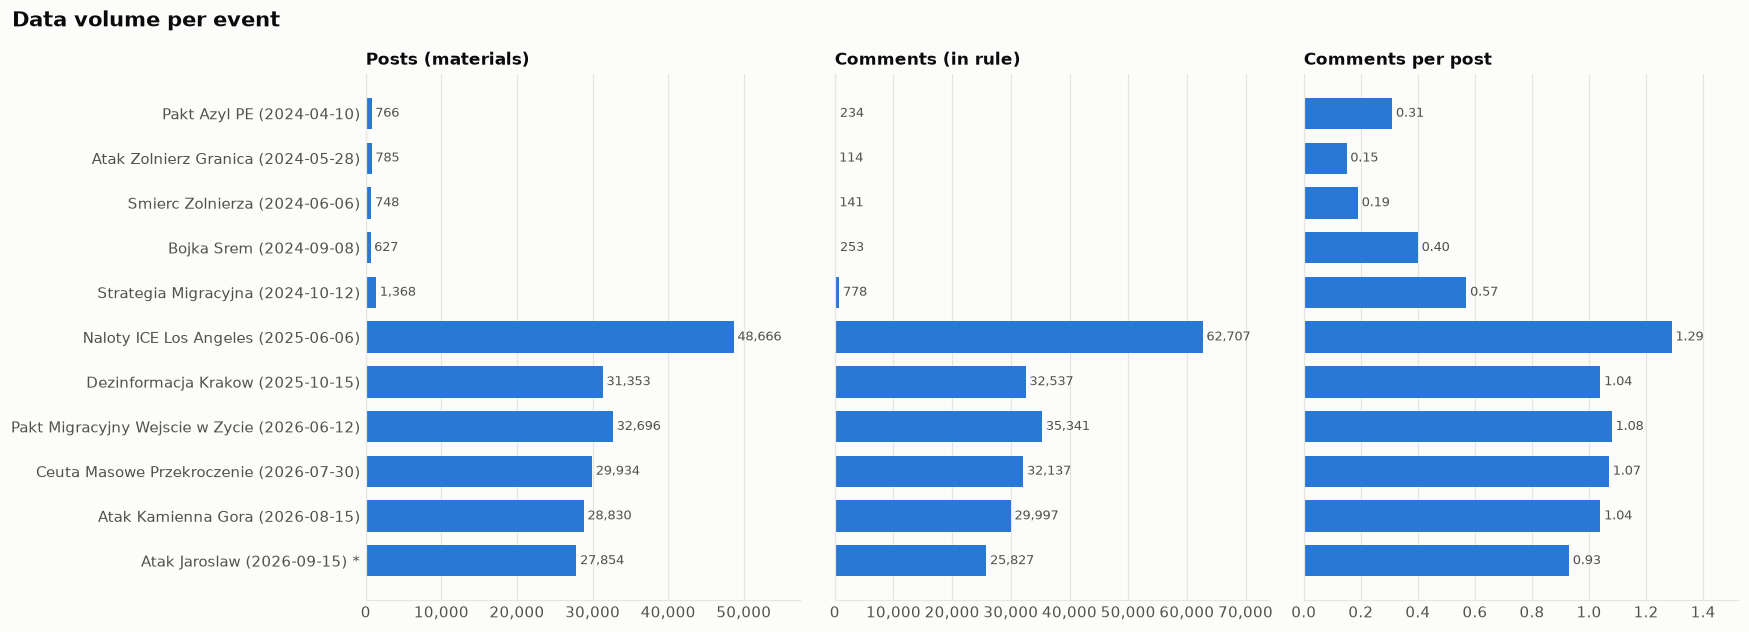

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(16, 0.42 * len(EVENTS) + 1.2), sharey=True)
hbar(axes[0], summary['posts'], LABELS, SERIES[0])
axes[0].set_title('Posts (materials)')
hbar(axes[1], summary['comments'], LABELS, SERIES[0])
axes[1].set_title('Comments (in rule)')
hbar(axes[2], summary['comments_per_post'], LABELS, SERIES[0], fmt='{:.2f}')
axes[2].set_title('Comments per post')
for ax in axes:
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[2].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.1f}'))
fig.suptitle('Data volume per event', x=0.01, ha='left')
fig.tight_layout()
savefig(fig, '01_volume_per_event')

Older events (2024) have far fewer posts – most likely because the Polish-speaking Bluesky community was much
smaller then, not because the events were less discussed. Keep this in mind when comparing raw counts;
the following sections therefore also use **shares** and **indexed** values.

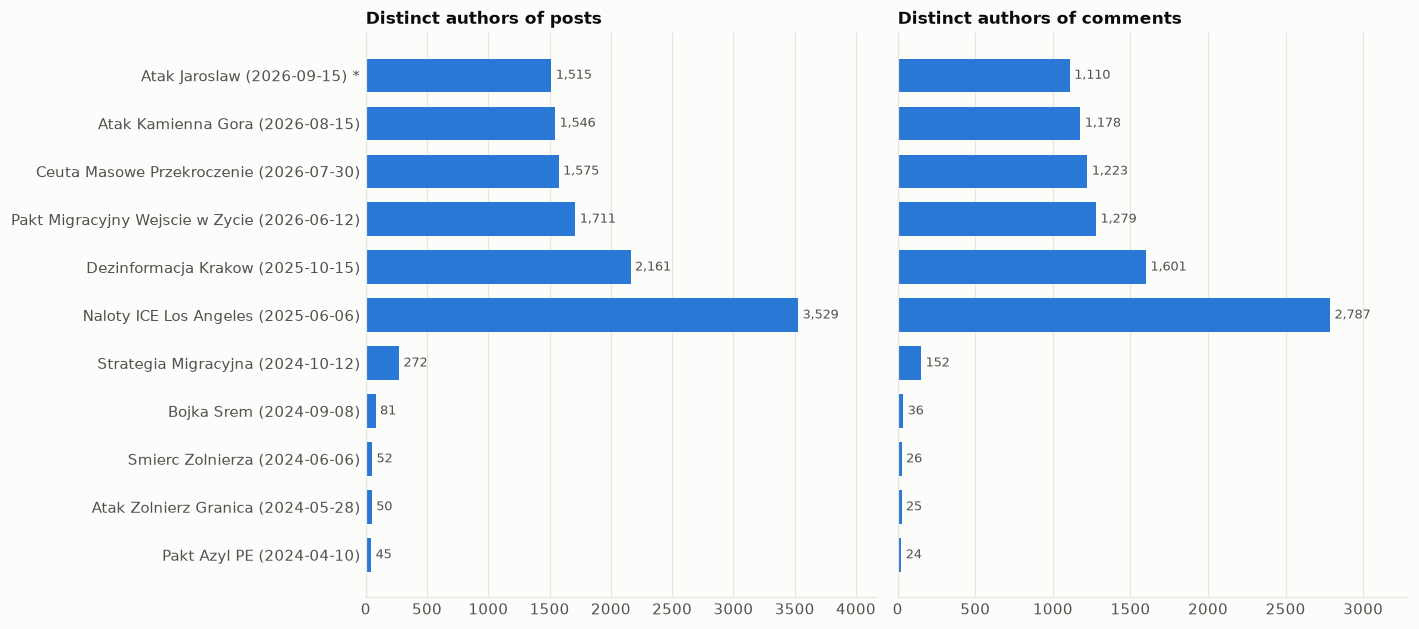

In [53]:
# Unique authors: posting vs commenting
fig, axes = plt.subplots(1, 2, figsize=(13, 0.42 * len(EVENTS) + 1.2), sharey=True)
hbar(axes[0], summary['post_authors'], LABELS, SERIES[0])
axes[0].set_title('Distinct authors of posts')
hbar(axes[1], summary['comment_authors'], LABELS, SERIES[0])
axes[1].set_title('Distinct authors of comments')
fig.tight_layout()
savefig(fig, '02_authors_per_event')

exclusion_reason,other_language,outside_analysis_window,material_too_old,comment_before_material,total
event,,,,,
Pakt_Azyl_PE,21,19,11,0,51
Atak_Zolnierz_Granica,23,10,1,0,34
Smierc_Zolnierza,26,5,1,0,32
Bojka_Srem,78,1,23,0,102
Strategia_Migracyjna,126,32,74,0,232
Naloty_ICE_Los_Angeles,3523,4812,989,17,9341
Dezinformacja_Krakow,2866,3715,221,7,6809
Pakt_Migracyjny_Wejscie_w_Zycie,5322,2797,1131,9,9259
Ceuta_Masowe_Przekroczenie,4475,3960,1118,4,9557


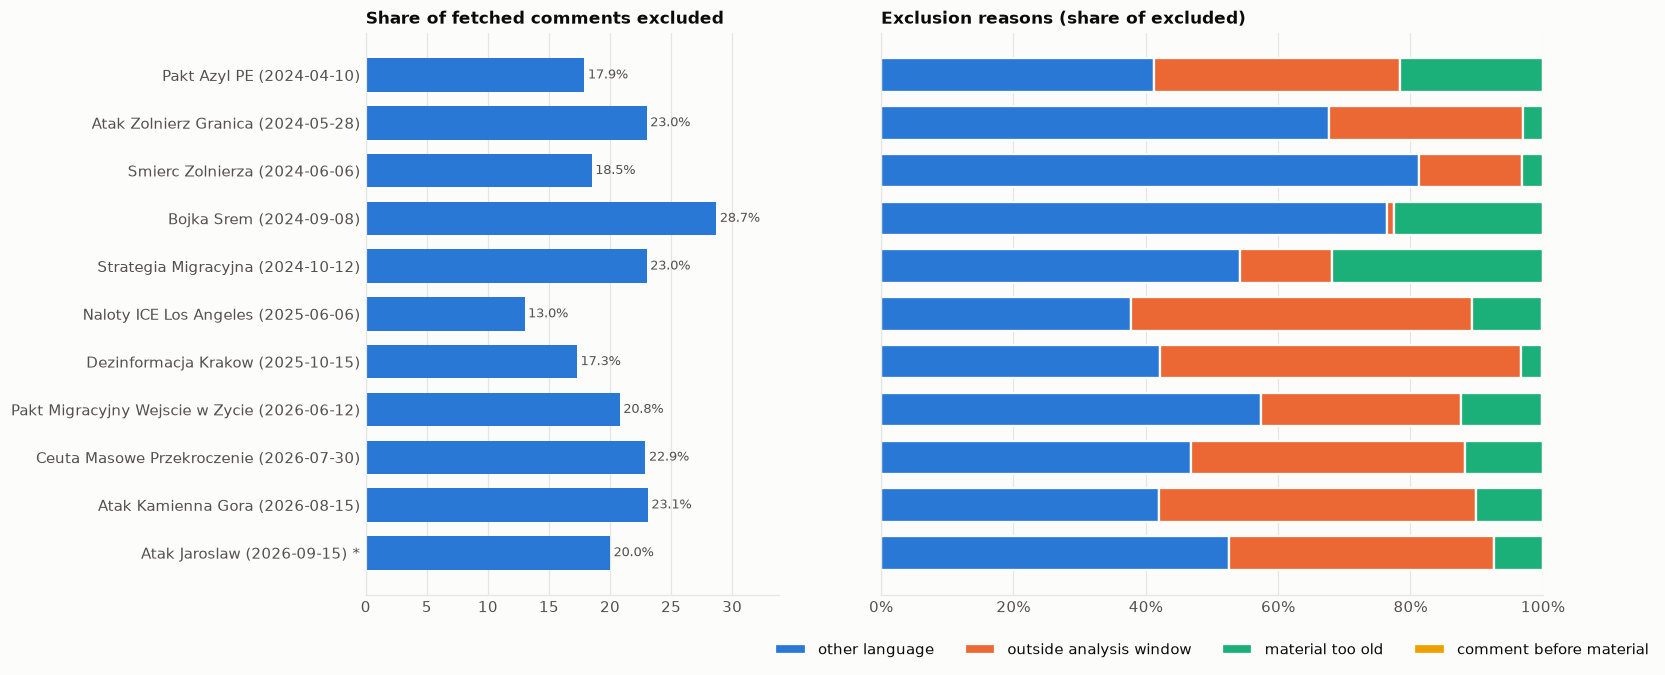

In [54]:
# Why were comments excluded?
reasons = (excluded.groupby(['event', 'exclusion_reason']).size().unstack(fill_value=0)
           .reindex(EVENTS, fill_value=0))
reasons = reasons[reasons.sum().sort_values(ascending=False).index]
reason_share = reasons.div(reasons.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(EVENTS) + 1.6), sharey=True,
                         gridspec_kw={'width_ratios': [1, 1.6]})
hbar(axes[0], summary['excluded_%'], LABELS, SERIES[0], fmt='{:.1f}%')
axes[0].set_title('Share of fetched comments excluded')

left = np.zeros(len(EVENTS))
y = np.arange(len(EVENTS))
for i, r in enumerate(reason_share.columns):
    vals = reason_share[r].fillna(0).values
    axes[1].barh(y, vals, left=left, color=SERIES[i % len(SERIES)], height=0.7,
                 edgecolor=SURFACE, linewidth=1.5, label=r.replace('_', ' '))
    left += vals
axes[1].set_xlim(0, 100)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].grid(axis='y', visible=False)
axes[1].set_title('Exclusion reasons (share of excluded)')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=len(reasons.columns))
fig.tight_layout()
savefig(fig, '03_exclusions')
reasons.assign(total=reasons.sum(axis=1))

## 3. Volume over time

All timelines use `relative_day` (days from the event; 0 = event day, Europe/Warsaw). The shaded area is the
*after* phase; hatched days were not yet collected (events marked \*). Y-axes are independent per panel because
event sizes differ by two orders of magnitude.

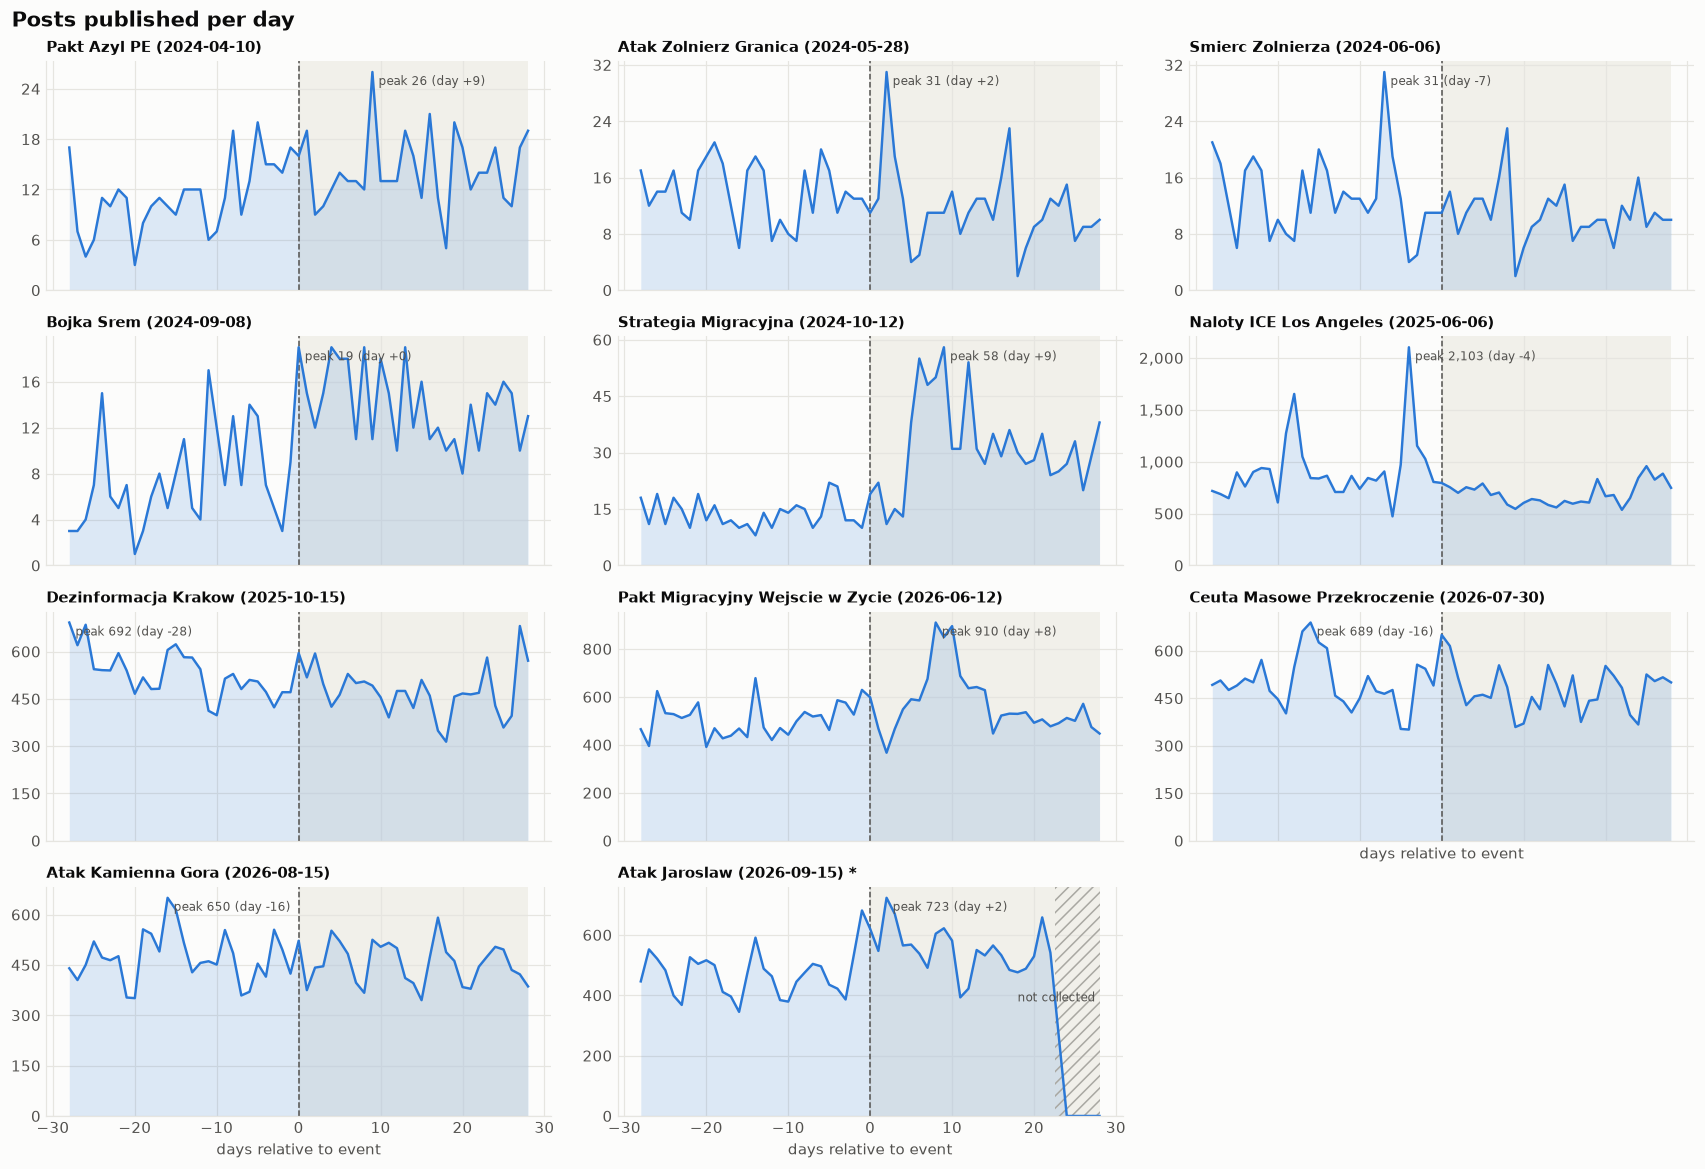

In [55]:
def daily_small_multiples(column, title, color=SERIES[0]):
    fig, axes = small_multiples(len(EVENTS), sharex=True)
    for ax, e in zip(axes, EVENTS):
        d = daily[daily['event'] == e].sort_values('relative_day')
        x, v = d['relative_day'].values, d[column].values
        mark_event_day(ax, x.max())
        ax.fill_between(x, v, color=color, alpha=0.15, lw=0)
        ax.plot(x, v, color=color, lw=1.6)
        if len(v) and np.nanmax(v) > 0:
            i = int(np.nanargmax(v))
            ax.annotate(f'peak {v[i]:,.0f} (day {x[i]:+d})', (x[i], v[i]), xytext=(4, -2),
                        textcoords='offset points', fontsize=8, color=TEXT_SECONDARY, va='top')
        ax.set_ylim(bottom=0)
        if LAST_DAY[e] < x.max():
            ax.axvspan(LAST_DAY[e] + 0.5, x.max(), facecolor='none', edgecolor=NEUTRAL, hatch='///', lw=0)
            ax.text(x.max(), ax.get_ylim()[1] * 0.5, 'not collected ', ha='right', fontsize=8, color=TEXT_SECONDARY)
        ax.set_title(LABEL[e], fontsize=9.5)
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=5))
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    for ax in axes[-3:]:
        ax.set_xlabel('days relative to event')
    fig.suptitle(title, x=0.01, ha='left')
    fig.tight_layout()
    return fig

savefig(daily_small_multiples('materials_published', 'Posts published per day'), '04_daily_posts')

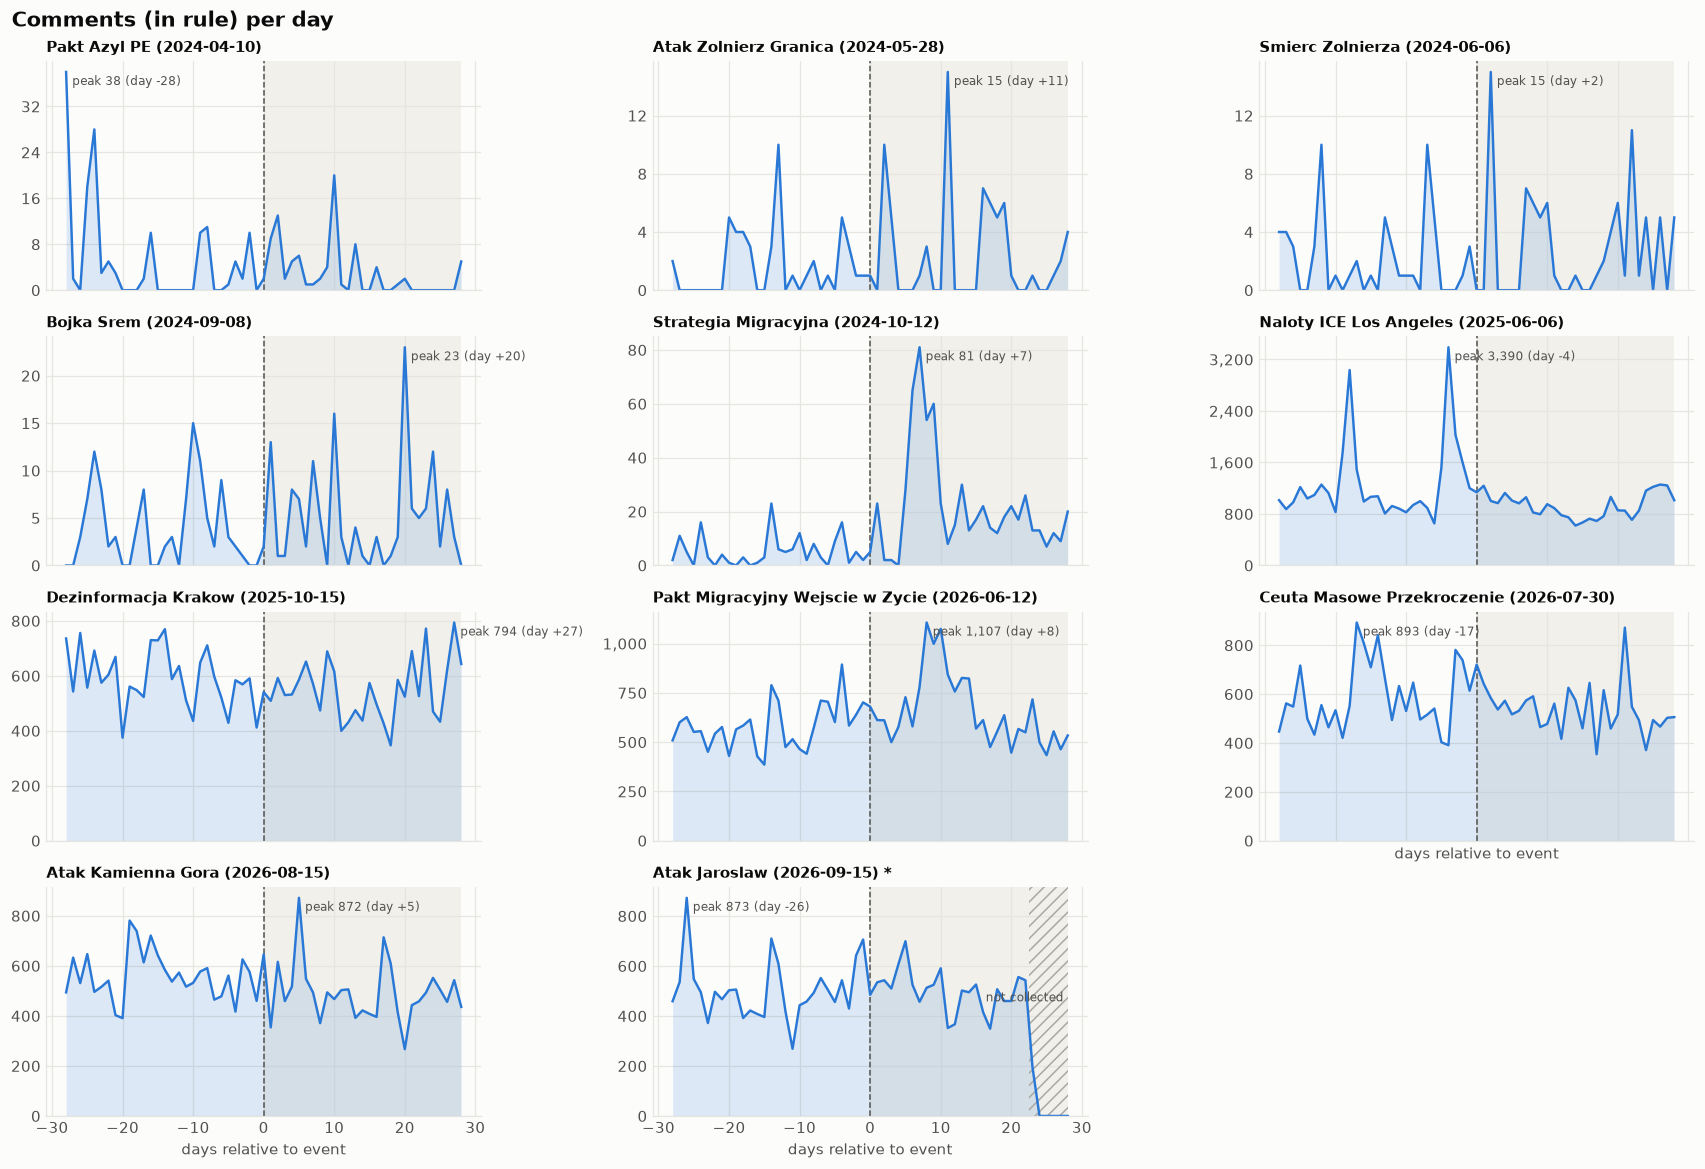

In [56]:
savefig(daily_small_multiples('comments', 'Comments (in rule) per day'), '05_daily_comments')

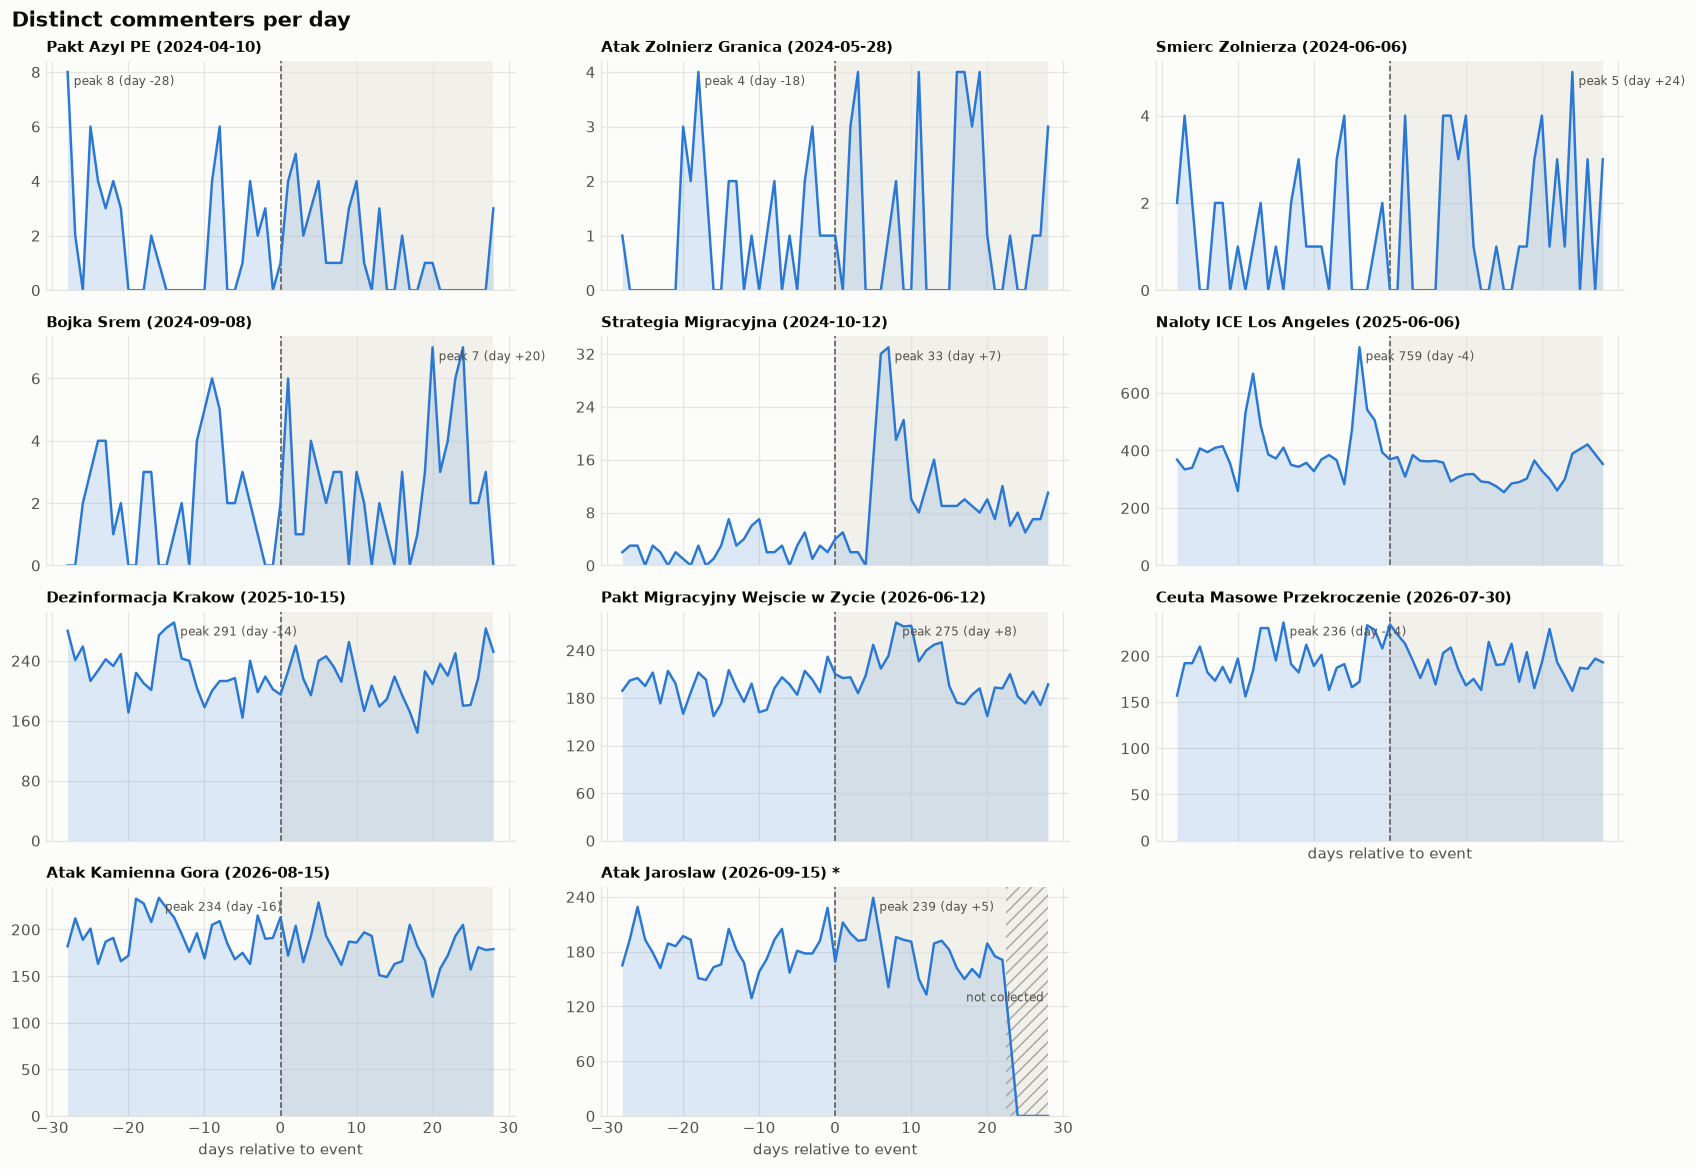

In [57]:
savefig(daily_small_multiples('unique_authors', 'Distinct commenters per day'), '06_daily_commenters')

In [58]:
# Before vs after comparison
def phase_stats(e):
    d = daily_valid[daily_valid['event'] == e]
    b, a, d0 = d[d.phase == 'before'], d[d.phase == 'after'], d[d.phase == 'day_0']
    peak = d.loc[d['materials_published'].idxmax()]
    return pd.Series({
        'posts/day before': b['materials_published'].mean(),
        'posts day 0': d0['materials_published'].sum(),
        'posts/day after': a['materials_published'].mean(),
        'posts after vs before %': (a['materials_published'].mean() / b['materials_published'].mean() - 1) * 100,
        'posts day0..+3 vs before %': (d[d.relative_day.between(0, 3)]['materials_published'].mean()
                                       / b['materials_published'].mean() - 1) * 100,
        'peak day': int(peak['relative_day']),
        'comments/day before': b['comments'].mean(),
        'comments/day after': a['comments'].mean(),
        'comments after vs before %': (a['comments'].mean() / b['comments'].mean() - 1) * 100
                                      if b['comments'].mean() > 0 else np.nan,
    })

lift = pd.DataFrame({e: phase_stats(e) for e in EVENTS}).T
lift.index.name = 'event'
lift.round(1)

,posts/day before,posts day 0,posts/day after,posts after vs before %,posts day0..+3 vs before %,peak day,comments/day before,comments/day after,comments after vs before %
event,,,,,,,,,
Pakt_Azyl_PE,11.1,16.0,14.3,28.9,21.5,9.0,5.3,3.0,-43.2
Atak_Zolnierz_Granica,13.9,11.0,11.7,-15.7,33.2,2.0,1.6,2.4,45.7
Smierc_Zolnierza,13.4,11.0,10.9,-19.1,-18.1,-7.0,2.1,2.9,39.0
Bojka_Srem,7.4,19.0,13.8,86.1,105.3,0.0,3.8,5.1,34.6
Strategia_Migracyjna,13.8,19.0,32.1,133.8,21.8,9.0,5.2,22.4,325.9
Naloty_ICE_Los_Angeles,918.7,795.0,690.0,-24.9,-18.3,-4.0,1268.2,930.7,-26.6
Dezinformacja_Krakow,529.5,595.0,473.1,-10.7,4.1,-28.0,592.9,549.8,-7.3
Pakt_Migracyjny_Wejscie_w_Zycie,504.3,598.0,570.6,13.2,-5.9,8.0,579.6,658.3,13.6
Ceuta_Masowe_Przekroczenie,499.2,650.0,471.0,-5.7,10.6,-16.0,587.1,534.9,-8.9


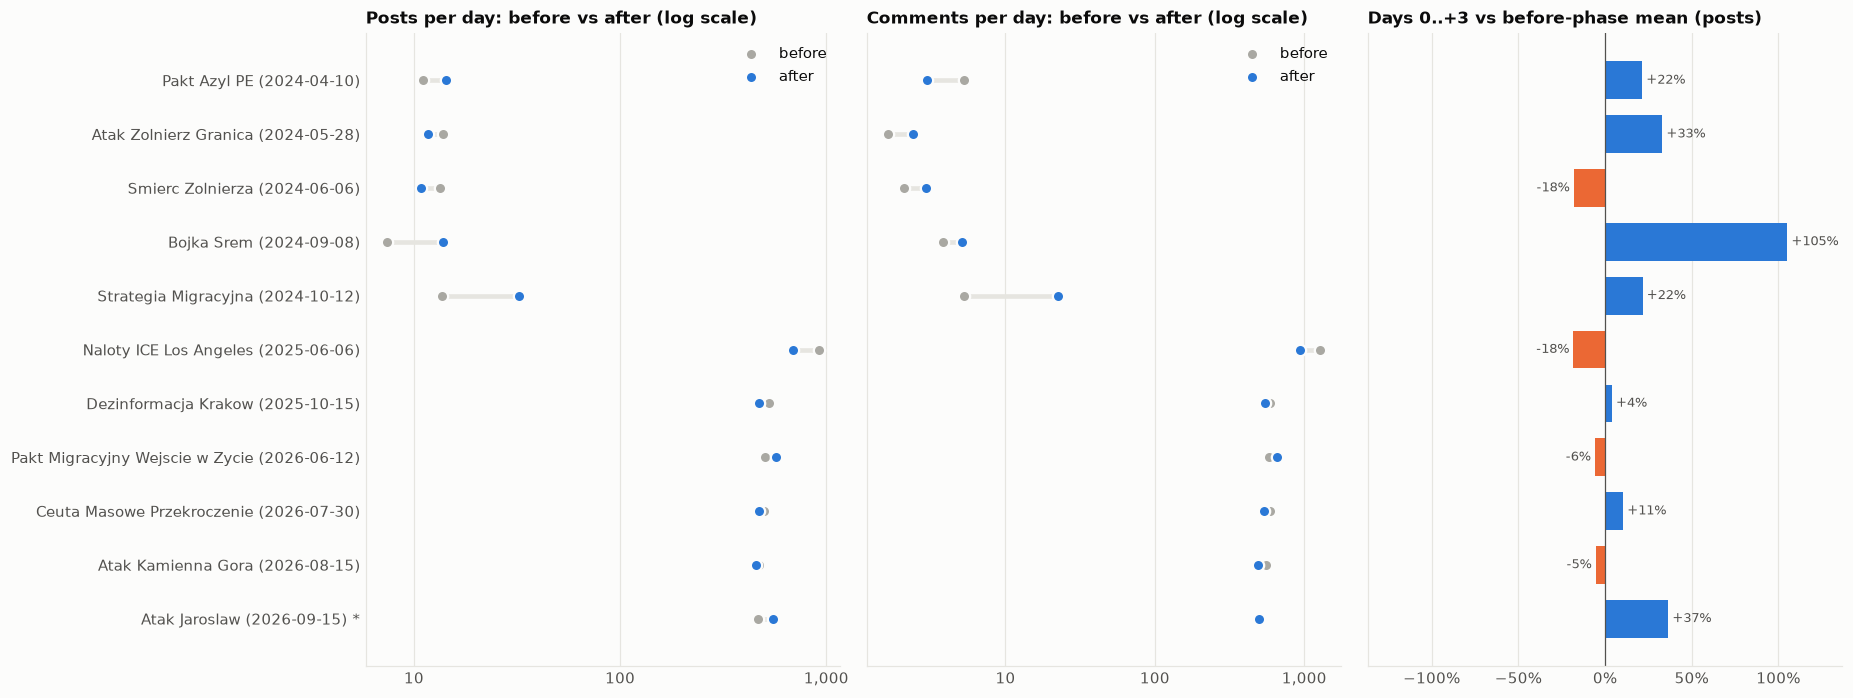

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(17, 0.45 * len(EVENTS) + 1.5), sharey=True)
y = np.arange(len(EVENTS))
for ax, (b, a, title) in zip(axes[:2], [('posts/day before', 'posts/day after', 'Posts per day'),
                                        ('comments/day before', 'comments/day after', 'Comments per day')]):
    bv, av = lift[b].values.astype(float), lift[a].values.astype(float)
    ax.hlines(y, np.minimum(bv, av), np.maximum(bv, av), color=GRID, lw=3)
    ax.scatter(bv, y, s=55, color=NEUTRAL, label='before', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(av, y, s=55, color=SERIES[0], label='after', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.set_xscale('symlog', linthresh=1)
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    ax.set_title(f'{title}: before vs after (log scale)')
    ax.grid(axis='y', visible=False)
    ax.legend(loc='upper right')
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis()

ch = lift['posts day0..+3 vs before %'].astype(float).values
axes[2].barh(y, ch, color=np.where(ch >= 0, POS, NEG), height=0.7)
axes[2].axvline(0, color=TEXT_SECONDARY, lw=0.8)
for yi, v in zip(y, ch):
    axes[2].text(v, yi, f' {v:+.0f}% ', va='center', ha='left' if v >= 0 else 'right',
                 fontsize=8.5, color=TEXT_SECONDARY)
axes[2].set_title('Days 0..+3 vs before-phase mean (posts)')
axes[2].grid(axis='y', visible=False)
axes[2].xaxis.set_major_formatter(mticker.PercentFormatter())
pad = max(abs(np.nanmin(ch)), abs(np.nanmax(ch))) * 1.3
axes[2].set_xlim(min(-10, -pad if np.nanmin(ch) < 0 else -10), pad)
fig.tight_layout()
savefig(fig, '08_before_after')

## 4. Keywords

`keywords` in `posts.csv` lists every search keyword the post matched (`|`-separated). Matching is done by
Bluesky search on word stems (e.g. `granic`, `polsk`), so a post can match several keywords at once.

### 4.1 Which keywords dominate overall?

39 keywords matched at least one post; 0 search keywords never matched:
-


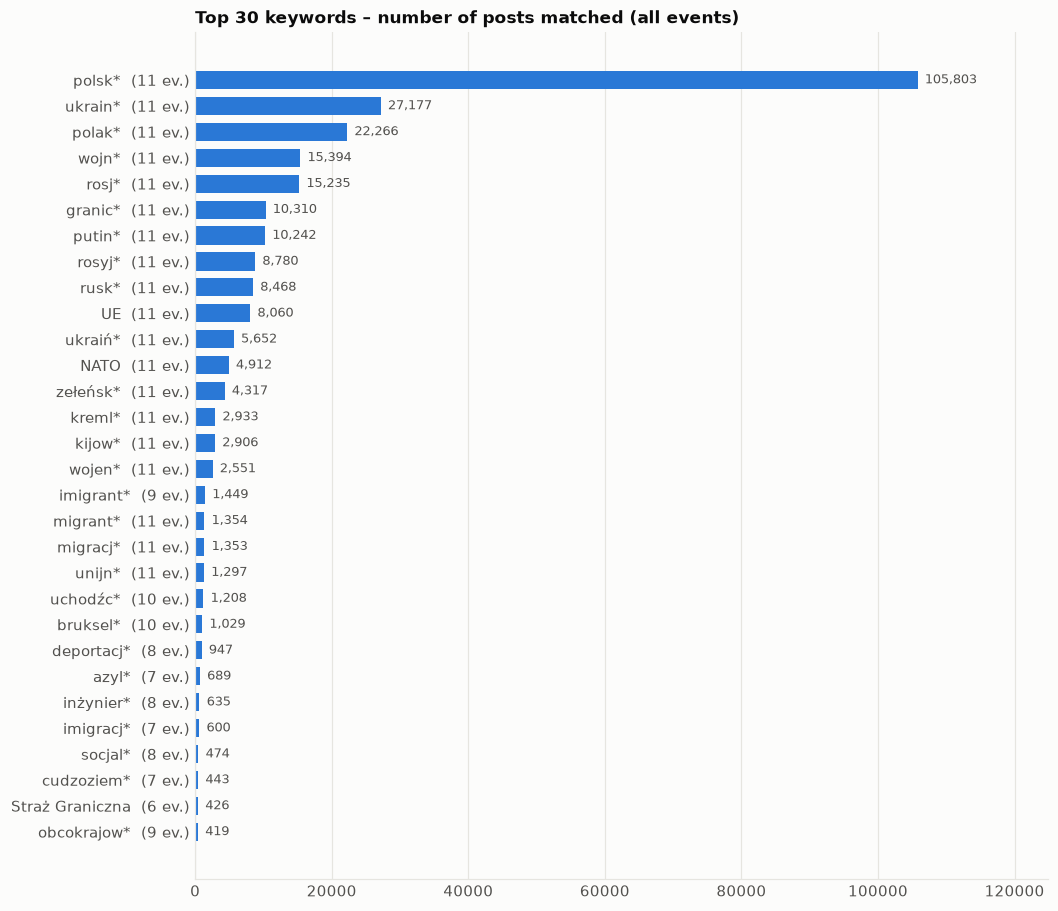

In [60]:
kw_total = kw['keyword'].value_counts()
kw_events = kw.groupby('keyword')['event'].nunique()

fig, ax = plt.subplots(figsize=(10, 0.3 * min(30, len(kw_total)) + 1))
top = kw_total.head(30)
hbar(ax, top, [f'{k}  ({kw_events[k]} ev.)' for k in top.index])
ax.set_title('Top 30 keywords – number of posts matched (all events)')
savefig(fig, '09_keywords_global')

all_keywords = sorted({k for r in reports.values() for k in r.get('keywords', [])})
never = [k for k in all_keywords if k not in kw_total.index]
print(f'{len(kw_total)} keywords matched at least one post; {len(never)} search keywords never matched:')
print(', '.join(never) if never else '-')

### 4.2 Keyword profile of each event

Share of an event's posts that match the keyword (%). Normalising per event makes small and large events
comparable.

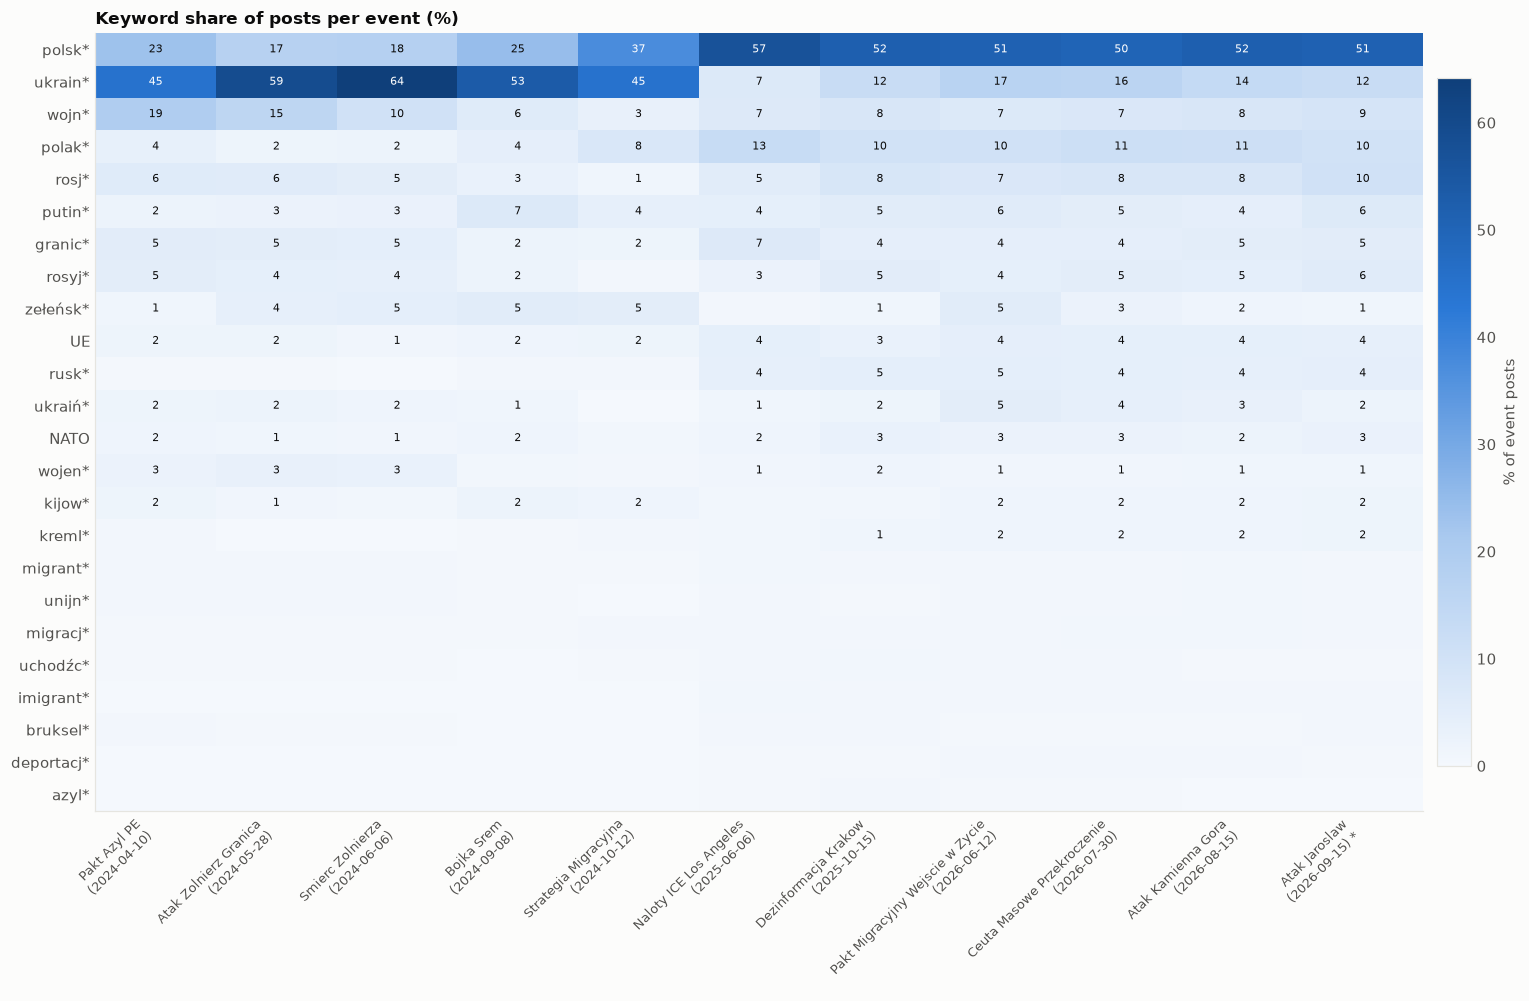

In [61]:
kw_share = (kw.groupby(['keyword', 'event'])['post_id'].nunique().unstack(fill_value=0)
            .reindex(columns=EVENTS, fill_value=0)
            .div(summary['posts'], axis=1) * 100)
kw_share = kw_share.loc[kw_share.mean(axis=1).sort_values(ascending=False).index]
kw_share = kw_share[kw_share.max(axis=1) >= 0.5]          # hide keywords that never reach 0.5 %

fig, ax = plt.subplots(figsize=(14, 0.3 * len(kw_share) + 2))
im = ax.imshow(kw_share.values, aspect='auto', cmap=SEQ, vmin=0)
ax.set_yticks(range(len(kw_share)), kw_share.index)
ax.set_xticks(range(len(EVENTS)), [l.replace(' (', '\n(') for l in LABELS], rotation=45, ha='right', fontsize=8.5)
ax.grid(False)
vmax = kw_share.values.max()
for i in range(kw_share.shape[0]):
    for j in range(kw_share.shape[1]):
        v = kw_share.iat[i, j]
        if v >= 1:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5,
                    color='white' if v > vmax * 0.55 else TEXT_PRIMARY)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label('% of event posts')
ax.set_title('Keyword share of posts per event (%)')
fig.tight_layout()
savefig(fig, '10_keyword_event_heatmap')

In [62]:
# Top keywords per event as a compact table
top_kw_table = pd.DataFrame({
    LABEL[e]: [f'{k} ({v:.0f}%)' for k, v in kw_share[e].sort_values(ascending=False).head(10).items()]
    for e in EVENTS
}, index=pd.RangeIndex(1, 11, name='rank')).T
top_kw_table

rank,1,2,3,4,5,6,7,8,9,10
Pakt Azyl PE (2024-04-10),ukrain* (45%),polsk* (23%),wojn* (19%),rosj* (6%),granic* (5%),rosyj* (5%),polak* (4%),wojen* (3%),putin* (2%),UE (2%)
Atak Zolnierz Granica (2024-05-28),ukrain* (59%),polsk* (17%),wojn* (15%),rosj* (6%),granic* (5%),rosyj* (4%),zełeńsk* (4%),wojen* (3%),putin* (3%),ukraiń* (2%)
Smierc Zolnierza (2024-06-06),ukrain* (64%),polsk* (18%),wojn* (10%),rosj* (5%),zełeńsk* (5%),granic* (5%),rosyj* (4%),wojen* (3%),putin* (3%),polak* (2%)
Bojka Srem (2024-09-08),ukrain* (53%),polsk* (25%),putin* (7%),wojn* (6%),zełeńsk* (5%),polak* (4%),rosj* (3%),granic* (2%),kijow* (2%),rosyj* (2%)
Strategia Migracyjna (2024-10-12),ukrain* (45%),polsk* (37%),polak* (8%),zełeńsk* (5%),putin* (4%),wojn* (3%),UE (2%),granic* (2%),kijow* (2%),rosj* (1%)
Naloty ICE Los Angeles (2025-06-06),polsk* (57%),polak* (13%),ukrain* (7%),wojn* (7%),granic* (7%),rosj* (5%),putin* (4%),UE (4%),rusk* (4%),rosyj* (3%)
Dezinformacja Krakow (2025-10-15),polsk* (52%),ukrain* (12%),polak* (10%),rosj* (8%),wojn* (8%),putin* (5%),rosyj* (5%),rusk* (5%),granic* (4%),NATO (3%)
Pakt Migracyjny Wejscie w Zycie (2026-06-12),polsk* (51%),ukrain* (17%),polak* (10%),rosj* (7%),wojn* (7%),putin* (6%),zełeńsk* (5%),ukraiń* (5%),rusk* (5%),UE (4%)
Ceuta Masowe Przekroczenie (2026-07-30),polsk* (50%),ukrain* (16%),polak* (11%),rosj* (8%),wojn* (7%),putin* (5%),rosyj* (5%),granic* (4%),UE (4%),rusk* (4%)
Atak Kamienna Gora (2026-08-15),polsk* (52%),ukrain* (14%),polak* (11%),rosj* (8%),wojn* (8%),granic* (5%),rosyj* (5%),putin* (4%),UE (4%),rusk* (4%)


### 4.3 Per-event keyword timelines

For every event:
* **top-left** – most frequent keywords (posts matched, % of event posts),
* **top-right** – posts per day for the 5 most frequent keywords,
* **bottom** – heatmap of posts per day for the top 15 keywords (each column is one day).

Change `TOP_LINES`, `TOP_HEAT` or `SMOOTH` (rolling-mean window in days, 1 = raw) to adjust.

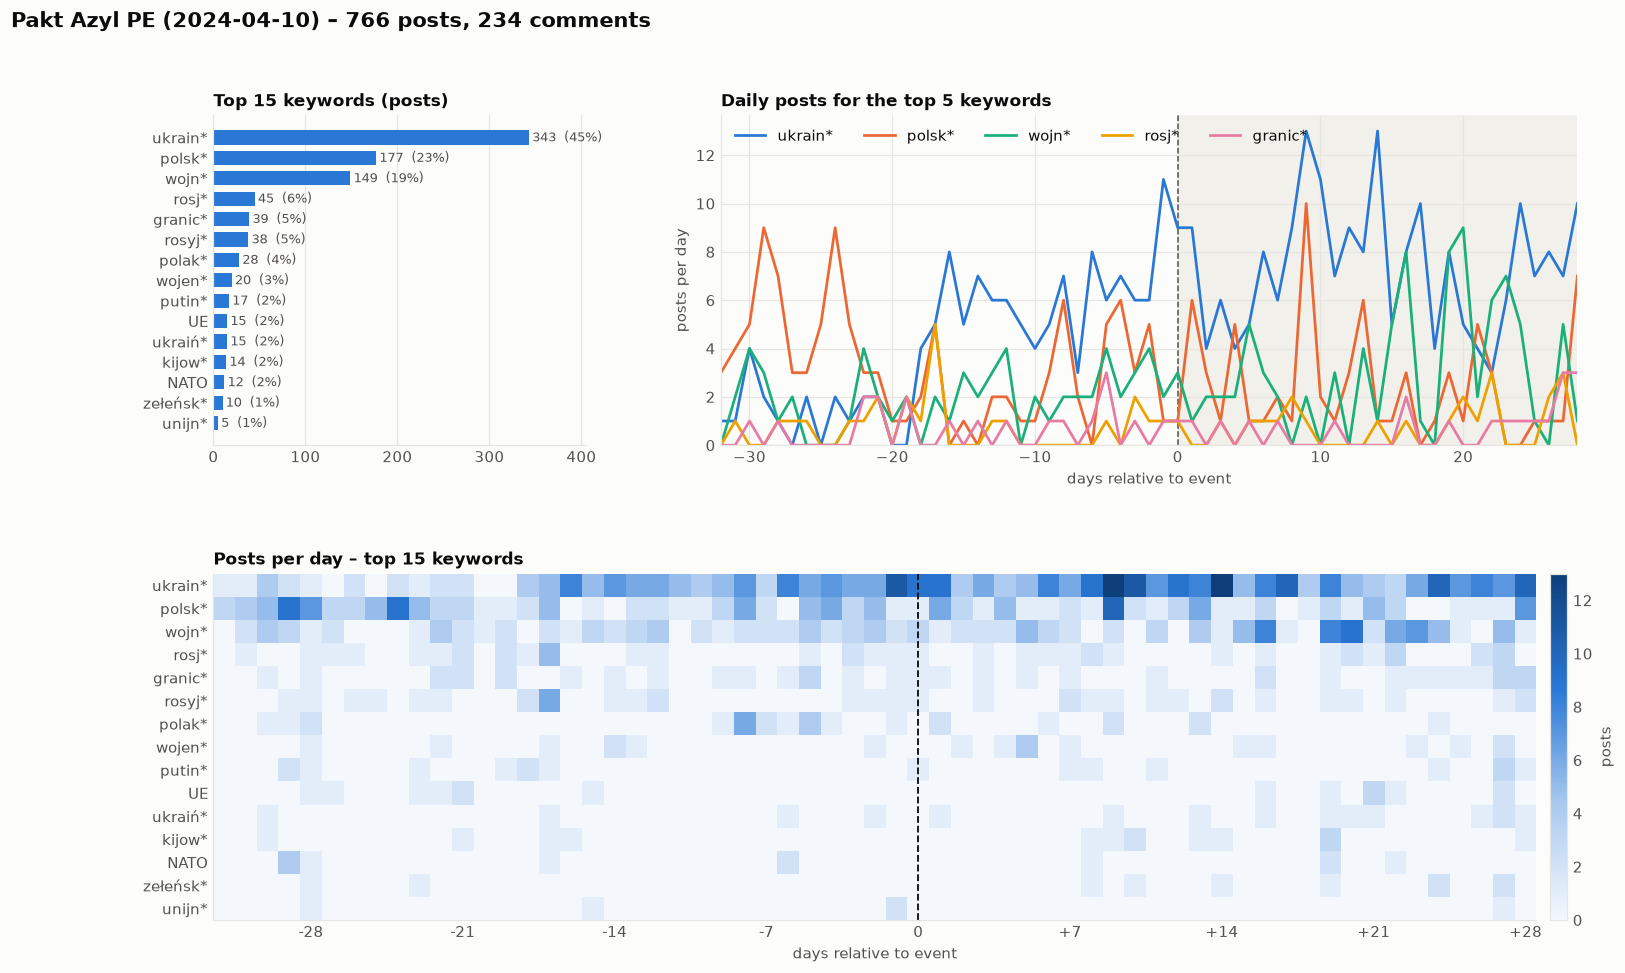

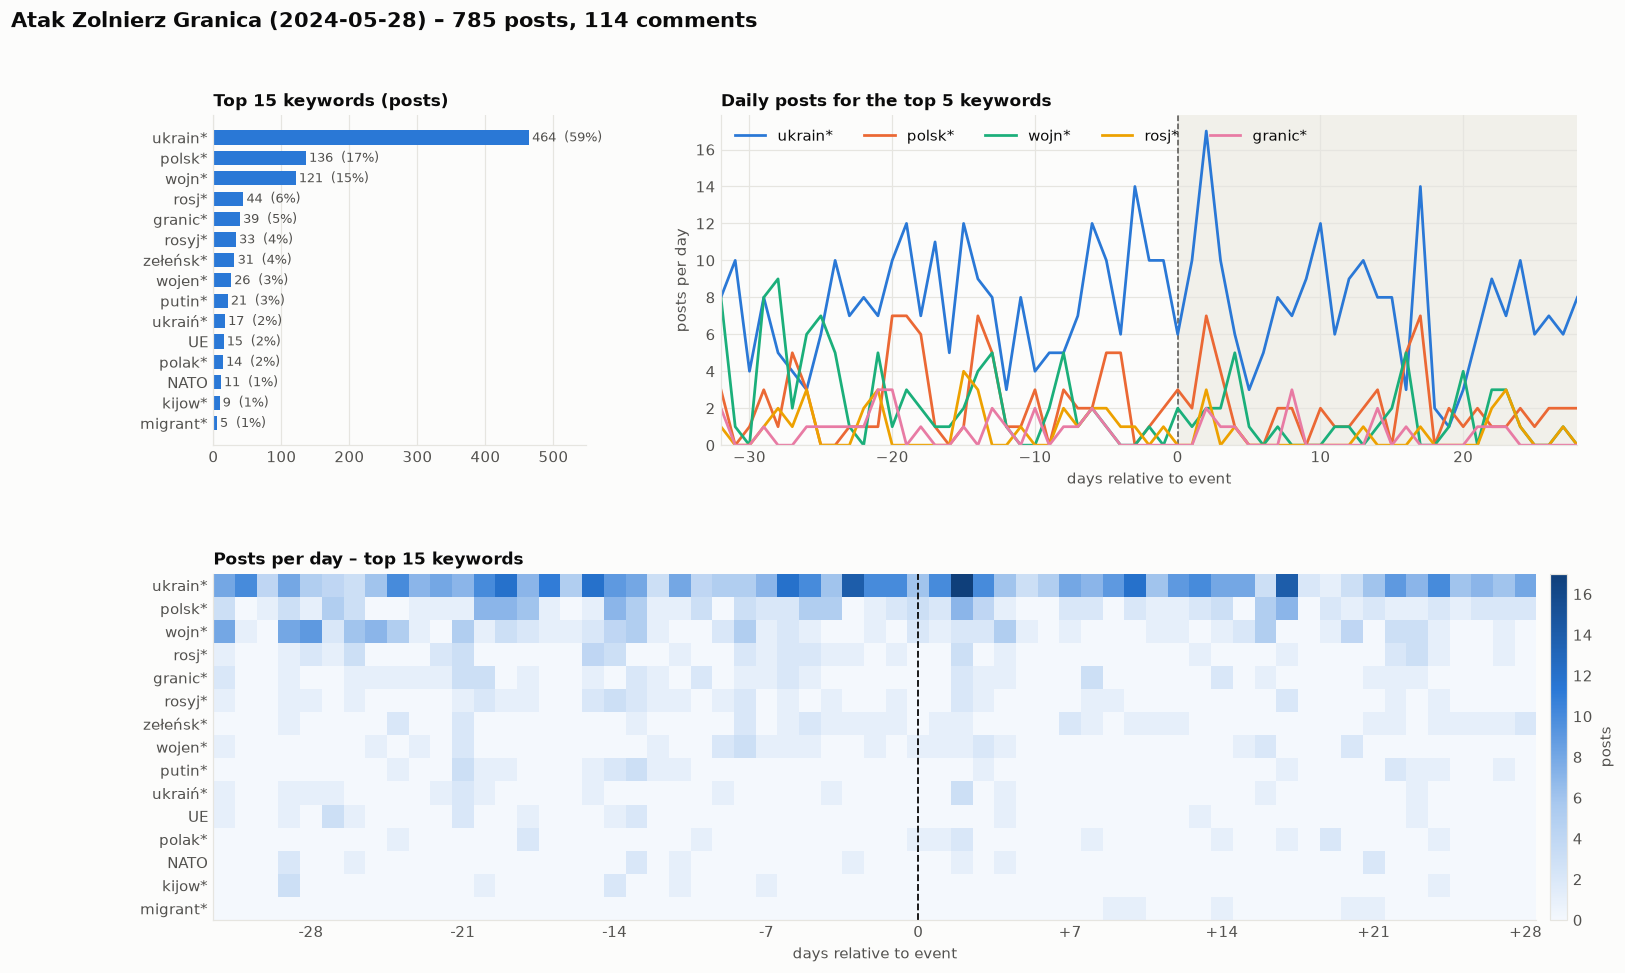

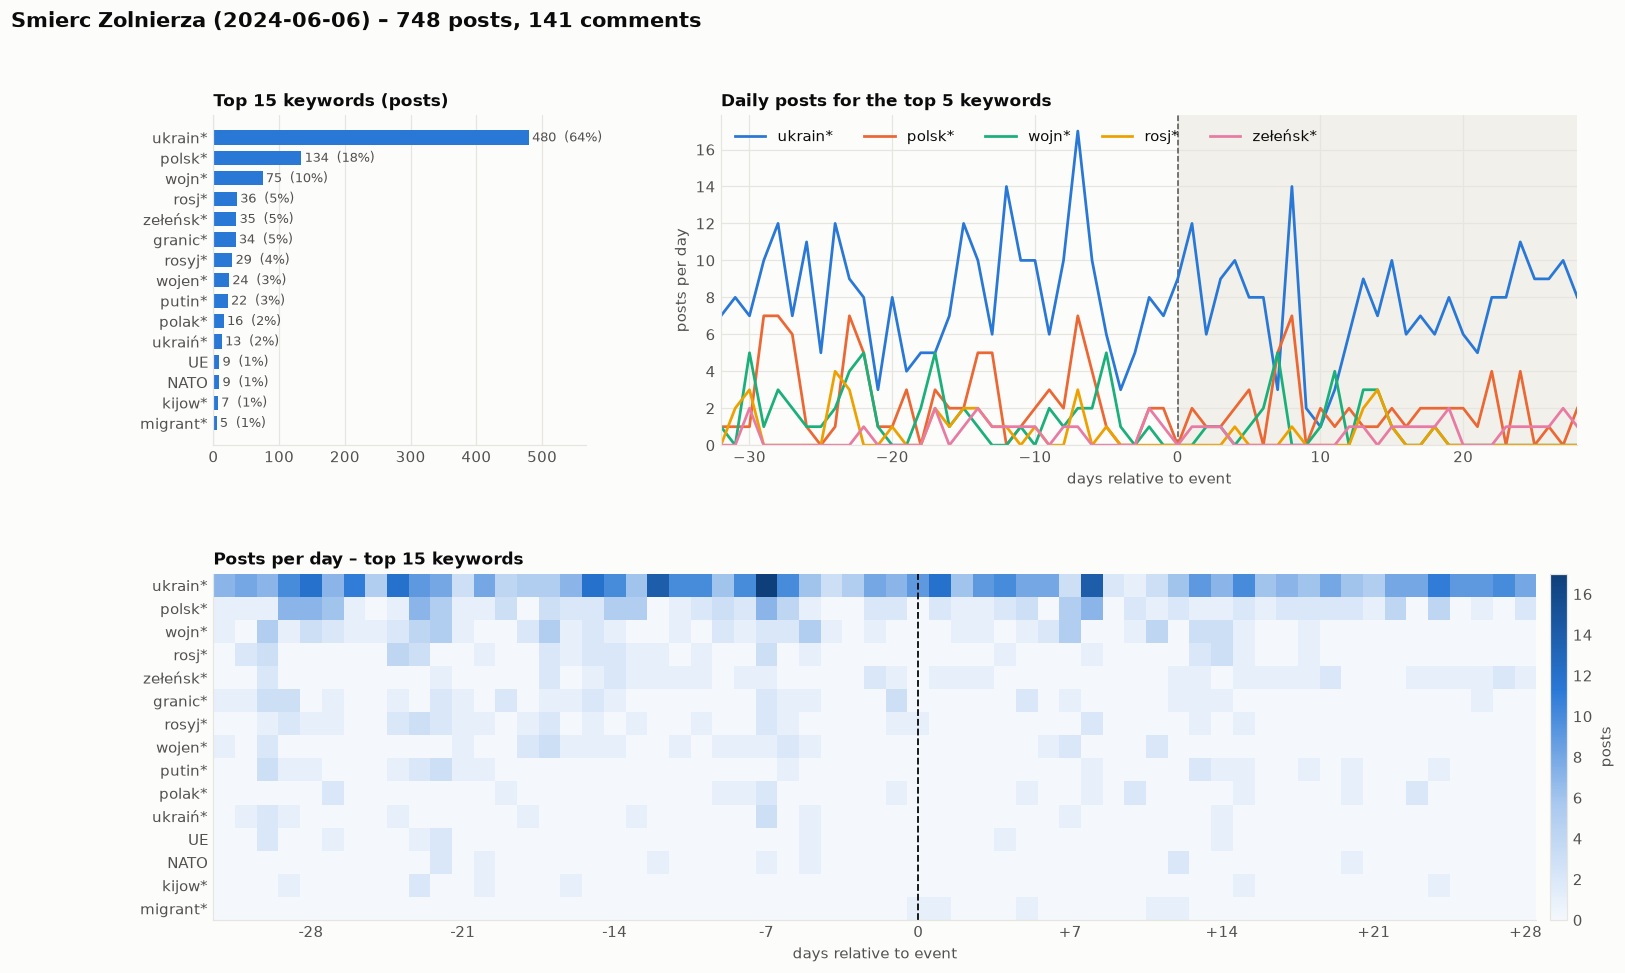

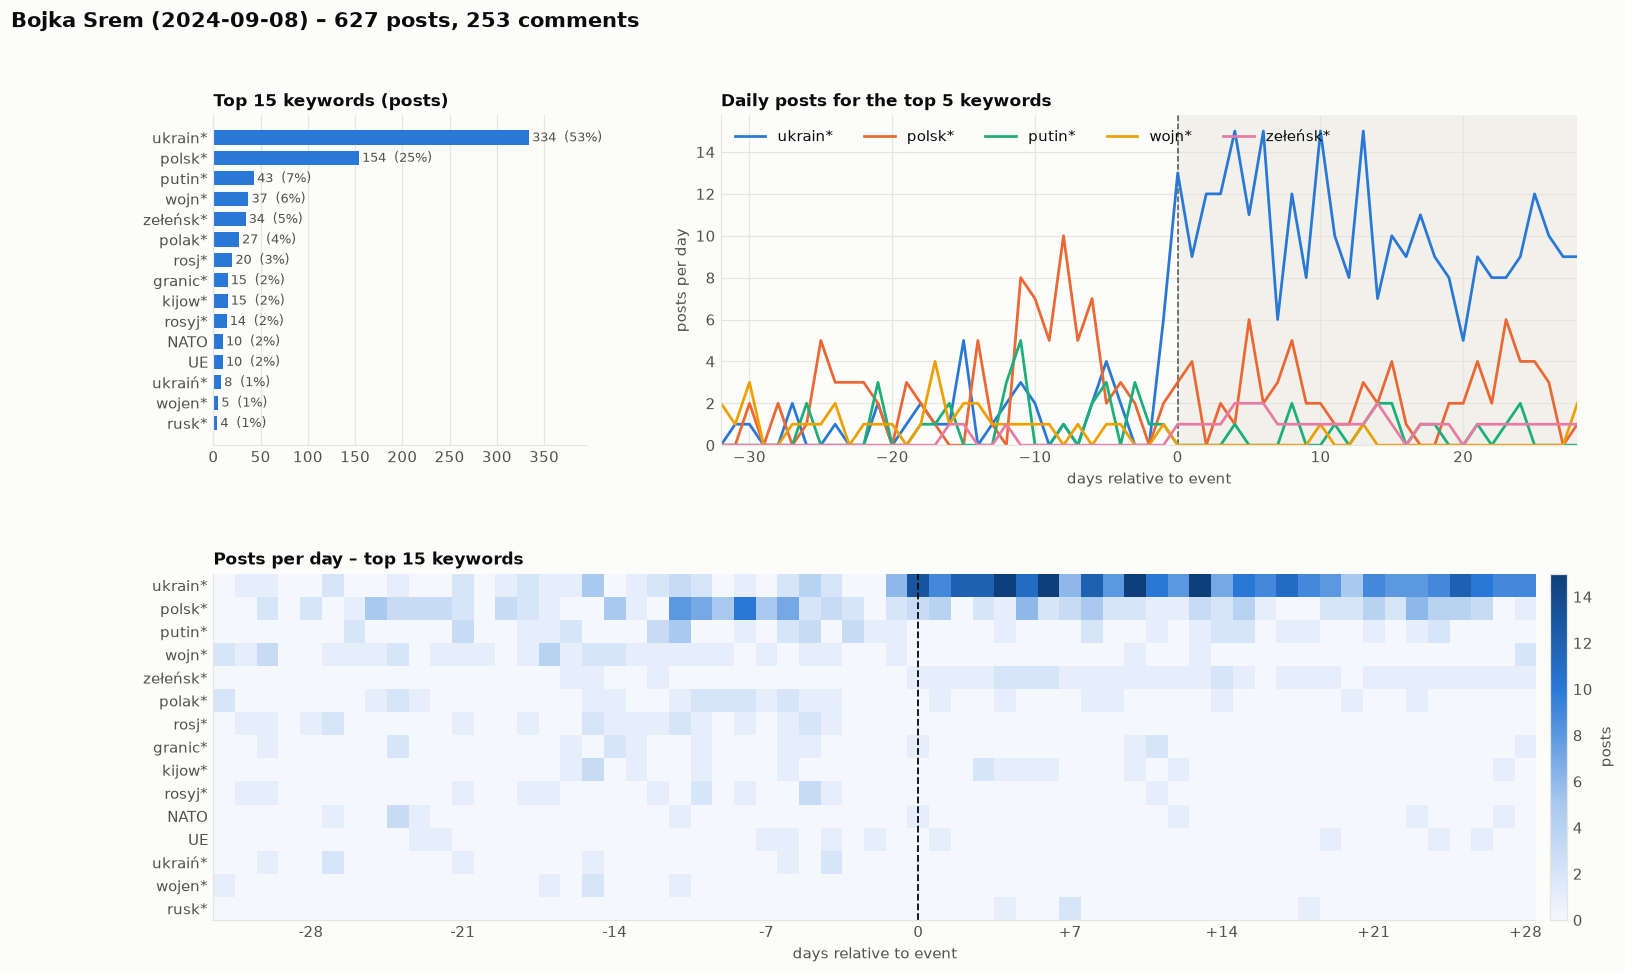

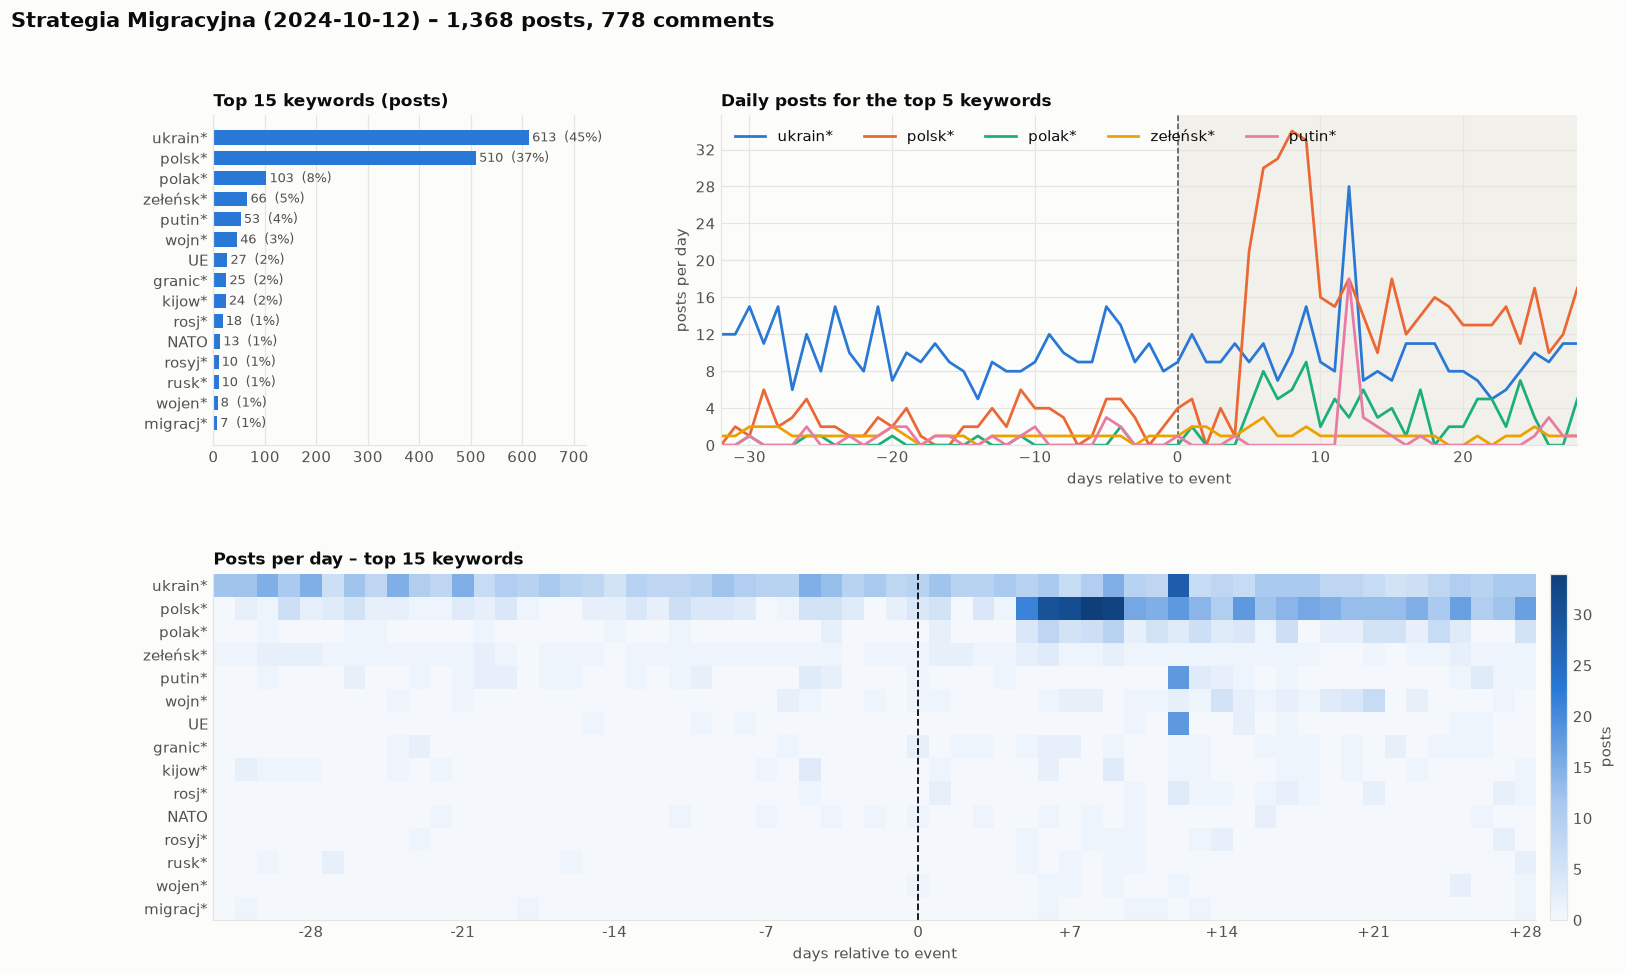

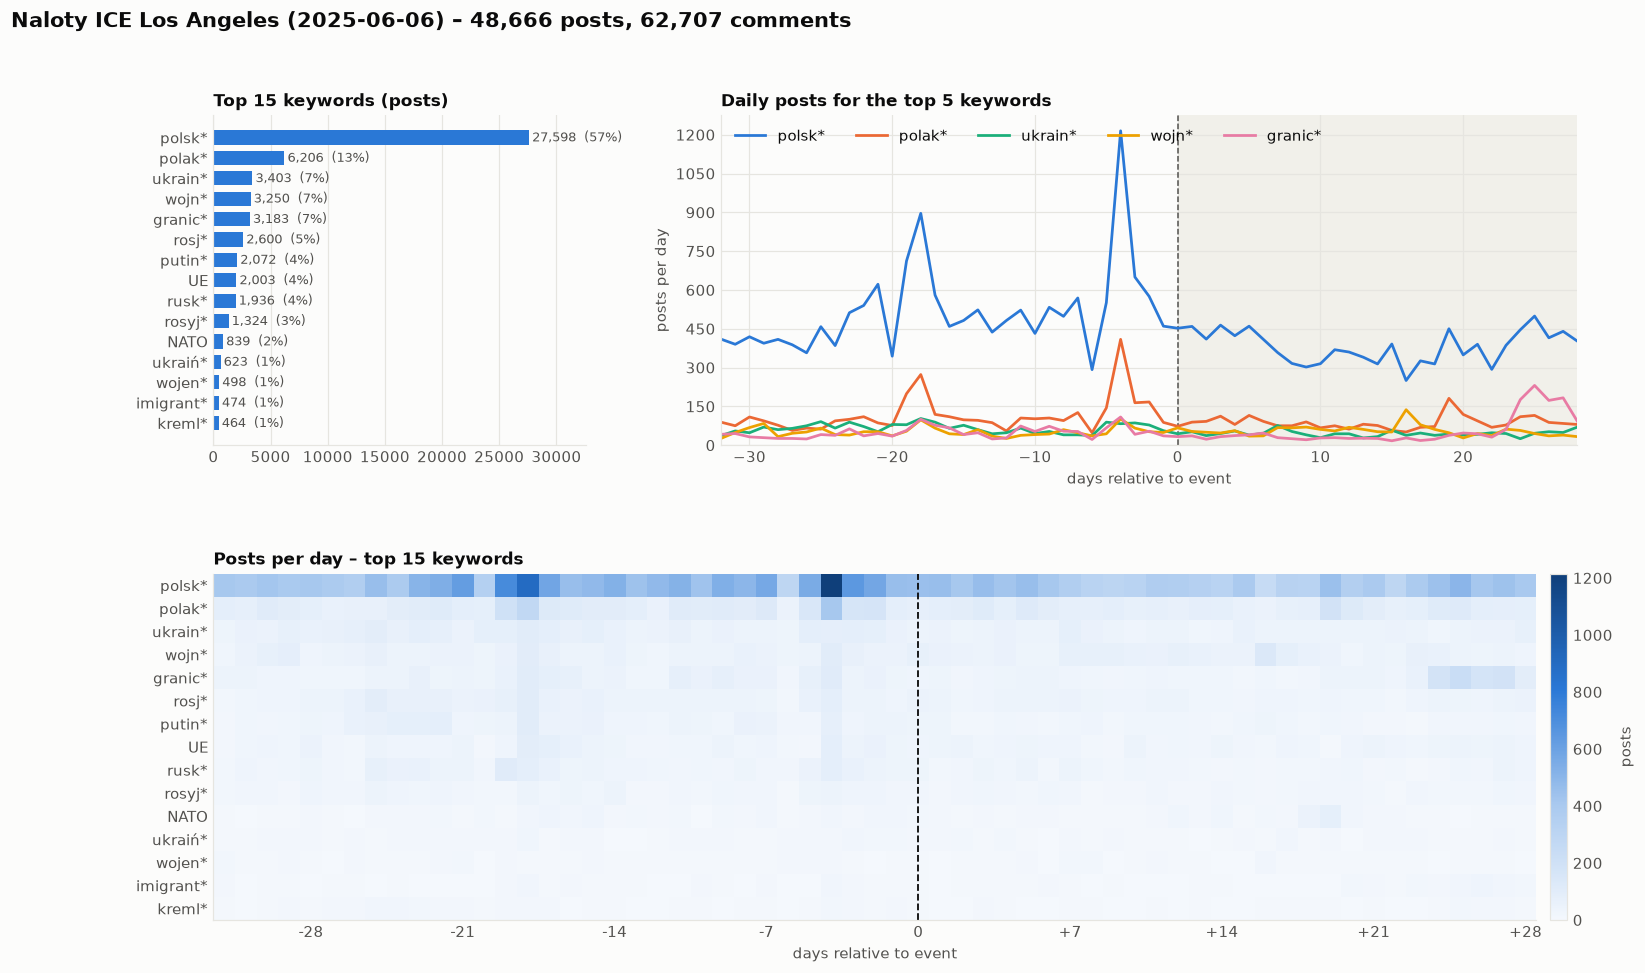

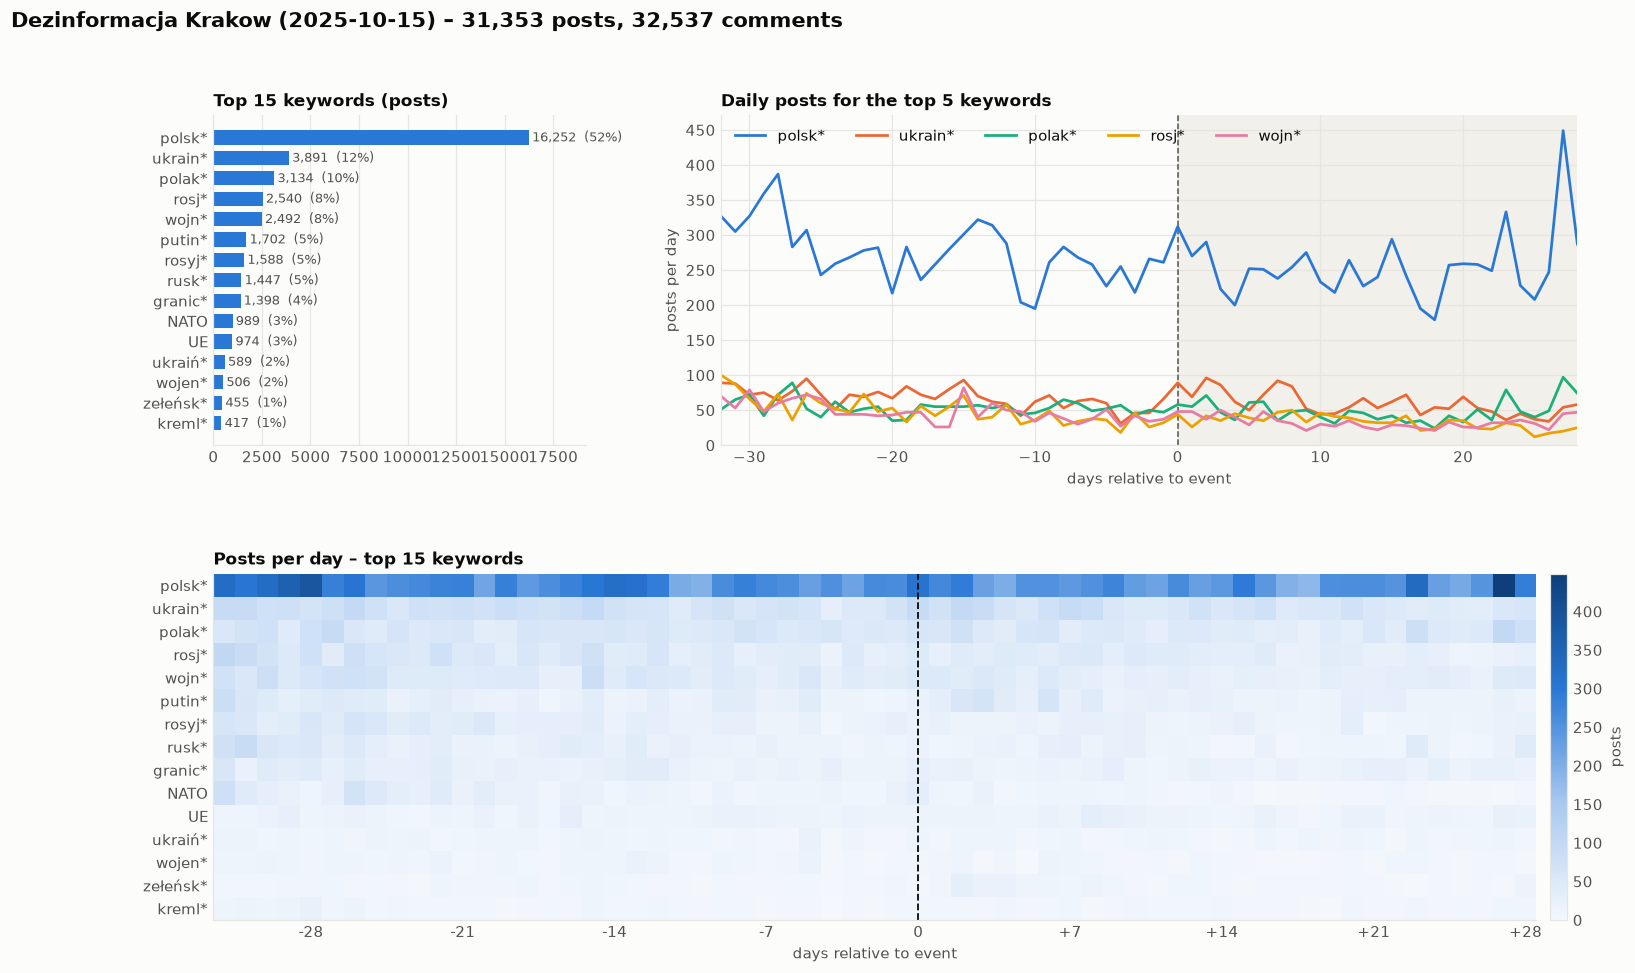

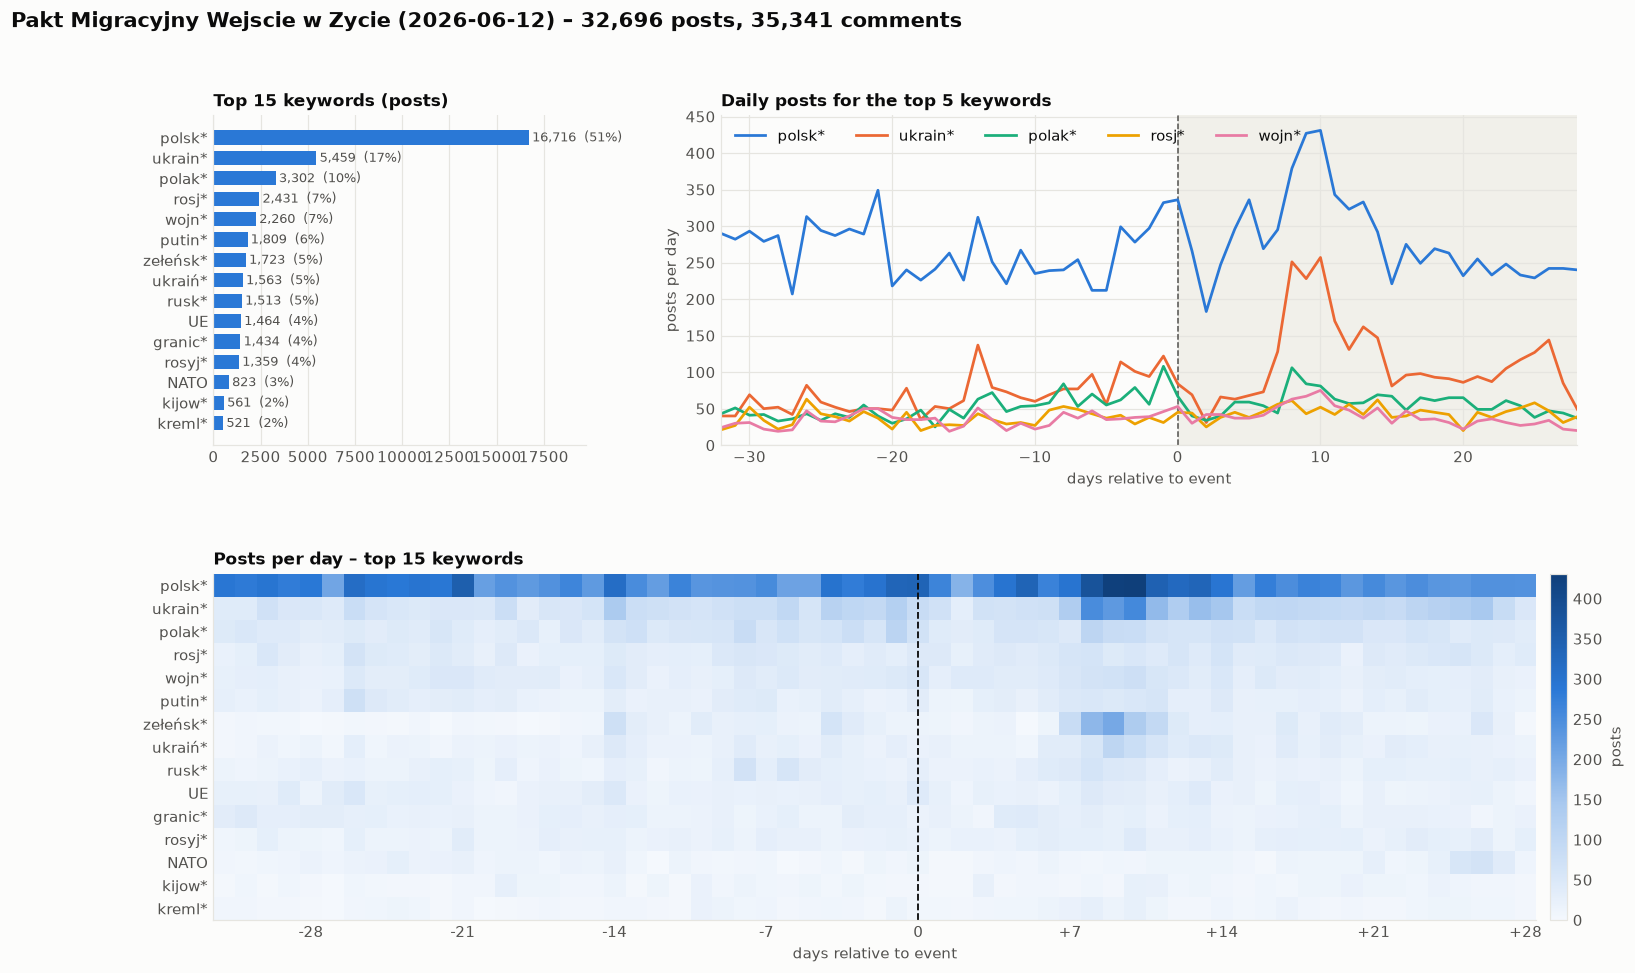

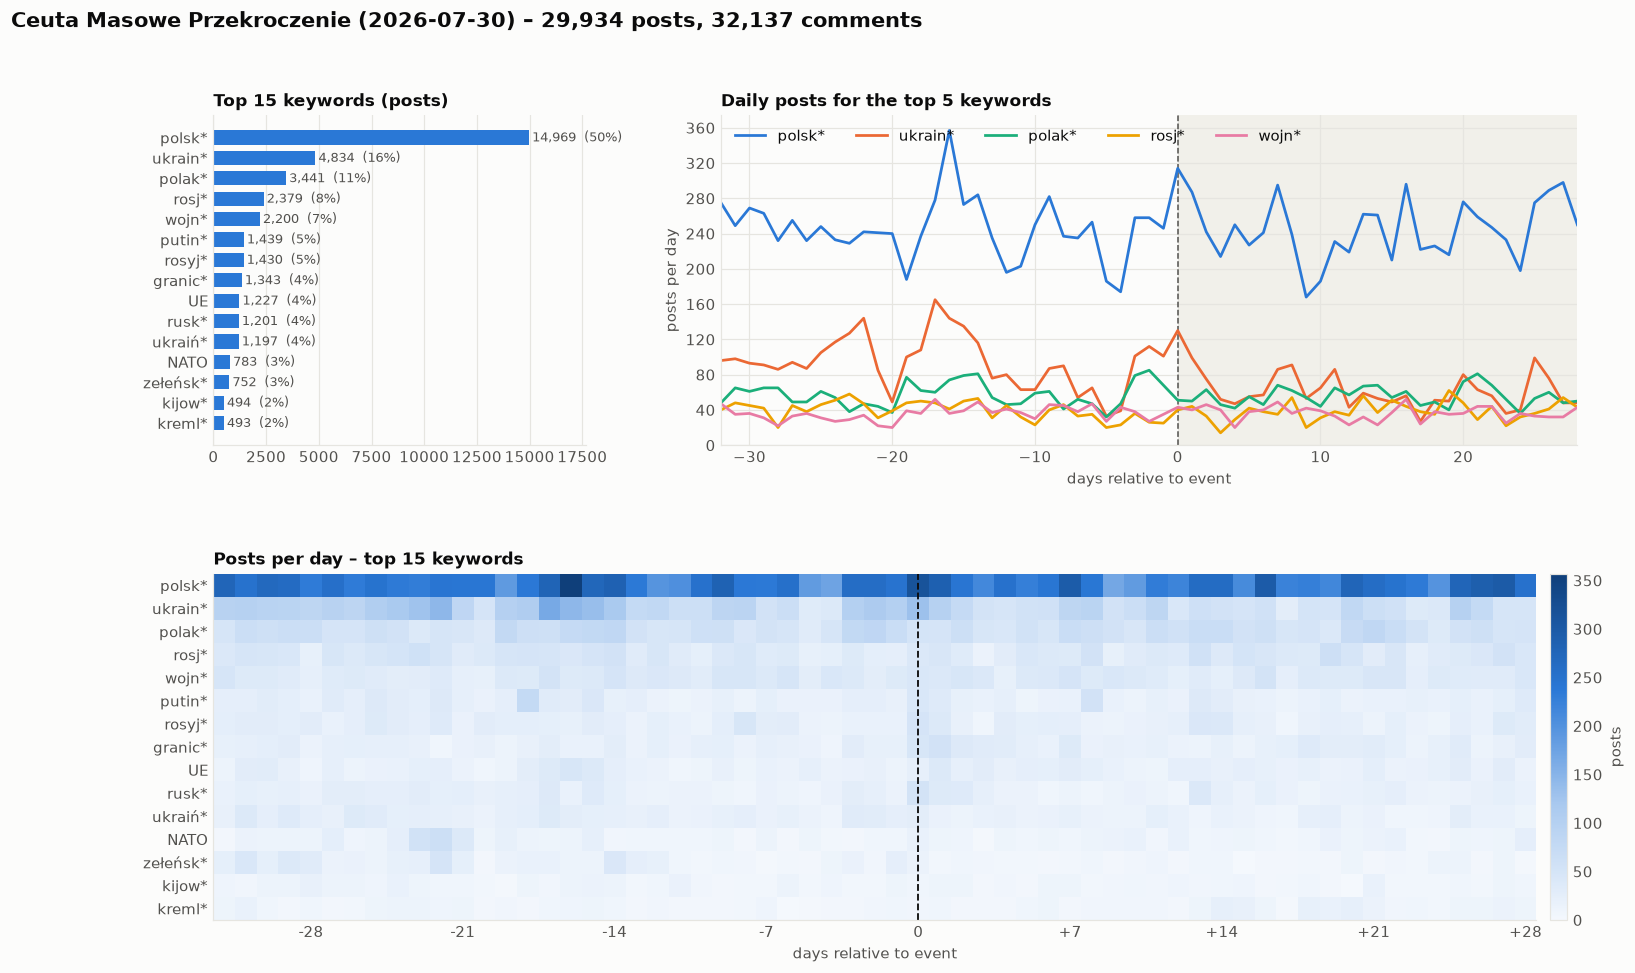

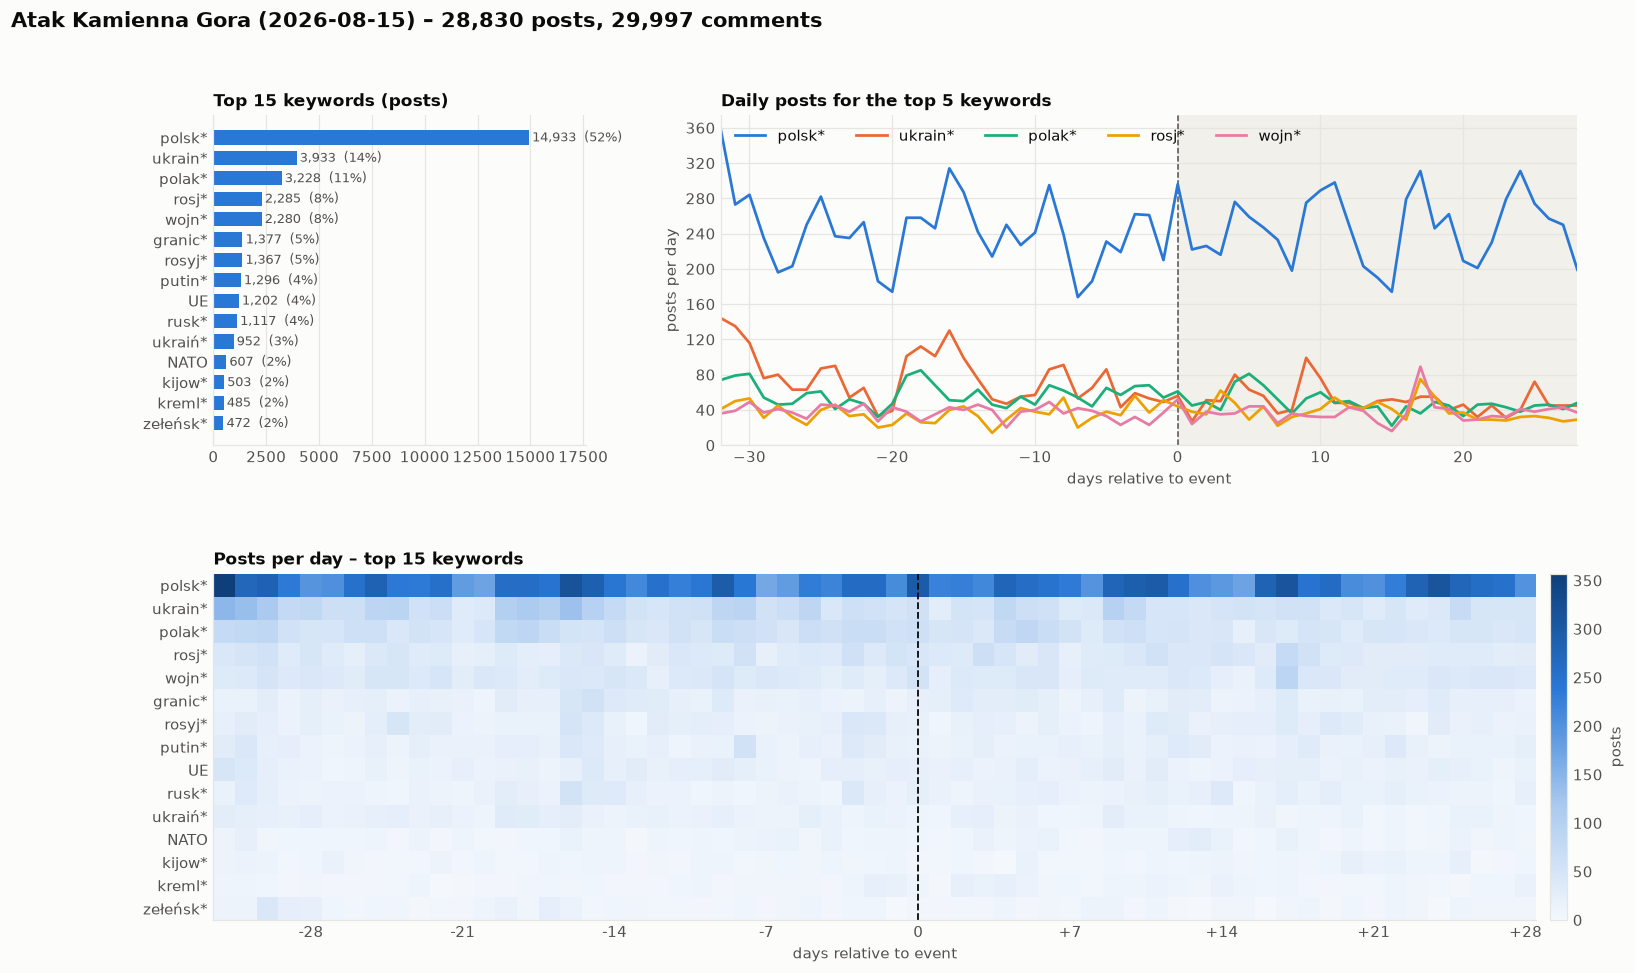

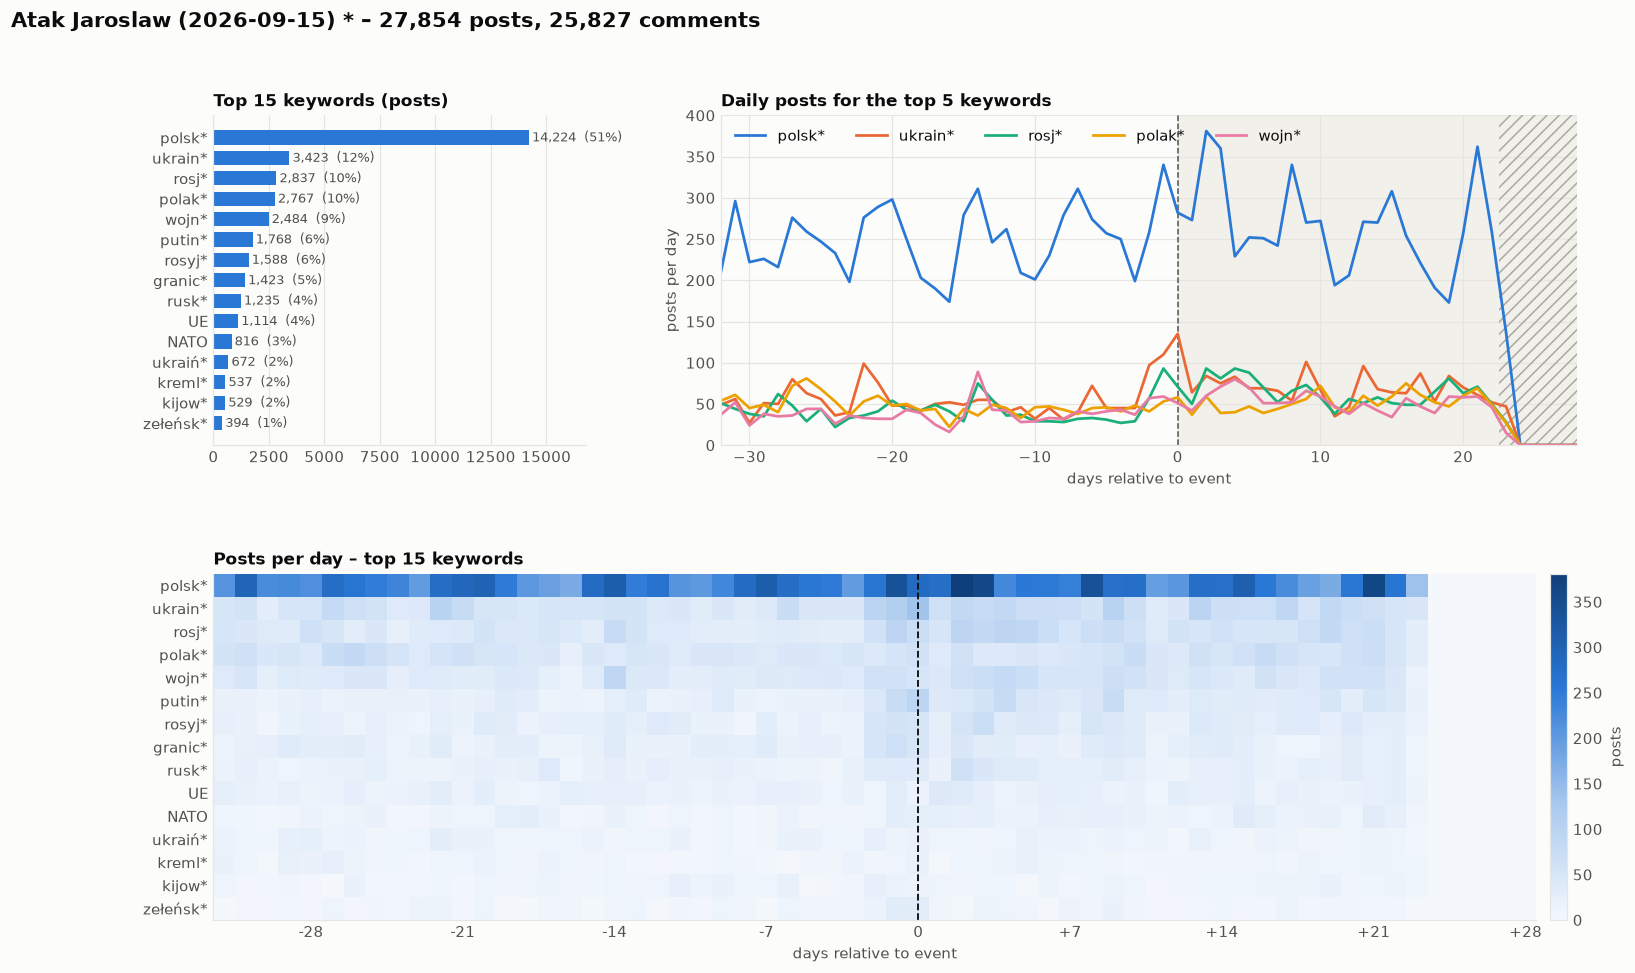

In [63]:
TOP_BAR, TOP_LINES, TOP_HEAT, SMOOTH = 15, 5, 15, 1

def plot_event_keywords(event):
    k = kw[kw['event'] == event]
    counts = k['keyword'].value_counts()
    lo, hi = DAY_RANGE.loc[event, 'min'], DAY_RANGE.loc[event, 'max']
    days = np.arange(min(lo, k['relative_day'].min()), hi + 1)
    by_day = (k.groupby(['relative_day', 'keyword']).size().unstack(fill_value=0)
              .reindex(days, fill_value=0))
    n_posts = summary.loc[event, 'posts']

    fig = plt.figure(figsize=(16, 9.5))
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.3], height_ratios=[1, 1.05], hspace=0.38, wspace=0.22)
    ax_bar, ax_line, ax_heat = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

    top = counts.head(TOP_BAR)
    hbar(ax_bar, top, color=SERIES[0], fmt='{:,.0f}')
    for t, (name, v) in zip(ax_bar.texts, top.items()):
        t.set_text(f'{v:,.0f}  ({v / n_posts * 100:.0f}%)')
    ax_bar.set_title(f'Top {len(top)} keywords (posts)')

    mark_event_day(ax_line, days.max())
    for i, name in enumerate(counts.index[:TOP_LINES]):
        s = by_day[name].rolling(SMOOTH, center=True, min_periods=1).mean()
        ax_line.plot(days, s, color=SERIES[i], lw=1.8, label=name)
    ax_line.set_ylim(bottom=0)
    ax_line.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    if LAST_DAY[event] < days.max():
        ax_line.axvspan(LAST_DAY[event] + 0.5, days.max(), facecolor='none', edgecolor=NEUTRAL, hatch='///', lw=0)
    ax_line.set_xlim(days.min(), days.max())
    ax_line.set_xlabel('days relative to event')
    ax_line.set_ylabel('posts per day')
    ax_line.legend(loc='upper left', ncol=min(TOP_LINES, 5))
    ax_line.set_title(f'Daily posts for the top {TOP_LINES} keywords' + (f' ({SMOOTH}-day mean)' if SMOOTH > 1 else ''))

    heat_kw = counts.index[:TOP_HEAT]
    M = by_day[heat_kw].T
    im = ax_heat.imshow(M.values, aspect='auto', cmap=SEQ, interpolation='nearest', vmin=0)
    ax_heat.set_yticks(range(len(heat_kw)), heat_kw)
    ticks = [i for i, d in enumerate(days) if d % 7 == 0]
    ax_heat.set_xticks(ticks, [f'{days[i]:+d}' if days[i] else '0' for i in ticks])
    ax_heat.axvline(list(days).index(0), color=TEXT_PRIMARY, lw=1.2, ls='--')
    ax_heat.grid(False)
    ax_heat.set_xlabel('days relative to event')
    ax_heat.set_title(f'Posts per day – top {len(heat_kw)} keywords')
    fig.colorbar(im, ax=ax_heat, fraction=0.02, pad=0.01).set_label('posts')

    fig.suptitle(f'{LABEL[event]} – {n_posts:,} posts, {summary.loc[event, "comments"]:,} comments',
                 x=0.01, ha='left')
    savefig(fig, f'11_keywords_{event}')
    plt.show()

for e in EVENTS:
    plot_event_keywords(e)

### 4.4 Which keywords gained share after the event?

Change in the share of posts mentioning a keyword, *after* vs *before* phase, in percentage points.
Only keywords with ≥ 10 matched posts in the event are considered. For small events (< 150 posts) the
differences are noisy.

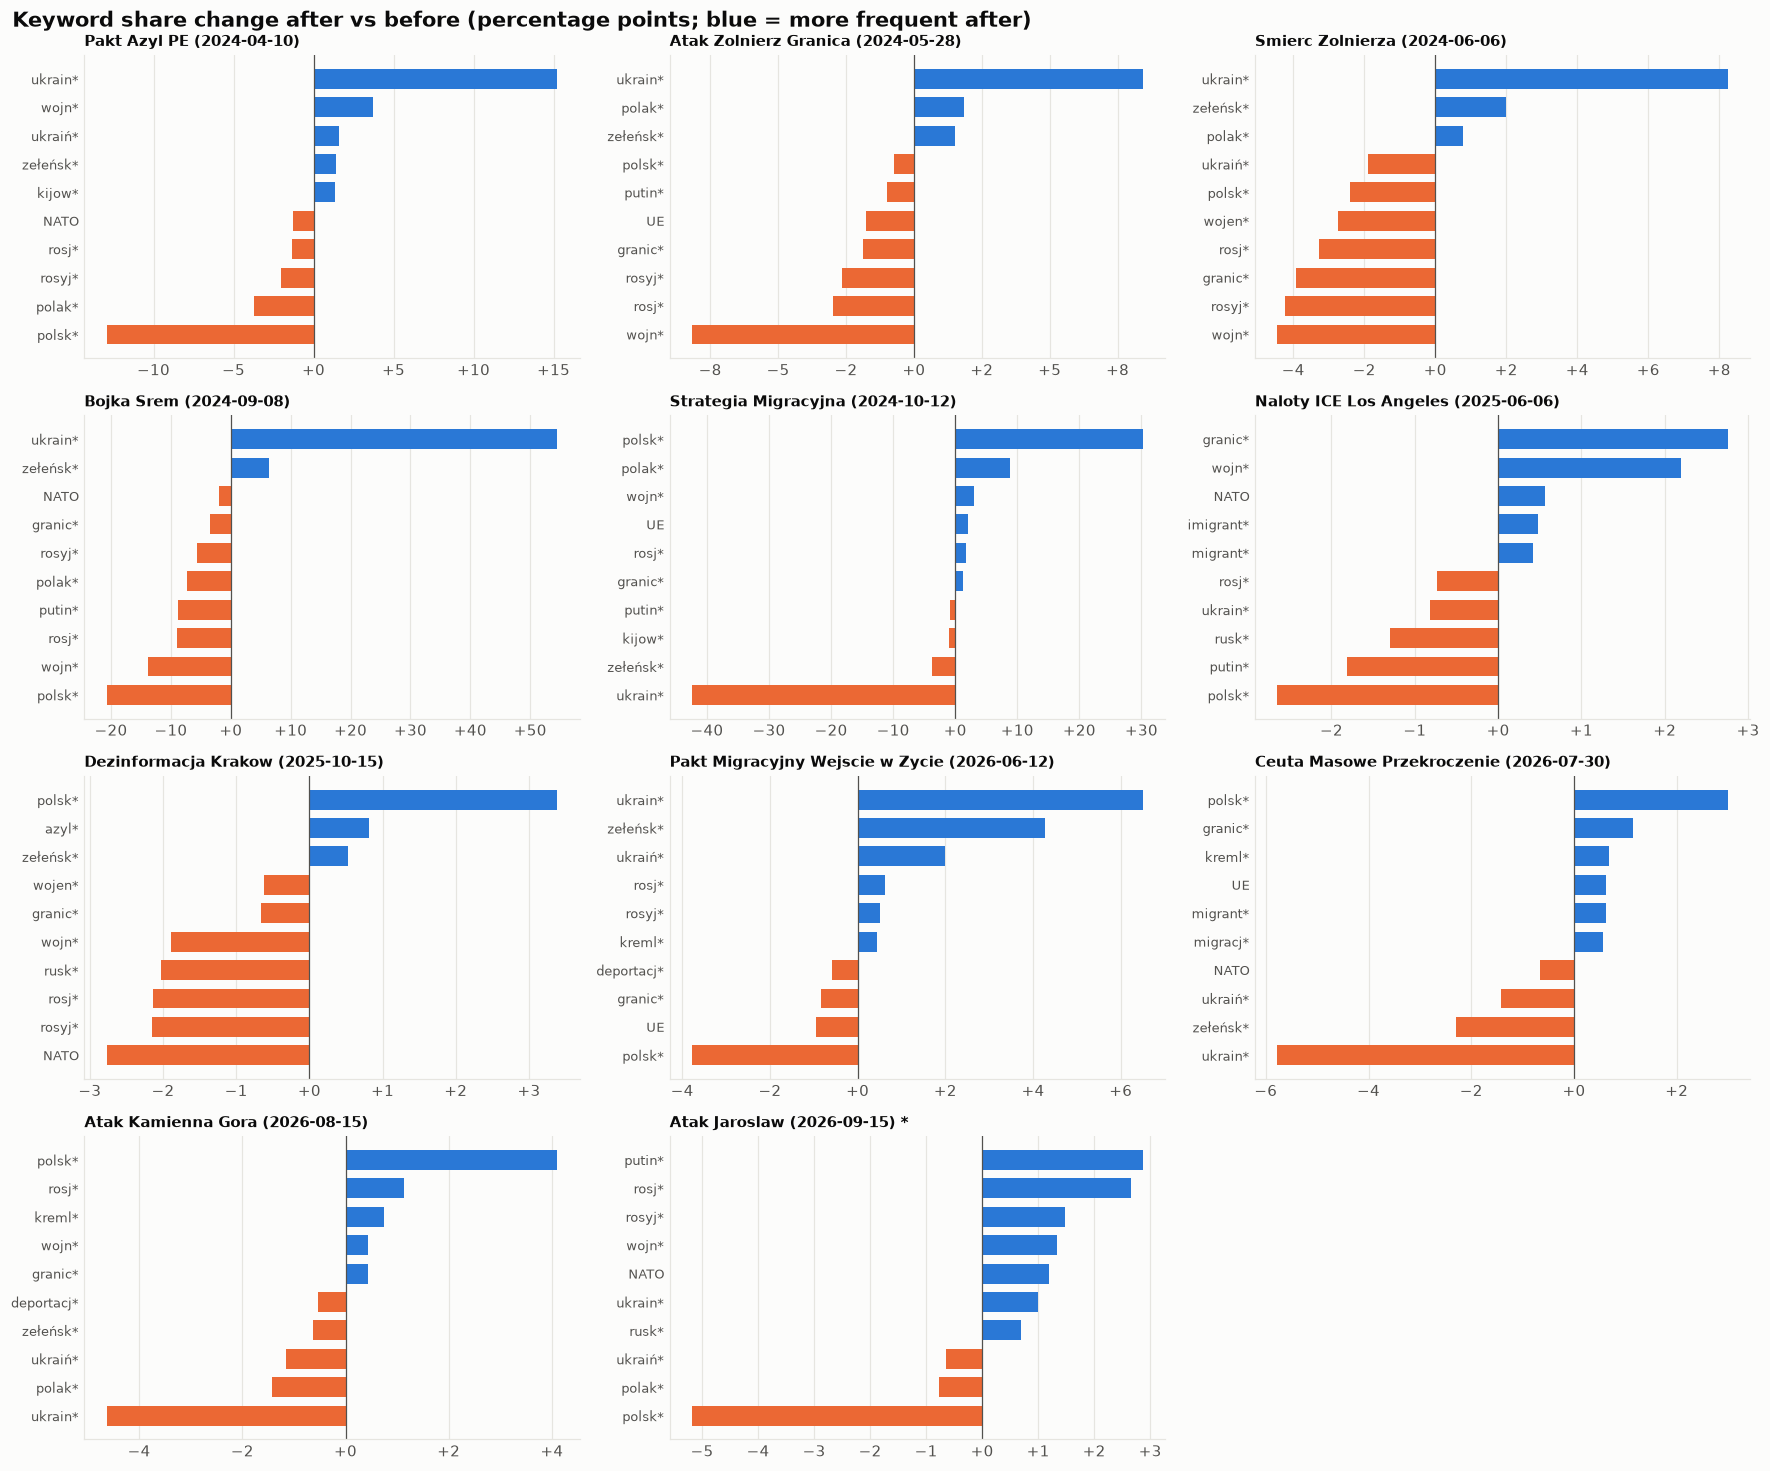

In [64]:
MIN_POSTS, TOP_SHIFT = 10, 10

def keyword_shift(e):
    p = posts[posts['event'] == e]
    k = kw[kw['event'] == e]
    n_before, n_after = (p['phase'] == 'before').sum(), (p['phase'] == 'after').sum()
    counts = k.groupby(['keyword', 'phase'])['post_id'].nunique().unstack(fill_value=0)
    for col in ('before', 'after'):
        if col not in counts:
            counts[col] = 0
    counts = counts[counts.sum(axis=1) >= MIN_POSTS]
    shift = counts['after'] / max(n_after, 1) * 100 - counts['before'] / max(n_before, 1) * 100
    return shift.reindex(shift.abs().sort_values(ascending=False).index).head(TOP_SHIFT)

fig, axes = small_multiples(len(EVENTS), ncols=3, w=5.4, h=3.4)
shifts = {}
for ax, e in zip(axes, EVENTS):
    s = keyword_shift(e).sort_values()
    shifts[e] = s
    ax.barh(range(len(s)), s.values, color=np.where(s.values >= 0, POS, NEG), height=0.7)
    ax.set_yticks(range(len(s)), s.index, fontsize=8.5)
    ax.axvline(0, color=TEXT_SECONDARY, lw=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_title(LABEL[e], fontsize=9.5)
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:+.0f}'))
fig.suptitle('Keyword share change after vs before (percentage points; blue = more frequent after)',
             x=0.01, ha='left')
fig.tight_layout()
savefig(fig, '12_keyword_shift')

### 4.5 Keyword co-occurrence

How often two keywords are matched by the same post (Jaccard index: posts with both / posts with either).

keyword  keyword 
rosj*    rosyj*      11.5
ukrain*  rosj*       10.0
rosj*    putin*       8.9
rosyj*   ukraiń*      8.2
ukrain*  zełeńsk*     7.6
wojn*    rosj*        7.3
ukrain*  ukraiń*      7.3
         putin*       6.9
         wojn*        6.8
         rosyj*       6.3
Name: jaccard_%, dtype: float64

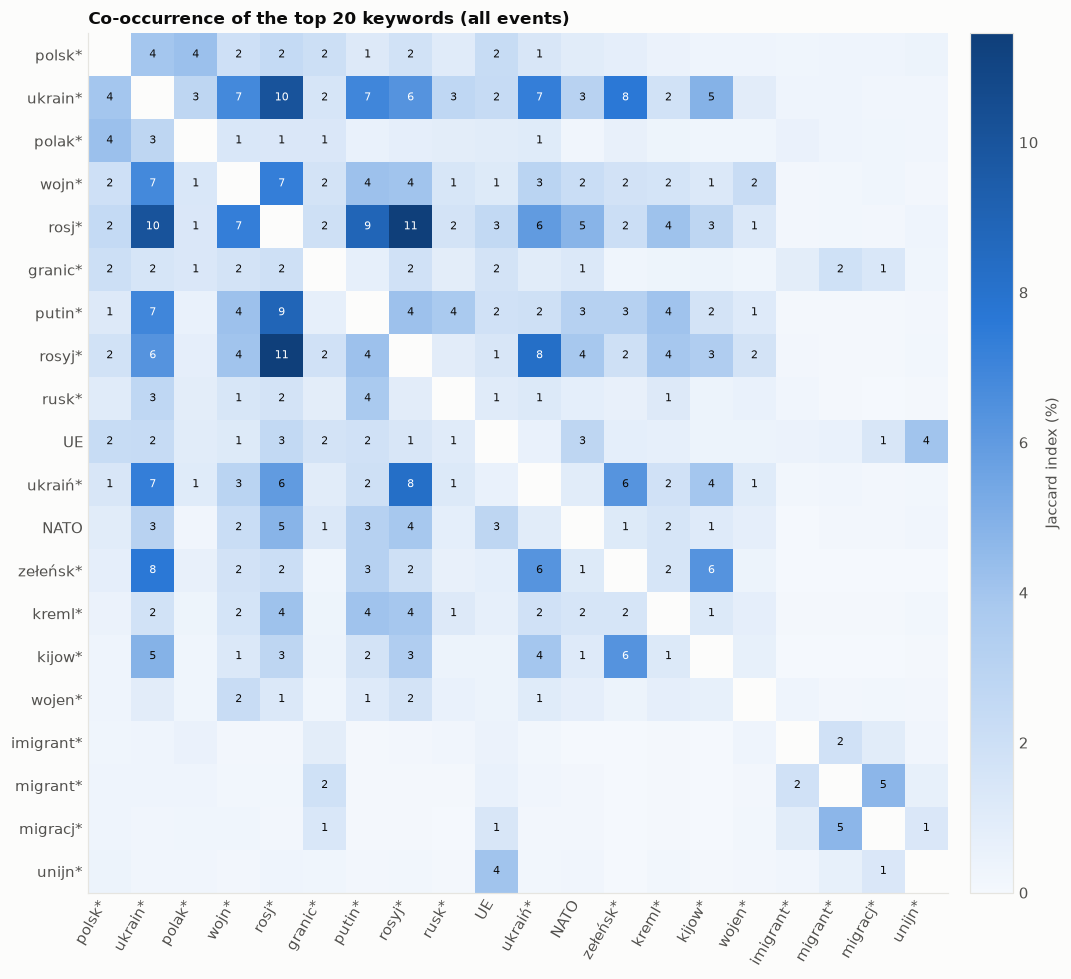

In [65]:
TOP_CO = 20
top_kw = kw_total.head(TOP_CO).index
sets = {k: set(kw.loc[kw['keyword'] == k, 'post_id'] + '|' + kw.loc[kw['keyword'] == k, 'event']) for k in top_kw}
jac = pd.DataFrame(0.0, index=top_kw, columns=top_kw)
for a in top_kw:
    for b in top_kw:
        if a != b:
            jac.loc[a, b] = len(sets[a] & sets[b]) / len(sets[a] | sets[b]) * 100
mask = np.eye(len(top_kw), dtype=bool)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.ma.masked_array(jac.values, mask), cmap=SEQ, vmin=0)
ax.set_xticks(range(len(top_kw)), top_kw, rotation=60, ha='right')
ax.set_yticks(range(len(top_kw)), top_kw)
ax.grid(False)
for i in range(len(top_kw)):
    for j in range(len(top_kw)):
        if i != j and jac.iat[i, j] >= 1:
            ax.text(j, i, f'{jac.iat[i, j]:.0f}', ha='center', va='center', fontsize=7,
                    color='white' if jac.iat[i, j] > jac.values.max() * 0.55 else TEXT_PRIMARY)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label('Jaccard index (%)')
ax.set_title(f'Co-occurrence of the top {TOP_CO} keywords (all events)')
fig.tight_layout()
savefig(fig, '13_keyword_cooccurrence')

pairs = (jac.where(np.triu(np.ones(jac.shape, dtype=bool), 1)).stack()
         .sort_values(ascending=False).head(10).round(1).rename('jaccard_%'))
pairs

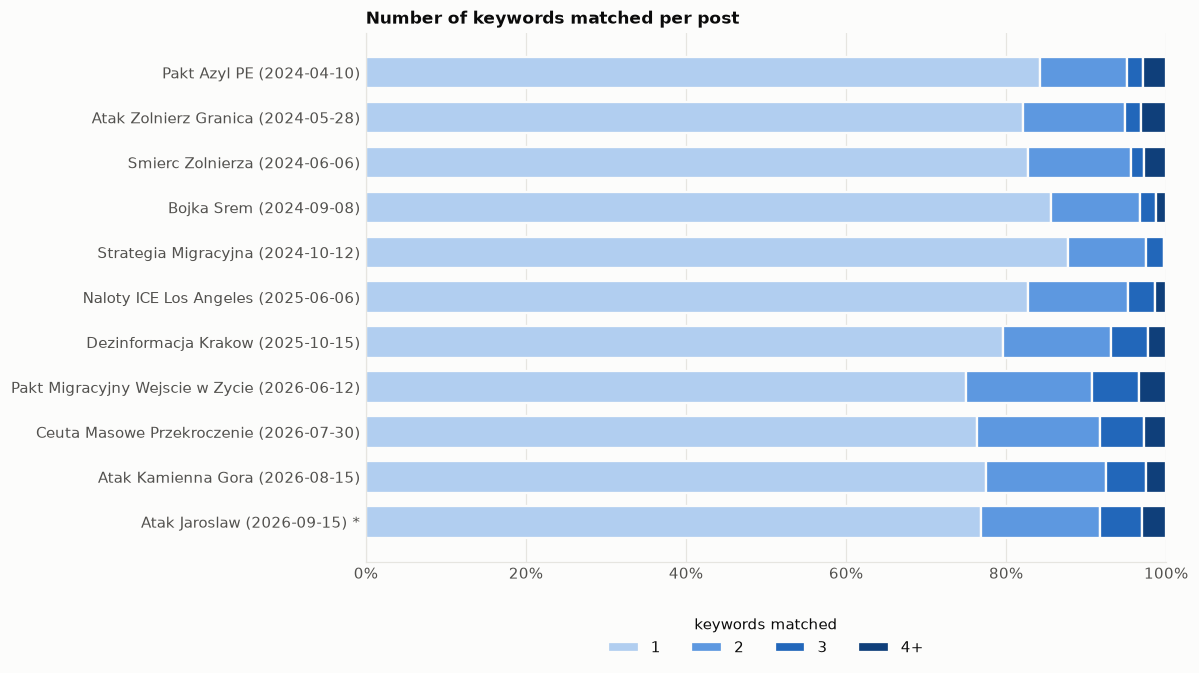

In [66]:
# How many keywords does a single post match?
nk = posts.assign(n=posts['n_keywords'].clip(upper=4)).groupby(['event', 'n']).size().unstack(fill_value=0)
nk = nk.reindex(EVENTS).div(nk.reindex(EVENTS).sum(axis=1), axis=0) * 100
cats = {1: '1', 2: '2', 3: '3', 4: '4+'}
seq_colors = [SEQ(x) for x in np.linspace(0.3, 1, nk.shape[1])]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(EVENTS) + 1.6))
left = np.zeros(len(EVENTS))
for c, col in zip(nk.columns, seq_colors):
    ax.barh(range(len(EVENTS)), nk[c].values, left=left, color=col, height=0.7,
            edgecolor=SURFACE, linewidth=1.5, label=cats[c])
    left += nk[c].values
ax.set_yticks(range(len(EVENTS)), LABELS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', visible=False)
ax.legend(title='keywords matched', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_title('Number of keywords matched per post')
fig.tight_layout()
savefig(fig, '14_keywords_per_post')

## 5. Engagement

`engagement = likes + reposts + replies + quotes`. Engagement distributions are extremely skewed – medians and
the share of posts with zero interaction tell more than means.

In [67]:
eng = posts.groupby('event').agg(
    posts=('post_id', 'size'),
    median_likes=('likes', 'median'),
    mean_likes=('likes', 'mean'),
    p90_likes=('likes', lambda s: s.quantile(0.9)),
    max_likes=('likes', 'max'),
    mean_reposts=('reposts', 'mean'),
    mean_replies=('replies', 'mean'),
    zero_engagement_pct=('engagement', lambda s: (s == 0).mean() * 100),
    reply_posts_pct=('is_reply', lambda s: s.mean() * 100),
).reindex(EVENTS)
eng.round(2)

,posts,median_likes,mean_likes,p90_likes,max_likes,mean_reposts,mean_replies,zero_engagement_pct,reply_posts_pct
event,,,,,,,,,
Pakt_Azyl_PE,766,0.0,0.64,2.0,10,0.09,0.15,61.10,11.36
Atak_Zolnierz_Granica,785,1.0,1.04,3.0,48,0.20,0.10,44.59,8.79
Smierc_Zolnierza,748,1.0,1.13,3.0,48,0.19,0.12,39.30,9.63
Bojka_Srem,627,0.0,1.14,3.0,39,0.17,0.30,51.83,21.37
Strategia_Migracyjna,1368,1.0,1.49,4.0,51,0.19,0.39,42.18,27.34
Naloty_ICE_Los_Angeles,48666,1.0,6.62,15.0,956,0.89,0.84,22.86,50.91
Dezinformacja_Krakow,31353,1.0,5.29,14.0,1946,0.71,0.72,23.88,42.89
Pakt_Migracyjny_Wejscie_w_Zycie,32696,1.0,4.31,11.0,212,0.55,0.72,28.59,47.02
Ceuta_Masowe_Przekroczenie,29934,1.0,4.35,10.0,177,0.58,0.71,30.72,44.71


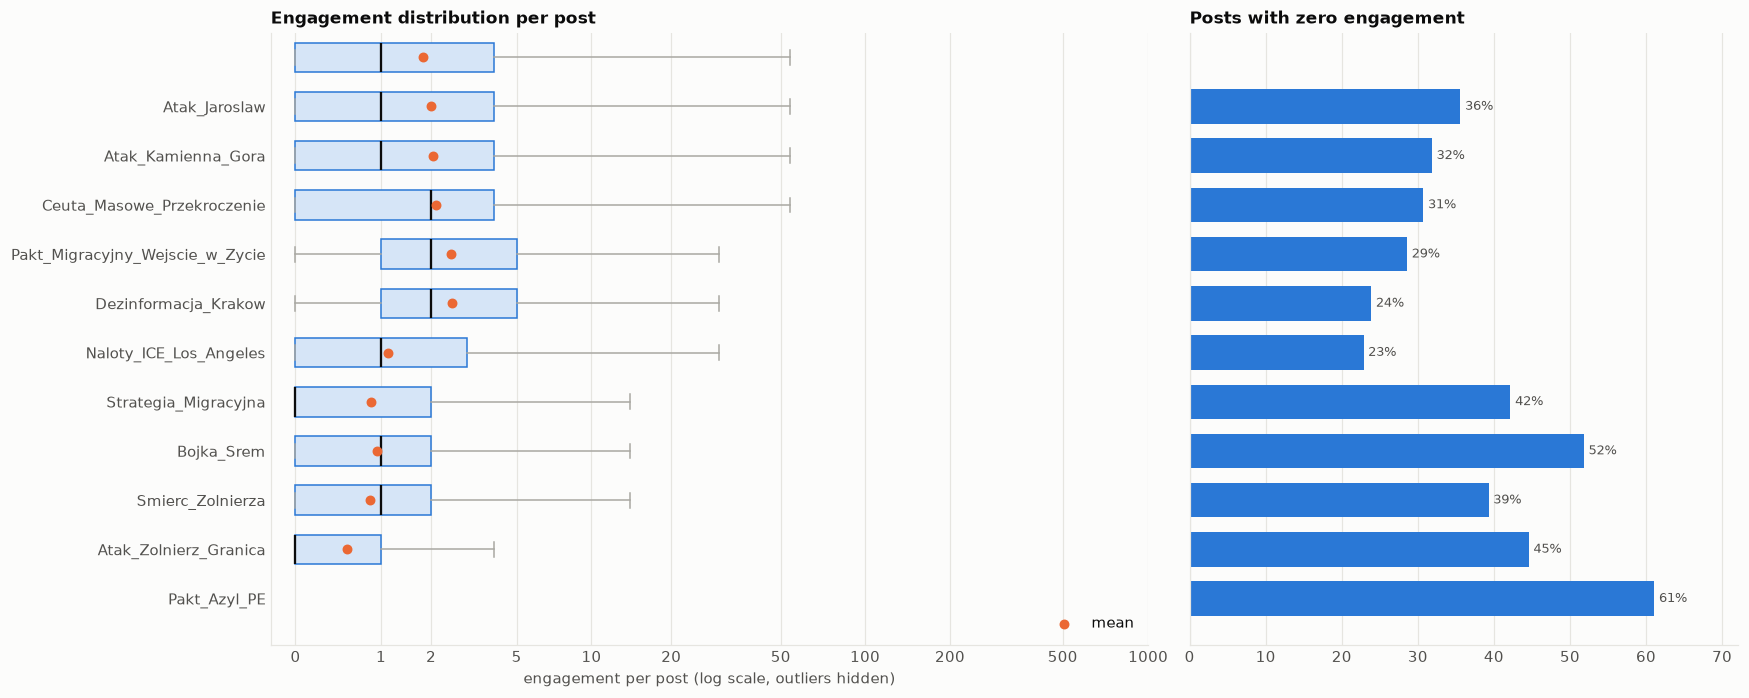

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(EVENTS) + 1.5), sharey=True,
                         gridspec_kw={'width_ratios': [1.6, 1]})
data = [np.log10(1 + posts.loc[posts['event'] == e, 'engagement']) for e in EVENTS]
bp = axes[0].boxplot(data, orientation='horizontal', showfliers=False, patch_artist=True, widths=0.6,
                     medianprops=dict(color=TEXT_PRIMARY, lw=1.5), whiskerprops=dict(color=NEUTRAL),
                     capprops=dict(color=NEUTRAL), boxprops=dict(edgecolor=SERIES[0]))
for b in bp['boxes']:
    b.set_facecolor('#d6e5f7')
means = [d.mean() for d in data]
axes[0].scatter(means, range(1, len(EVENTS) + 1), color=SERIES[1], s=30, zorder=3, label='mean')
axes[0].set_yticks(range(1, len(EVENTS) + 1), LABELS)
axes[0].invert_yaxis()
ticks = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
axes[0].set_xticks(np.log10(1 + np.array(ticks)), ticks)
axes[0].set_xlabel('engagement per post (log scale, outliers hidden)')
axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='lower right')
axes[0].set_title('Engagement distribution per post')

hbar(axes[1], eng['zero_engagement_pct'], None, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Posts with zero engagement')
axes[1].tick_params(labelleft=False)
fig.tight_layout()
savefig(fig, '15_engagement')

phase,before,day_0,after
event,,,
Pakt_Azyl_PE,0.88,0.75,0.89
Atak_Zolnierz_Granica,1.13,1.36,1.62
Smierc_Zolnierza,1.23,1.09,1.78
Bojka_Srem,2.13,0.74,1.43
Strategia_Migracyjna,1.46,2.11,2.41
Naloty_ICE_Los_Angeles,9.35,6.63,7.10
Dezinformacja_Krakow,6.60,6.44,7.00
Pakt_Migracyjny_Wejscie_w_Zycie,5.65,5.15,5.62
Ceuta_Masowe_Przekroczenie,5.41,5.74,6.02


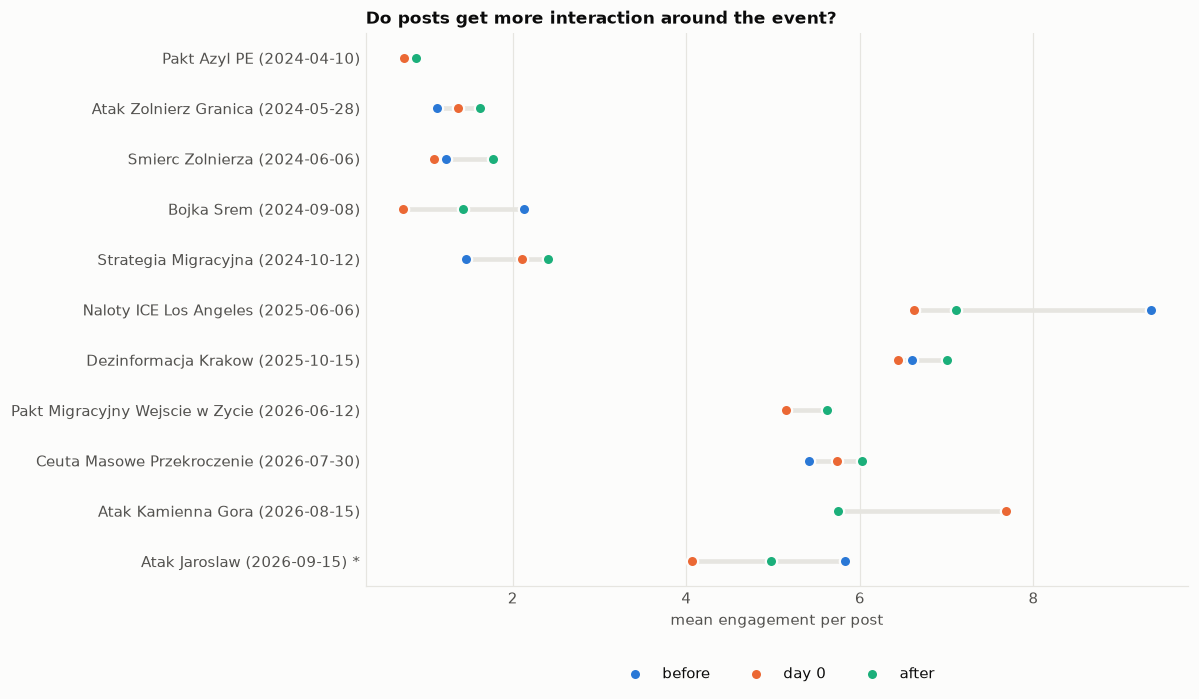

In [69]:
# Mean engagement per post by phase
ph = posts.groupby(['event', 'phase'])['engagement'].mean().unstack().reindex(EVENTS)[['before', 'day_0', 'after']]

fig, ax = plt.subplots(figsize=(11, 0.45 * len(EVENTS) + 1.5))
y = np.arange(len(EVENTS))
ax.hlines(y, ph.min(axis=1), ph.max(axis=1), color=GRID, lw=3)
for i, c in enumerate(ph.columns):
    ax.scatter(ph[c], y, s=55, color=SERIES[i], label=c.replace('_', ' '), zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y, LABELS)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlabel('mean engagement per post')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.set_title('Do posts get more interaction around the event?')
fig.tight_layout()
savefig(fig, '16_engagement_by_phase')
ph.round(2)

In [70]:
# Correlation between engagement metrics (Spearman, all posts)
posts[['likes', 'reposts', 'replies', 'quotes', 'comments_in_thread', 'comments_in_rule', 'text_len', 'n_keywords']] \
    .corr(method='spearman').round(2)

,likes,reposts,replies,quotes,comments_in_thread,comments_in_rule,text_len,n_keywords
likes,1.00,0.56,0.39,0.24,0.35,0.32,0.13,-0.01
reposts,0.56,1.00,0.23,0.29,0.19,0.17,0.15,0.08
replies,0.39,0.23,1.00,0.17,0.95,0.88,0.17,-0.02
quotes,0.24,0.29,0.17,1.00,0.15,0.13,0.06,0.03
comments_in_thread,0.35,0.19,0.95,0.15,1.00,0.93,0.17,-0.02
comments_in_rule,0.32,0.17,0.88,0.13,0.93,1.00,0.16,-0.01
text_len,0.13,0.15,0.17,0.06,0.17,0.16,1.00,0.11
n_keywords,-0.01,0.08,-0.02,0.03,-0.02,-0.01,0.11,1.00


## 6. Authors – how concentrated is the activity?

A handful of very active accounts can dominate keyword-based samples. Gini = 0 means every author posted the
same amount; close to 1 means a few authors produced almost everything.

In [71]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

def concentration(df):
    per_author = df.groupby('author_id').size().sort_values(ascending=False)
    n = len(per_author)
    return pd.Series({
        'authors': n,
        'items_per_author': per_author.mean(),
        'max_by_one_author': per_author.iloc[0] if n else 0,
        'top10_authors_%': per_author.head(10).sum() / per_author.sum() * 100 if n else np.nan,
        'top1pct_authors_%': per_author.head(max(1, n // 100)).sum() / per_author.sum() * 100 if n else np.nan,
        'single_item_authors_%': (per_author == 1).mean() * 100 if n else np.nan,
        'gini': gini(per_author.values),
    })

conc_posts = pd.DataFrame({e: concentration(posts[posts['event'] == e]) for e in EVENTS}).T
conc_comm = pd.DataFrame({e: concentration(comments[comments['event'] == e]) for e in EVENTS}).T
display(Markdown('**Posts**'))
display(conc_posts.round(2))
display(Markdown('**Comments**'))
display(conc_comm.round(2))

**Posts**

,authors,items_per_author,max_by_one_author,top10_authors_%,top1pct_authors_%,single_item_authors_%,gini
Pakt_Azyl_PE,45.0,17.02,286.0,91.38,37.34,44.44,0.85
Atak_Zolnierz_Granica,50.0,15.70,413.0,91.34,52.61,44.00,0.87
Smierc_Zolnierza,52.0,14.38,434.0,91.18,58.02,46.15,0.87
Bojka_Srem,81.0,7.74,271.0,81.82,43.22,61.73,0.80
Strategia_Migracyjna,272.0,5.03,514.0,59.87,42.25,65.44,0.75
Naloty_ICE_Los_Angeles,3529.0,13.79,965.0,8.90,19.99,32.87,0.75
Dezinformacja_Krakow,2161.0,14.51,873.0,15.40,22.85,31.42,0.75
Pakt_Migracyjny_Wejscie_w_Zycie,1711.0,19.11,762.0,16.41,23.75,31.79,0.78
Ceuta_Masowe_Przekroczenie,1575.0,19.01,618.0,16.37,22.25,29.97,0.78
Atak_Kamienna_Gora,1546.0,18.65,545.0,16.60,23.01,28.72,0.78


**Comments**

,authors,items_per_author,max_by_one_author,top10_authors_%,top1pct_authors_%,single_item_authors_%,gini
Pakt_Azyl_PE,24.0,9.75,49.0,88.89,20.94,37.50,0.64
Atak_Zolnierz_Granica,25.0,4.56,27.0,81.58,23.68,44.00,0.58
Smierc_Zolnierza,26.0,5.42,32.0,80.85,22.70,38.46,0.58
Bojka_Srem,36.0,7.03,48.0,75.10,18.97,22.22,0.62
Strategia_Migracyjna,152.0,5.12,82.0,55.14,10.54,47.37,0.68
Naloty_ICE_Los_Angeles,2787.0,22.50,717.0,8.81,17.72,27.13,0.77
Dezinformacja_Krakow,1601.0,20.32,849.0,11.86,16.34,26.61,0.75
Pakt_Migracyjny_Wejscie_w_Zycie,1279.0,27.63,1338.0,14.58,16.34,25.88,0.77
Ceuta_Masowe_Przekroczenie,1223.0,26.28,1001.0,15.23,17.48,23.06,0.77
Atak_Kamienna_Gora,1178.0,25.46,984.0,15.31,16.35,22.84,0.76


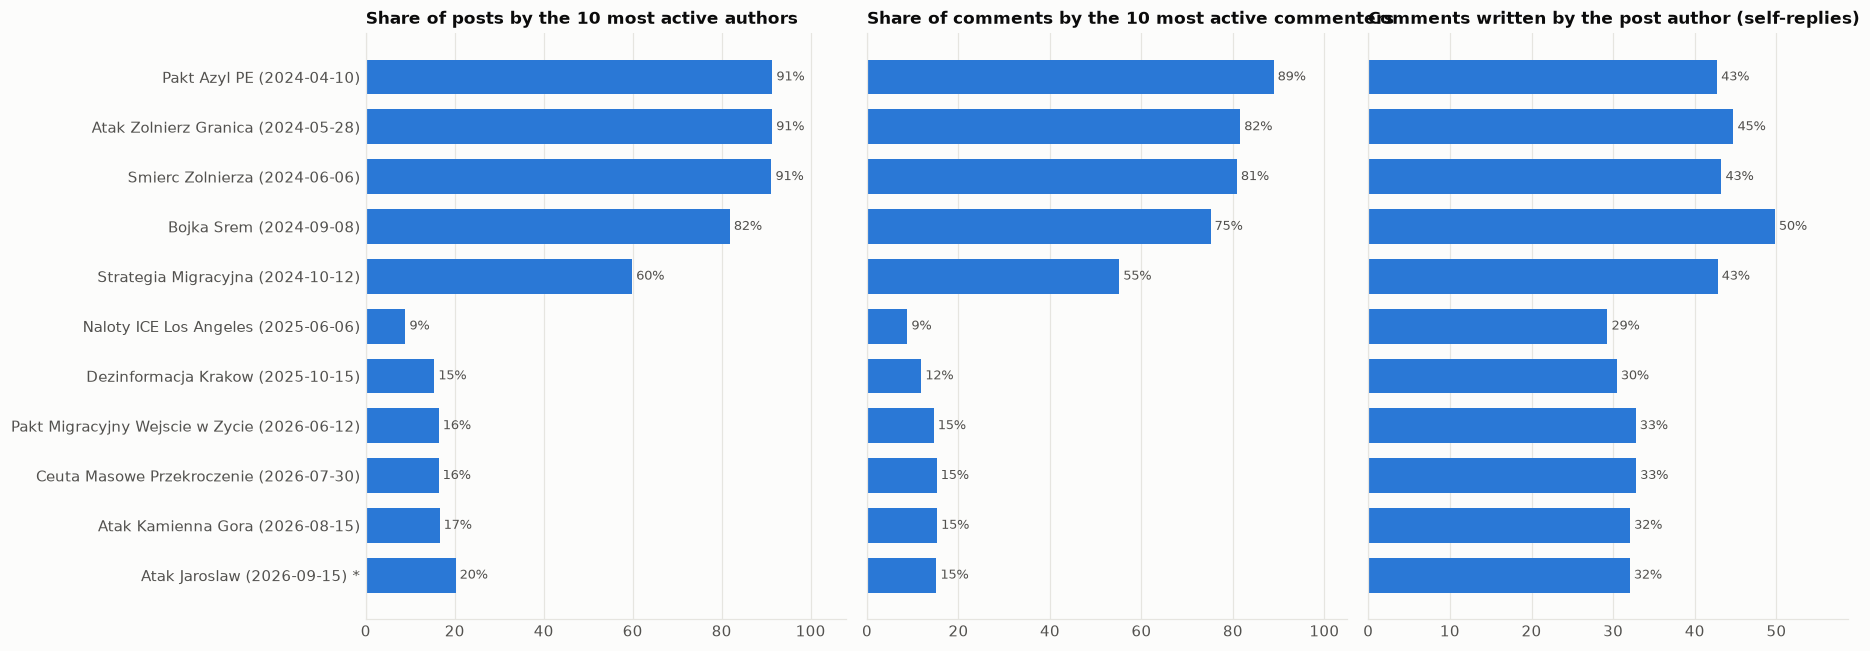

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(17, 0.42 * len(EVENTS) + 1.4), sharey=True)
hbar(axes[0], conc_posts['top10_authors_%'], LABELS, SERIES[0], fmt='{:.0f}%')
axes[0].set_title('Share of posts by the 10 most active authors')
hbar(axes[1], conc_comm['top10_authors_%'], LABELS, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Share of comments by the 10 most active commenters')
self_reply = comments.groupby('event')['is_material_author'].mean().reindex(EVENTS) * 100
hbar(axes[2], self_reply, LABELS, SERIES[0], fmt='{:.0f}%')
axes[2].set_title('Comments written by the post author (self-replies)')
fig.tight_layout()
savefig(fig, '17_author_concentration')

## 7. Conversations

`depth` = position in the reply tree (1 = direct reply to the post). `material_age_days` = how long after the
post the comment was written.

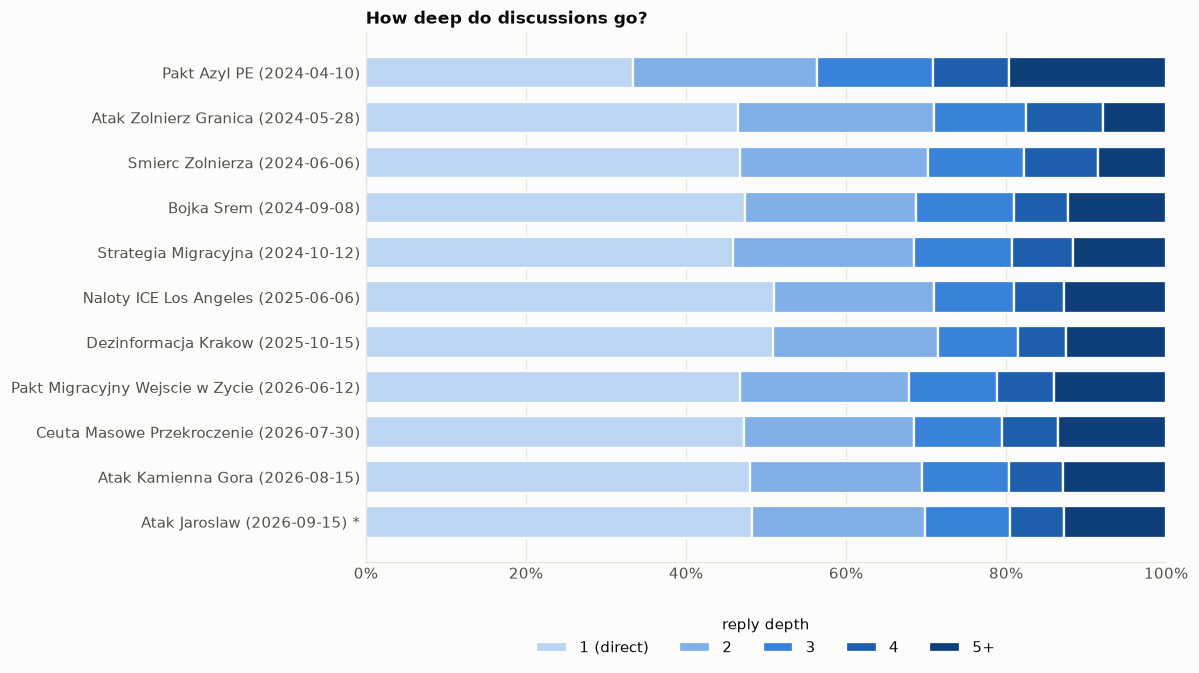

In [73]:
depth = comments.assign(d=comments['depth'].clip(upper=5)).groupby(['event', 'd']).size().unstack(fill_value=0)
depth = depth.reindex(EVENTS).fillna(0)
depth_share = depth.div(depth.sum(axis=1).replace(0, np.nan), axis=0) * 100
labels_d = {1: '1 (direct)', 2: '2', 3: '3', 4: '4', 5: '5+'}
seq_colors = [SEQ(x) for x in np.linspace(0.25, 1, depth_share.shape[1])]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(EVENTS) + 1.6))
left = np.zeros(len(EVENTS))
for c, col in zip(depth_share.columns, seq_colors):
    vals = depth_share[c].fillna(0).values
    ax.barh(range(len(EVENTS)), vals, left=left, color=col, height=0.7,
            edgecolor=SURFACE, linewidth=1.5, label=labels_d[c])
    left += vals
ax.set_yticks(range(len(EVENTS)), LABELS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', visible=False)
ax.legend(title='reply depth', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5)
ax.set_title('How deep do discussions go?')
fig.tight_layout()
savefig(fig, '19_depth')

,median_h,p75_h,p90_h,within_1h_pct,within_24h_pct
event,,,,,
Pakt_Azyl_PE,1.16,5.38,10.22,48.72,97.44
Atak_Zolnierz_Granica,1.43,7.82,19.65,42.11,94.74
Smierc_Zolnierza,1.51,7.85,19.27,41.84,95.74
Bojka_Srem,1.22,7.34,20.85,47.43,97.63
Strategia_Migracyjna,1.08,7.99,21.92,48.33,92.29
Naloty_ICE_Los_Angeles,1.08,4.46,13.51,48.60,96.97
Dezinformacja_Krakow,1.20,4.54,12.77,46.41,97.23
Pakt_Migracyjny_Wejscie_w_Zycie,1.13,4.49,13.18,47.59,96.47
Ceuta_Masowe_Przekroczenie,1.46,5.59,15.05,43.42,96.13


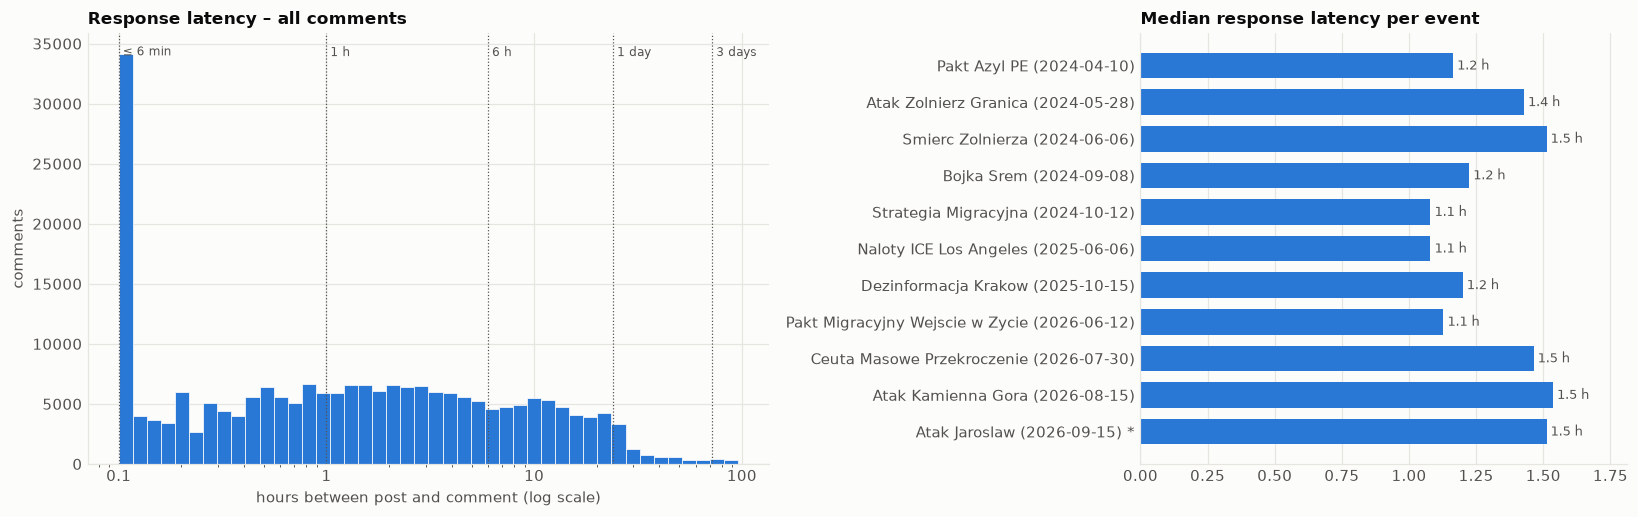

In [74]:
lat = comments.groupby('event')['latency_h'].agg(
    median_h='median',
    p75_h=lambda s: s.quantile(0.75),
    p90_h=lambda s: s.quantile(0.9),
    within_1h_pct=lambda s: (s <= 1).mean() * 100,
    within_24h_pct=lambda s: (s <= 24).mean() * 100,
).reindex(EVENTS)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
# material_age_days has 0.001-day (~1.4 min) resolution, so everything under 6 min goes into the first bin
bins = np.logspace(np.log10(0.1), np.log10(96), 45)
axes[0].hist(comments['latency_h'].clip(lower=0.1), bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
axes[0].set_xscale('log')
for v, name in [(0.1, '≤ 6 min'), (1, '1 h'), (6, '6 h'), (24, '1 day'), (72, '3 days')]:
    axes[0].axvline(v, color=TEXT_SECONDARY, lw=0.8, ls=':')
    axes[0].text(v, axes[0].get_ylim()[1] * 0.97, f' {name}', fontsize=8, color=TEXT_SECONDARY, va='top')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:g}'))
axes[0].set_xlabel('hours between post and comment (log scale)')
axes[0].set_ylabel('comments')
axes[0].set_title('Response latency – all comments')

hbar(axes[1], lat['median_h'], LABELS, SERIES[0], fmt='{:.1f} h')
axes[1].set_title('Median response latency per event')
fig.tight_layout()
savefig(fig, '20_latency')
lat.round(2)

In [75]:
# Comments per thread & coverage of fetched threads vs. replies reported by Bluesky
thr = posts[posts['comments_in_rule'] > 0].groupby('event')['comments_in_rule'].describe(
    percentiles=[0.5, 0.9, 0.99])[['count', 'mean', '50%', '90%', '99%', 'max']]
thr.columns = ['threads_w_comments', 'mean', 'median', 'p90', 'p99', 'max']

cov = pd.DataFrame({
    e: pd.DataFrame(reports.get(e, {}).get('threads', []) or [{'reported_replies': 0, 'fetched_comments': 0, 'in_rule': 0}])
       [['reported_replies', 'fetched_comments', 'in_rule']].sum()
    for e in EVENTS}).T
cov['fetched_vs_reported_%'] = cov['fetched_comments'] / cov['reported_replies'].replace(0, np.nan) * 100
cov['in_rule_vs_fetched_%'] = cov['in_rule'] / cov['fetched_comments'].replace(0, np.nan) * 100
thr.reindex(EVENTS).join(cov).round(1)

,threads_w_comments,mean,median,p90,p99,max,reported_replies,fetched_comments,in_rule,fetched_vs_reported_%,in_rule_vs_fetched_%
event,,,,,,,,,,,
Pakt_Azyl_PE,70.0,3.9,2.0,9.1,17.6,19.0,114,324,273,284.2,84.3
Atak_Zolnierz_Granica,51.0,2.7,2.0,6.0,13.0,14.0,77,173,139,224.7,80.3
Smierc_Zolnierza,60.0,2.8,2.0,6.0,12.8,14.0,89,198,166,222.5,83.8
Bojka_Srem,101.0,3.0,2.0,8.0,14.0,21.0,186,400,298,215.1,74.5
Strategia_Migracyjna,301.0,3.4,2.0,8.0,17.0,24.0,538,1244,1011,231.2,81.3
Naloty_ICE_Los_Angeles,17401.0,4.4,2.0,10.0,34.0,177.0,40990,85543,76125,208.7,89.0
Dezinformacja_Krakow,9699.0,4.1,2.0,9.0,32.0,197.0,22439,46844,40034,208.8,85.5
Pakt_Migracyjny_Wejscie_w_Zycie,11218.0,4.6,2.0,10.0,32.8,170.0,23452,61410,52047,261.9,84.8
Ceuta_Masowe_Przekroczenie,9716.0,4.5,2.0,10.0,32.0,146.0,21115,53634,44006,254.0,82.0


In [76]:
# Most discussed posts overall
most_discussed = posts.sort_values('comments_in_rule', ascending=False).head(15)
most_discussed.assign(text=most_discussed['text'].map(short))[
    ['event', 'relative_day', 'comments_in_rule', 'comments_in_thread', 'likes', 'keywords', 'text', 'link']
].reset_index(drop=True)

,event,relative_day,comments_in_rule,comments_in_thread,likes,keywords,text,link
0,Dezinformacja_Krakow,10,197,211,19,polsk*,"Bluesky niestety umiera Od początku roku prawie o połowę spadła liczba użytkowników platformy Bluesky, która miała być alternatywą dla X...",https://bsky.app/profile/did:plc:gomvav734ajsr3me2pjrl3ua/post/3m3z66gmads2h
1,Naloty_ICE_Los_Angeles,26,177,241,314,migrant*|granic*|Straż Graniczna|polsk*,"Im bardziej państwo polskie odzyskuje kontrolę na granicach, tym mocniej jest atakowane przez PiS, Konfederację i ich bojówki. Wpierw wp...",https://bsky.app/profile/did:plc:2wrsehnu74dmbuwa5t43i3ts/post/3lsy5hr3cck2z
2,Pakt_Migracyjny_Wejscie_w_Zycie,-4,170,172,81,polsk*,"Ponieważ ostatnio tu latają zarzuty, że ludzie na motylu udają kogoś kim nie są, wydam oświadczenie. Tak serio to jestem czarnoskórą, mi...",https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mnre452d6k2o
3,Naloty_ICE_Los_Angeles,-4,161,163,219,polak*,Dzień dobry. Wstyd być Polakiem.,https://bsky.app/profile/did:plc:wplfepuk7ou26t4j7drrcl5s/post/3lqlrinxjec2f
4,Atak_Kamienna_Gora,25,159,159,47,ukrain*,"Jestem na A2. Minąłem chyba ze 4 kolumny wojska. Rosomaki, ciężarówki, terenówki itd. Kuźwa, wszystkie miały rejestrację UA. To myśmy ju...",https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mv3eo4shdk2g
5,Atak_Jaroslaw,-6,159,159,47,ukrain*,"Jestem na A2. Minąłem chyba ze 4 kolumny wojska. Rosomaki, ciężarówki, terenówki itd. Kuźwa, wszystkie miały rejestrację UA. To myśmy ju...",https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mv3eo4shdk2g
6,Naloty_ICE_Los_Angeles,-4,152,158,64,polak*,"Dopóki libki nie zrozumieją, że nie każdy Polak to młody, wykształcony z dużego ośrodka tylko osoba, której nie stać na własne mieszkani...",https://bsky.app/profile/did:plc:zip5bpxr6wqwzcxrd7uyuhwu/post/3lqnerwdqhc2j
7,Ceuta_Masowe_Przekroczenie,21,146,152,57,polsk*,Żona wymyśliła wypad nad polskie morze w weekend. I tutaj pytanko - Jak duża powierzchnię plaży trzeba ogrodzić parawanem żeby uznać to ...,https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mtimwjml3k2n
8,Atak_Jaroslaw,-26,146,152,57,polsk*,Żona wymyśliła wypad nad polskie morze w weekend. I tutaj pytanko - Jak duża powierzchnię plaży trzeba ogrodzić parawanem żeby uznać to ...,https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mtimwjml3k2n
9,Atak_Kamienna_Gora,5,146,152,57,polsk*,Żona wymyśliła wypad nad polskie morze w weekend. I tutaj pytanko - Jak duża powierzchnię plaży trzeba ogrodzić parawanem żeby uznać to ...,https://bsky.app/profile/did:plc:las6toqzarszvqsqwa3baskd/post/3mtimwjml3k2n


## 9. Text

### 9.1 Post length and content features

,median_chars,url_pct,hashtag_pct,mention_pct,reply_pct,multi_lang_pct
event,,,,,,
Pakt_Azyl_PE,157.0,26.1,39.9,0.0,11.4,2.5
Atak_Zolnierz_Granica,168.0,39.6,54.6,0.0,8.8,1.7
Smierc_Zolnierza,171.0,42.4,60.6,0.0,9.6,1.7
Bojka_Srem,162.0,34.9,51.0,0.0,21.4,2.7
Strategia_Migracyjna,159.0,30.1,50.3,0.1,27.3,1.4
Naloty_ICE_Los_Angeles,139.0,12.4,10.8,0.0,50.9,0.7
Dezinformacja_Krakow,137.0,16.8,12.9,0.0,42.9,0.9
Pakt_Migracyjny_Wejscie_w_Zycie,138.0,19.0,7.5,0.0,47.0,1.3
Ceuta_Masowe_Przekroczenie,134.0,19.2,9.0,0.0,44.7,1.9


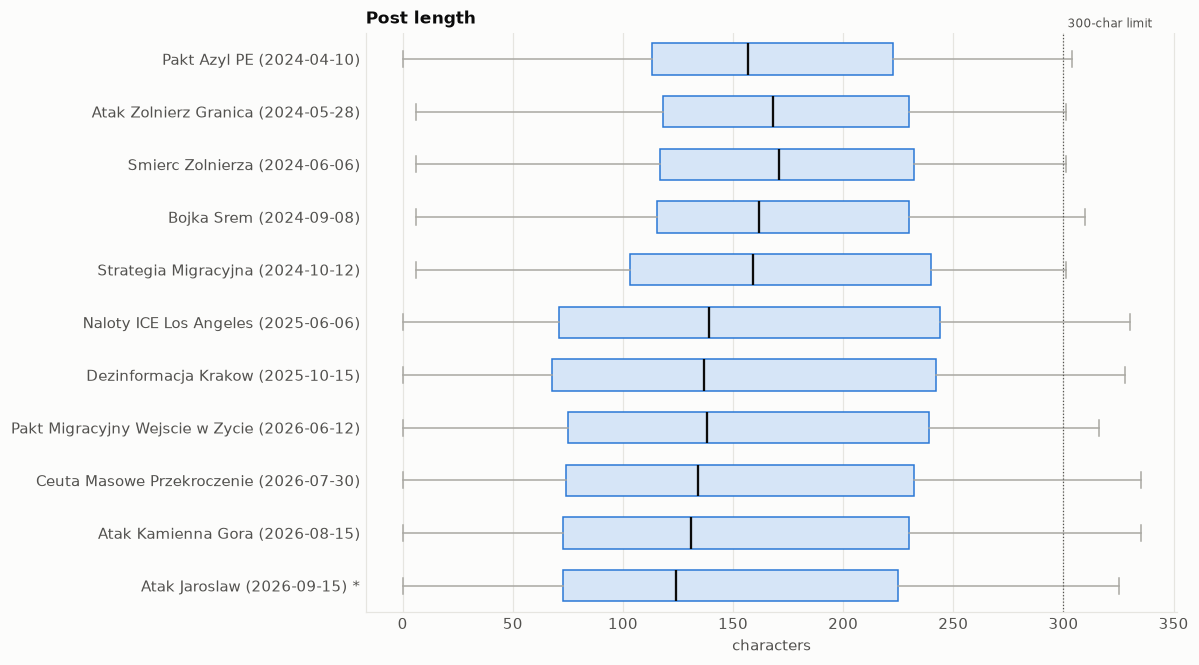

In [77]:
URL_RE = re.compile(r'https?://\S+|\b[\w.-]+\.(?:pl|com|org|net|eu|be|social|app|io|tv|info|gov|uk|de|me|ly|news)\b/?\S*', re.I)
HASHTAG_RE = re.compile(r'#(\w+)')
MENTION_RE = re.compile(r'@[\w.-]+')

feat = posts.assign(
    has_url=posts['text'].str.contains(URL_RE),
    has_hashtag=posts['text'].str.contains(r'#\w+'),
    has_mention=posts['text'].str.contains(MENTION_RE),
    multi_lang=posts['langs'].fillna('').str.contains(r'\|'),
).groupby('event').agg(
    median_chars=('text_len', 'median'),
    url_pct=('has_url', 'mean'),
    hashtag_pct=('has_hashtag', 'mean'),
    mention_pct=('has_mention', 'mean'),
    reply_pct=('is_reply', 'mean'),
    multi_lang_pct=('multi_lang', 'mean'),
).reindex(EVENTS)
for c in [c for c in feat if c.endswith('_pct')]:
    feat[c] = feat[c] * 100

fig, ax = plt.subplots(figsize=(11, 0.45 * len(EVENTS) + 1.2))
data = [posts.loc[posts['event'] == e, 'text_len'] for e in EVENTS]
bp = ax.boxplot(data, orientation='horizontal', showfliers=False, patch_artist=True, widths=0.6,
                medianprops=dict(color=TEXT_PRIMARY, lw=1.5), whiskerprops=dict(color=NEUTRAL),
                capprops=dict(color=NEUTRAL), boxprops=dict(edgecolor=SERIES[0]))
for b in bp['boxes']:
    b.set_facecolor('#d6e5f7')
ax.set_yticks(range(1, len(EVENTS) + 1), LABELS)
ax.invert_yaxis()
ax.axvline(300, color=TEXT_SECONDARY, lw=0.8, ls=':')
ax.text(300, 0.4, ' 300-char limit', fontsize=8, color=TEXT_SECONDARY)
ax.grid(axis='y', visible=False)
ax.set_xlabel('characters')
ax.set_title('Post length')
fig.tight_layout()
savefig(fig, '22_post_length')
feat.round(1)

### 9.2 Hashtags and most frequent words

In [78]:
STOPWORDS = set('''
a aby ach acz aczkolwiek aj albo ale alez ależ ani az aż bardziej bardzo beda bedzie będą będzie bez bo bowiem by byc być byl byla byli bylo byly był była było były bym bys byś caly cała cały ci cie cię ciebie co cos coś czy czyli daleko dla dlaczego dlatego do dobrze dokad dokąd dosc dość duzo dużo dwa dwaj dwie dwoje dzis dziś dzisiaj gdy gdyby gdyz gdyż gdzie gdzies gdzieś go i ich ile im inna inne inny innych iz iż ja jak jakas jakaś jakby jaki jakichs jakie jakis jakiś jakiz jakos jakoś jako ją je jeden jedna jednak jednakze jedno jego jej jemu jesli jeśli jest jestem jeszcze jezeli jeżeli juz już kazdy każdy kiedy kilka kims kimś kto ktora która ktore które ktorego którego ktorej której ktory który ktorych których ktorym którym ktorzy którzy ktos ktoś ku lat lecz lub ma maja mają mam mi miedzy między mimo mna mną mnie moga mogą moi moim moj mój moja moje moze może mozliwe mozna można mu musi my na nad nam nami nas nasi nasz nasza nasze naszego naszych natomiast natychmiast nawet nia nią nic nich nie niech niego niej niemu nigdy nim nimi niz niż no o obok od około ok on ona one oni ono oraz oto owszem pan pana pani po pod podczas pomimo ponad poniewaz ponieważ powinien powinna powinni powinno poza prawie przeciez przecież przed przede przedtem przez przy roku rowniez również sa są sam sama sie się skad skąd soba sobą sobie sposob sposób swoje ta tak taka taki takie takze także tam te tego tej temu ten teraz tez też to toba tobą tobie totez toteż trzeba tu tutaj twoi twoim twoj twój twoja twoje twym ty tych tylko tym tys tzw u w wam wami was wasz wasza wasze we według wiele wielu wiec więc wiecej więcej wlasnie właśnie wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy z za zaden żaden zadna żadna zadne żadne zadnych żadnych zapewne zawsze ze zeby żeby zl znow znów znowu zostal został żaden że jakiej jakim jakich jaką tą tę który tym tę ten były będę był byłem było bo coraz czym czego czemu której których naprawdę chyba właściwie tylko tyle sobie siebie tego temu tę wam mieć ma mają może można niech gdzie ktoś coś nikt nic więc jeszcze juz bardzo także tez tyż pod nad po przez dla przy bez między ok xd http https www com
the and for that this with you are was not but have has from they all just what about like will can out more one their there his her its who would been would were when your our them than then into some only any also how get got very had did does dont don't i'm it's
'''.split())
TOKEN_RE = re.compile(r'[^\W\d_]{3,}')

def tokens(text):
    text = MENTION_RE.sub(' ', URL_RE.sub(' ', text.lower()))
    return [w for w in TOKEN_RE.findall(text) if w not in STOPWORDS]

posts['tokens'] = posts['text'].map(tokens)
posts['hashtags'] = posts['text'].map(lambda t: [h.lower() for h in HASHTAG_RE.findall(t)])

def top_items(series_of_lists, n):
    c = Counter(x for lst in series_of_lists for x in lst)
    return [f'{w} ({k})' for w, k in c.most_common(n)]

TOP_WORDS = 15
words_table = pd.DataFrame({LABEL[e]: pd.Series(top_items(posts.loc[posts['event'] == e, 'tokens'], TOP_WORDS))
                            for e in EVENTS}).T
words_table.columns = range(1, words_table.shape[1] + 1)
display(Markdown(f'**Top {TOP_WORDS} words in posts (stop-words removed)**'))
display(words_table)

tags_table = pd.DataFrame({LABEL[e]: pd.Series(top_items(posts.loc[posts['event'] == e, 'hashtags'], 10))
                           for e in EVENTS}).T
tags_table.columns = range(1, tags_table.shape[1] + 1)
display(Markdown('**Top 10 hashtags**'))
display(tags_table.fillna(''))

**Top 15 words in posts (stop-words removed)**

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Pakt Azyl PE (2024-04-10),ukraine (450),russia (328),ukrainerussiawar (280),russian (113),gazie (105),defence (80),update (76),situation (76),izrael (62),according (61),wojny (60),link (58),april (55),ministry (50),today (48)
Atak Zolnierz Granica (2024-05-28),ukraine (590),russia (477),ukrainerussiawar (411),russian (220),defence (106),ukrainian (89),according (87),gazie (85),forces (72),link (71),ministry (69),general (69),drones (66),today (66),staff (66)
Smierc Zolnierza (2024-06-06),ukraine (602),russia (499),ukrainerussiawar (432),russian (248),ukrainian (116),defence (101),forces (97),according (92),drones (86),drone (85),brigade (85),general (69),staff (67),today (66),separate (65)
Bojka Srem (2024-09-08),ukraine (391),russia (348),ukrainerussiawar (270),russian (144),ukrainian (104),forces (82),drones (74),drone (55),region (54),according (53),night (46),attack (42),during (42),down (42),president (41)
Strategia Migracyjna (2024-10-12),ukraine (777),russia (644),ukrainerussiawar (512),russian (279),ukrainian (190),forces (177),drones (166),polska (114),drone (113),polski (112),night (91),during (87),according (86),armed (86),source (83)
Naloty ICE Los Angeles (2025-06-06),polski (5510),polsce (5042),polska (4537),link (3642),user (2613),fun (2505),literalnie (2461),pis (2445),polaków (1971),polacy (1756),polskę (1464),wybory (1450),trzaskowski (1388),dzień (1264),prezydenta (1168)
Dezinformacja Krakow (2025-10-15),link (3217),polski (2754),polsce (2638),polska (2599),ukraine (1729),fun (1550),literalnie (1549),russia (1260),user (1220),rosji (964),nato (941),pis (938),polaków (867),wojny (817),polacy (800)
Pakt Migracyjny Wejscie w Zycie (2026-06-12),link (4290),polsce (3043),polski (2952),polska (2738),ukrainy (1074),user (1011),polaków (912),polacy (872),literalnie (837),fun (834),ukraine (826),putin (814),usa (811),pis (811),wojny (801)
Ceuta Masowe Przekroczenie (2026-07-30),link (4297),polsce (2689),polska (2520),polski (2441),user (1278),polaków (978),pis (899),fun (889),polacy (875),rosji (791),ukraine (789),ukrainy (784),wojny (745),rosja (737),polskie (724)
Atak Kamienna Gora (2026-08-15),link (4230),polsce (2513),polska (2449),polski (2395),user (1270),polaków (908),fun (884),pis (839),polacy (784),wojny (759),rosji (743),polskie (719),rosja (701),literalnie (643),ukraine (632)


**Top 10 hashtags**

,1,2,3,4,5,6,7,8,9,10
Pakt Azyl PE (2024-04-10),ukraine (286),russia (282),ukrainerussiawar (280),russianlosses (45),uk (40),usa (8),germany (7),polish (4),standwithukraine (4),moscow (3)
Atak Zolnierz Granica (2024-05-28),ukraine (412),ukrainerussiawar (411),russia (411),russianlosses (60),uk (48),poland (7),polska (5),usa (5),eurovision (4),germany (3)
Smierc Zolnierza (2024-06-06),ukraine (433),ukrainerussiawar (432),russia (432),russianlosses (61),uk (46),poland (6),polska (5),eurovision (4),usa (4),germany (3)
Bojka Srem (2024-09-08),ukraine (284),russia (273),ukrainerussiawar (270),russianlosses (29),uk (15),kursk (15),kharkiv (9),usa (8),poland (8),supportukraine (4)
Strategia Migracyjna (2024-10-12),ukraine (529),russia (515),ukrainerussiawar (512),russianlosses (60),polska (55),scp (43),uk (30),kharkiv (28),kursk (21),usa (15)
Naloty ICE Los Angeles (2025-06-06),trzaskowski2025 (702),wygracałapolska (316),wyborcza (312),pis (295),polska (246),wybory2025 (185),nawrocki (158),wyboryprezydenckie2025 (140),ue (121),wybory (117)
Dezinformacja Krakow (2025-10-15),ukraine (857),russia (834),ukrainerussiawar (794),polska (463),wyborcza (297),polityka (201),nato (178),usa (130),wearenato (120),strongertogether (116)
Pakt Migracyjny Wejscie w Zycie (2026-06-12),polska (361),deliberatorium (94),24hhotnewsai (88),plnews (88),wybierznormalność (74),wykop (67),wykopalisko (67),polityka (65),nato (64),nieruchomosci (62)
Ceuta Masowe Przekroczenie (2026-07-30),polska (324),24hhotnewsai (140),plnews (140),rosja (94),ukraina (93),usa (70),deliberatorium (65),imgw (64),wykop (59),wykopalisko (58)
Atak Kamienna Gora (2026-08-15),polska (289),24hhotnewsai (154),plnews (154),rosja (88),ukraina (78),imgw (73),kaczyński (67),wykop (64),deliberatorium (64),wykopalisko (63)


### 9.3 Words that rise after the event

For each event: words whose relative frequency in posts grew most from the *before* to the *after* phase
(smoothed log-ratio, word must appear ≥ `MIN_AFTER` times after the event). This often surfaces
event-specific vocabulary (places, names) that the keyword list does not capture.

In [79]:
MIN_AFTER, TOP_RISING = 5, 12

def rising_words(e):
    p = posts[posts['event'] == e]
    before = Counter(w for t in p.loc[p['phase'] == 'before', 'tokens'] for w in t)
    after = Counter(w for t in p.loc[p['phase'].isin(['day_0', 'after']), 'tokens'] for w in t)
    nb, na = sum(before.values()), sum(after.values())
    if nb == 0 or na == 0:
        return []
    vocab = len(set(before) | set(after))
    scores = {w: np.log((after[w] + 1) / (na + vocab)) - np.log((before[w] + 1) / (nb + vocab))
              for w in after if after[w] >= MIN_AFTER}
    best = sorted(scores, key=scores.get, reverse=True)[:TOP_RISING]
    return [f'{w} ({before[w]}→{after[w]})' for w in best]

rising = pd.DataFrame({LABEL[e]: pd.Series(rising_words(e)) for e in EVENTS}).T
rising.columns = range(1, rising.shape[1] + 1)
rising.fillna('')

,1,2,3,4,5,6,7,8,9,10,11,12
Pakt Azyl PE (2024-04-10),protesty (0→15),wojnie (2→38),bliski (0→12),sytuacja (0→12),nowym (0→11),wschód (0→11),krawędzi (0→11),zaatakowali (0→11),dramatyczna (0→11),wydaje (0→11),jorku (0→10),przeciwko (1→21)
Atak Zolnierz Granica (2024-05-28),operators (1→32),june (0→14),soldier (0→12),company (1→23),eliminated (1→19),dnia (0→8),cruise (1→16),battalion (0→7),dane (0→6),named (0→6),marine (0→6),iskander (0→6)
Smierc Zolnierza (2024-06-06),soldier (1→26),fpv (0→10),self (0→6),propelled (0→6),korei (0→5),zatrważające (0→5),osiem (0→5),ogromnej (0→5),june (2→16),eliminated (4→27),shows (1→9),company (6→32)
Bojka Srem (2024-09-08),ukrainerussiawar (5→265),attacked (0→40),general (0→33),staff (0→31),losses (0→30),russianlosses (0→29),footage (0→28),separate (0→26),according (1→52),fire (0→23),speech (0→22),night (1→45)
Strategia Migracyjna (2024-10-12),scp (0→54),source (1→82),izrael (0→25),exploding (0→22),wybory (0→20),active (0→20),niemczech (0→19),dzień (0→18),zagrażać (0→18),wspierają (0→18),polonia (0→16),wojna (0→16)
Naloty ICE Los Angeles (2025-06-06),prawią (0→99),boeing (0→77),przebraniu (1→103),budki (1→101),pzpn (0→47),iranem (1→78),piwem (2→101),znajomo (2→101),manowska (0→30),sfałszowanewybory (0→30),bojowy (3→112),probierz (1→54)
Dezinformacja Krakow (2025-10-15),dream (0→31),heweliusz (0→26),niepodległości (3→104),robimyniegadamy (0→22),budapeszcie (1→40),budapesztu (0→19),november (0→18),wolontariuszką (0→18),kotom (0→18),kociaki (0→18),panleukopenią (0→18),konwencji (1→35)
Pakt Migracyjny Wejscie w Zycie (2026-06-12),hhotnewsai (0→88),plnews (0→88),obywatelski (0→79),nadajemy (0→74),urc (0→36),ukraińskiemu (2→81),ankara (0→25),markowski (0→25),bojówki (0→21),podlaskiej (0→18),summit (0→18),eurosatory (0→18)
Ceuta Masowe Przekroczenie (2026-07-30),szarada (0→107),romanowski (1→154),ceuta (0→38),monte (0→37),birmingham (0→37),ceuty (0→31),naddniestrzu (0→28),cassino (0→28),transpłciowych (0→27),opusdei (1→51),toronto (0→25),ciota (1→50)
Atak Kamienna Gora (2026-08-15),zondacrypto (2→132),autokaru (0→39),monte (0→39),cassino (0→29),mspo (1→52),piesiewicz (0→25),krala (0→22),pkol (0→21),kryptoaferapis (0→19),kral (0→18),nepalu (0→17),portret (0→17)


In [80]:
# Top words in comments (what do commenters talk about?)
comments['tokens'] = comments['text'].map(tokens)
cw = pd.DataFrame({LABEL[e]: pd.Series(top_items(comments.loc[comments['event'] == e, 'tokens'], TOP_WORDS))
                   for e in EVENTS}).T
cw.columns = range(1, cw.shape[1] + 1)
cw.fillna('')

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Pakt Azyl PE (2024-04-10),wiem (15),trochę (13),kiedyś (9),niestety (8),dobre (7),polski (7),sushi (7),znam (6),rozumiem (6),puławach (6),oglądać (5),chcę (5),rzeczy (5),czasem (5),polsce (5)
Atak Zolnierz Granica (2024-05-28),masz (7),wiem (4),twitterze (3),ukraina (3),link (3),takiej (3),całkiem (3),jakieś (3),jutro (3),dziękuję (3),feedy (3),takich (3),źle (3),dzięki (3),sumie (3)
Smierc Zolnierza (2024-06-06),masz (7),wiem (5),źle (5),takiej (4),jutro (4),sumie (4),ludzi (4),polsce (3),europie (3),obecnie (3),twitterze (3),ukraina (3),link (3),typu (3),zachodniej (3)
Bojka Srem (2024-09-08),russia (20),ukraine (19),ukrainerussiawar (16),post (11),link (11),wiem (10),original (9),mastodon (9),attack (9),wpisów (8),polski (7),bluesky (7),zbyt (7),scot (7),russian (7)
Strategia Migracyjna (2024-10-12),ukraine (34),russia (32),ukrainerussiawar (28),polski (23),dzięki (20),czas (19),link (19),kiedyś (17),wiem (17),russian (16),attack (16),trochę (16),polskie (15),raczej (15),razem (15)
Naloty ICE Los Angeles (2025-06-06),pis (1894),dzień (1479),dobry (1476),wiem (1297),ludzie (1092),ludzi (1036),user (982),mamy (966),polski (897),fun (893),niestety (877),literalnie (873),polsce (816),wybory (790),polska (790)
Dezinformacja Krakow (2025-10-15),user (695),dzień (608),dobry (589),wiem (556),dnia (502),ludzie (442),pis (425),ludzi (413),polski (407),polsce (381),dziękuję (369),niestety (358),mamy (342),trochę (328),masz (326)
Pakt Migracyjny Wejscie w Zycie (2026-06-12),wiem (632),user (603),polski (568),polsce (567),polska (563),pis (517),niestety (507),dobry (505),mamy (480),ludzie (463),dzień (460),ludzi (438),link (427),masz (390),oczywiście (355)
Ceuta Masowe Przekroczenie (2026-07-30),user (1537),wiem (614),pis (563),ludzie (480),polsce (442),polska (426),ludzi (426),niestety (424),link (424),polski (423),mamy (395),masz (328),dzień (320),dobry (319),pewnie (306)
Atak Kamienna Gora (2026-08-15),user (1616),wiem (563),pis (500),ludzie (461),ludzi (420),polski (405),polsce (404),link (382),niestety (378),polska (364),dzień (352),dobry (348),mamy (335),dnia (316),masz (292)


## 10. Comment text quality

`comments.csv` keeps every reply whose `langs` tag contains `pl`, but that tag is set by the author's client,
not by looking at the text. So the sample contains comments that are useless for text analysis:
emoji-only reactions, bare links / mentions, one-word replies, and comments tagged `pl` that are written in
English or another language.

Every comment gets one `quality` label (checked in this order):

| label | rule |
|---|---|
| `no_text` | empty, or only links / `[link]` / mentions / hashtags / numbers / punctuation |
| `emoji_only` | nothing but emoji (plus optional links / mentions / punctuation) |
| `very_short` | fewer than `MIN_WORDS` words once links, mentions and hashtags are removed |
| `english` / `other_language` | detected language is not Polish |
| `unclear_language` | language cannot be determined |
| `polish` | Polish text with at least `MIN_WORDS` words, the **clean** comments |

Language detection is a dependency-free heuristic: it counts Polish, English and German function words,
Polish / German diacritics, and Cyrillic script. When those give no clear answer it falls back to
character n-grams (`sz`, `cz`, `rz` … vs `th`, `ing`, `wh` …). It is good enough for EDA. For
production filtering, use a real detector (e.g. `lingua-language-detector`). Nothing is removed here:
the labels are flags, and `comments_clean` is the filtered view.

In [81]:
MIN_WORDS = 3                   # fewer words (after removing links, mentions, hashtags) -> very_short
CLEAN_LABELS = {'polish'}       # labels kept in comments_clean; add 'very_short' to keep short Polish replies

LINK_RE = re.compile(r'\[link\]|https?://\S+|\b[\w.-]+\.(?:pl|com|org|net|eu|be|social|app|io|tv|info|gov|uk|de|me|ly|news|fun)\b/?\S*', re.I)
USER_RE = re.compile(r'@\[user\]|@[\w.-]+')
EMOJI_RE = re.compile('[\U0001F000-\U0001FAFF☀-➿⬀-⯿←-⇿️‍⃣]')
WORD_RE = re.compile(r'[^\W\d_]+')
CYRILLIC_RE = re.compile('[Ѐ-ӿ]')

PL_FUNC = set("""
w z na się nie że jest do to co jak ale tak czy już tylko jego jej ich mnie mi go bo być był była było są będzie
tym tego też jeszcze może można przez dla od po pod nad przy bez gdy gdzie kiedy który która które których ten ta
te tam tu tutaj więc oraz albo lub ani nawet bardzo trochę dobrze wiem mam masz ma nic coś ktoś teraz dziś jutro
jednak chyba raczej właśnie także również niech dzięki dziękuję proszę sobie jakby jaki jakie żeby aby czyli
sie ze juz tez moze wiecej dzieki zeby ktory ktora ktore byly bylo jestem jestes moj twoj nas was wam nam
""".split())
EN_FUNC = set("""
the and of is are was were be been have has had this that these those with for not but you your they them their
what which who would could should will can just about from there here when where why how very really think know
like people get got dont don't its it's i'm im thanks thank yes does did an me we our us he she his her it in at
""".split())
DE_FUNC = set("""
und der die das ist nicht ein eine mit auf für ich sie wir ihr es sich auch wie aber noch nur dass wenn oder
schon sehr kann werden wurde hat haben sind war bei aus nach zum zur den dem des
""".split())
# words that are function words in more than one language carry no signal
_ambiguous = (PL_FUNC & EN_FUNC) | (PL_FUNC & DE_FUNC) | (EN_FUNC & DE_FUNC) | {'a', 'i', 'o', 'to', 'no', 'on', 'my'}
PL_FUNC -= _ambiguous - {'na', 'to', 'no', 'o', 'i', 'a', 'my'}   # these lean Polish in a Polish-tagged sample
EN_FUNC -= _ambiguous
DE_FUNC -= _ambiguous
PL_NGRAMS = ['sz', 'cz', 'rz', 'ie', 'dz', 'ych', 'ego', 'ow ', 'prz', 'wie', 'ać', 'yć', 'iś']
EN_NGRAMS = ['th', 'ing', 'wh', 'ea', 'ou', 'ght', 'ee', 'oo', 'ly ', 'tion', 'ck']


def detect_lang(words):
    lw = [w.lower() for w in words]
    letters = ''.join(lw)
    if len(CYRILLIC_RE.findall(letters)) > 0.5 * len(letters):
        return 'cyrillic'
    score = {
        'pl': sum(w in PL_FUNC for w in lw) + sum(any(c in 'ąćęłńóśźż' for c in w) for w in lw),
        'en': sum(w in EN_FUNC for w in lw),
        'de': sum(w in DE_FUNC for w in lw) + sum(any(c in 'äöüß' for c in w) for w in lw),
    }
    best, second = sorted(score.values(), reverse=True)[:2]
    if best > second:
        return max(score, key=score.get)
    # no clear winner on function words -> character n-grams (Polish written without diacritics etc.)
    text = ' '.join(lw) + ' '
    p, e = sum(text.count(g) for g in PL_NGRAMS), sum(text.count(g) for g in EN_NGRAMS)
    if p >= 2 and p >= 2 * e:
        return 'pl'
    if e >= 2 and e >= 2 * p:
        return 'en'
    return 'unknown'


def text_quality(text):
    # -> (quality label, detected language or None, number of words)
    rest = HASHTAG_RE.sub(' ', USER_RE.sub(' ', LINK_RE.sub(' ', text)))
    words = WORD_RE.findall(rest)
    if not words:
        return ('emoji_only' if EMOJI_RE.search(text) else 'no_text'), None, 0
    lang = detect_lang(words)
    if len(words) < MIN_WORDS:
        return 'very_short', lang, len(words)
    label = {'pl': 'polish', 'en': 'english', 'unknown': 'unclear_language'}.get(lang, 'other_language')
    return label, lang, len(words)


QUALITY_ORDER = ['polish', 'very_short', 'emoji_only', 'no_text', 'english', 'other_language', 'unclear_language']
q = comments['text'].map(text_quality)
comments['quality'] = pd.Categorical(q.str[0], categories=QUALITY_ORDER)
comments['detected_lang'] = q.str[1]
comments['n_words'] = q.str[2]
comments['is_clean'] = comments['quality'].isin(CLEAN_LABELS)
comments_clean = comments[comments['is_clean']].copy()

overall = comments['quality'].value_counts().reindex(QUALITY_ORDER).to_frame('comments')
overall['share_%'] = (overall['comments'] / len(comments) * 100).round(2)
display(Markdown(f"**{comments['is_clean'].sum():,} of {len(comments):,} comments "
                 f"({comments['is_clean'].mean() * 100:.1f}%) are clean** (labels: {', '.join(sorted(CLEAN_LABELS))})"))
overall

**175,921 of 220,066 comments (79.9%) are clean** (labels: polish)

,comments,share_%
quality,,
polish,175921,79.94
very_short,21256,9.66
emoji_only,12654,5.75
no_text,5464,2.48
english,2495,1.13
other_language,375,0.17
unclear_language,1901,0.86


,comments,clean,clean_%,clean_commenters,polish,very_short,emoji_only,no_text,english,other_language,unclear_language
event,,,,,,,,,,,
Pakt_Azyl_PE,234,187,79.9,23,187,31,4,5,3,0,4
Atak_Zolnierz_Granica,114,91,79.8,21,91,10,1,5,5,1,1
Smierc_Zolnierza,141,113,80.1,22,113,13,2,7,3,1,2
Bojka_Srem,253,185,73.1,28,185,20,0,19,25,0,4
Strategia_Migracyjna,778,613,78.8,138,613,68,9,41,35,5,7
Naloty_ICE_Los_Angeles,62707,50669,80.8,2601,50669,6555,3221,1535,226,9,492
Dezinformacja_Krakow,32537,25611,78.7,1497,25611,3591,1985,820,220,11,299
Pakt_Migracyjny_Wejscie_w_Zycie,35341,28370,80.3,1175,28370,3121,1957,866,708,48,271
Ceuta_Masowe_Przekroczenie,32137,25587,79.6,1144,25587,2795,2025,792,567,81,290


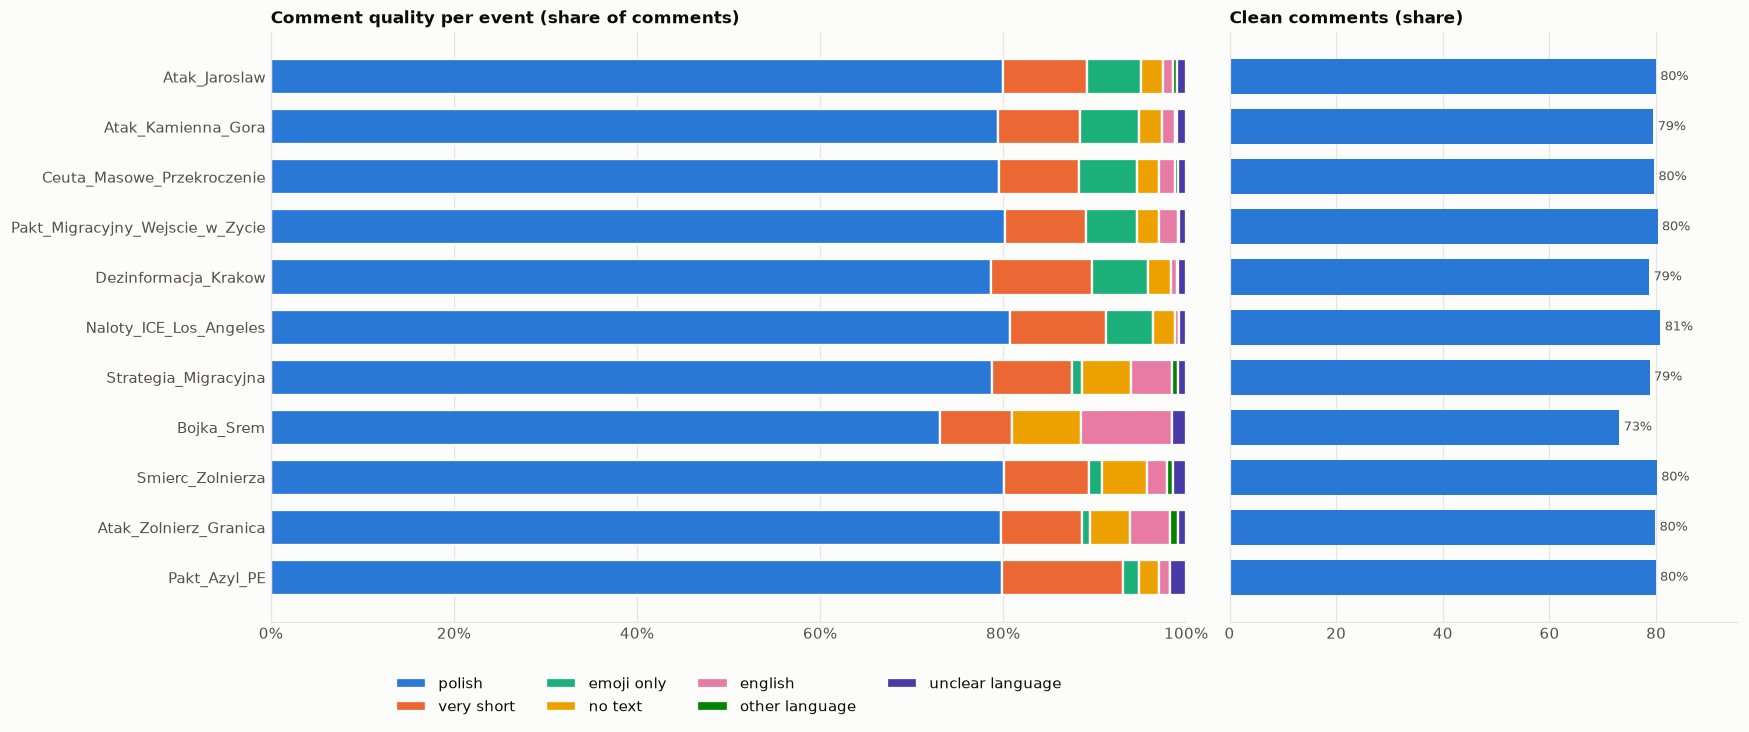

In [82]:
# Quality mix per event + how many comments remain after cleaning
qmix = (comments.groupby(['event', 'quality'], observed=False).size().unstack(fill_value=0)
        .reindex(index=EVENTS, columns=QUALITY_ORDER, fill_value=0))
qshare = qmix.div(qmix.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(EVENTS) + 1.8), sharey=True,
                         gridspec_kw={'width_ratios': [1.8, 1]})
left = np.zeros(len(EVENTS))
y = np.arange(len(EVENTS))
for i, c in enumerate(QUALITY_ORDER):
    vals = qshare[c].fillna(0).values
    axes[0].barh(y, vals, left=left, color=SERIES[i], height=0.7, edgecolor=SURFACE, linewidth=1.5,
                 label=c.replace('_', ' '))
    left += vals
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 100)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=4)
axes[0].set_title('Comment quality per event (share of comments)')

hbar(axes[1], qshare[[c for c in QUALITY_ORDER if c in CLEAN_LABELS]].sum(axis=1), None, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Clean comments (share)')
axes[1].tick_params(labelleft=False)
fig.tight_layout()
savefig(fig, '21_comment_quality')

clean_summary = pd.DataFrame({
    'comments': qmix.sum(axis=1),
    'clean': comments_clean.groupby('event').size().reindex(EVENTS, fill_value=0),
})
clean_summary['clean_%'] = (clean_summary['clean'] / clean_summary['comments'].replace(0, np.nan) * 100).round(1)
clean_summary['clean_commenters'] = comments_clean.groupby('event')['author_id'].nunique().reindex(EVENTS)
clean_summary.join(qmix)

### 10.1 Declared vs detected language

The `langs` tag compared with the language detected in the text, for comments with at least `MIN_WORDS` words.
Comments detected as another language passed the `pl` filter by mistake.

In [83]:
long_enough = comments[comments['n_words'] >= MIN_WORDS]
declared = np.where(long_enough['langs'].fillna('').eq('pl'), 'pl only', 'pl + other tag')
lang_xtab = pd.crosstab(declared, long_enough['detected_lang'], margins=True, margins_name='total')
lang_xtab.index.name, lang_xtab.columns.name = 'langs tag', 'detected'
display(lang_xtab)

not_pl = long_enough['detected_lang'].isin(['en', 'de', 'cyrillic'])
display(Markdown(f"**{not_pl.sum():,}** comments ({not_pl.mean() * 100:.1f}% of those with ≥ {MIN_WORDS} words) "
                 f"are tagged `pl` but detected as another language. Among comments tagged *only* `pl` the share is "
                 f"{not_pl[declared == 'pl only'].mean() * 100:.1f}%; with an extra language tag it is "
                 f"{not_pl[declared != 'pl only'].mean() * 100:.1f}%."))

# Which authors produce the non-Polish comments? (often a few bilingual / news-relay accounts)
(comments[comments['quality'].isin(['english', 'other_language'])]
 .groupby(['event', 'author_id']).size().sort_values(ascending=False).head(10).rename('non_polish_comments'))

detected,cyrillic,de,en,pl,unknown,total
langs tag,,,,,,
pl + other tag,0,0,238,3637,40,3915
pl only,33,342,2257,172284,1861,176777
total,33,342,2495,175921,1901,180692


**2,870** comments (1.6% of those with ≥ 3 words) are tagged `pl` but detected as another language. Among comments tagged *only* `pl` the share is 1.5%; with an extra language tag it is 6.1%.

event                            author_id
Pakt_Migracyjny_Wejscie_w_Zycie  A00130       258
Ceuta_Masowe_Przekroczenie       A00006       235
Atak_Jaroslaw                    A00067       120
Atak_Kamienna_Gora               A00011       114
Pakt_Migracyjny_Wejscie_w_Zycie  A00002        91
                                 A00590        85
Atak_Kamienna_Gora               A00062        74
Ceuta_Masowe_Przekroczenie       A00007        74
Pakt_Migracyjny_Wejscie_w_Zycie  A00001        69
Ceuta_Masowe_Przekroczenie       A00052        68
Name: non_polish_comments, dtype: int64

### 10.2 Examples per label

Random examples for checking the labels by hand. Change `EXAMPLE_SEED` to see others. If a label looks wrong,
adjust the word lists, `MIN_WORDS` or `CLEAN_LABELS` above.

In [84]:
EXAMPLE_SEED, N_EXAMPLES = 0, 8
examples = pd.concat([g.sample(min(N_EXAMPLES, len(g)), random_state=EXAMPLE_SEED)
                      for _, g in comments.groupby('quality', observed=True)])
examples.assign(text=examples['text'].map(short))[['quality', 'detected_lang', 'langs', 'n_words', 'event', 'text']] \
    .reset_index(drop=True)

,quality,detected_lang,langs,n_words,event,text
0,polish,pl,pl|uk,6,Ceuta_Masowe_Przekroczenie,"Nadużycie semantyczne słowa ""wojna"" i już."
1,polish,pl,pl,3,Dezinformacja_Krakow,Marta nie patrz!!!
2,polish,pl,pl,3,Naloty_ICE_Los_Angeles,Dałaś się zmanipulować. 🤭
3,polish,pl,pl,19,Dezinformacja_Krakow,"Można też powiedzieć, że jesteś szczęściarzem, bo tam gdzie Pendolino, tam też dużo mniej tanich pociągów, więc Kraków cierpi :)"
4,polish,pl,pl,41,Ceuta_Masowe_Przekroczenie,"Hipotetyczne zawieszenie konstytucji na czas zrobienia porządków w instyt. prawa, a później jej odwieszenie jest zaprzeczeniem istoty De..."
5,polish,pl,pl,10,Pakt_Migracyjny_Wejscie_w_Zycie,"Niech go wymieni na jednego obola, dla Harona na Styksie."
6,polish,pl,pl,5,Atak_Kamienna_Gora,@[user] Polecam film ze statku MSC.
7,polish,pl,pl,16,Pakt_Migracyjny_Wejscie_w_Zycie,a jak cały kraj blokowany jest w pewien czwartek pochodami i nielegalnymi zgromadzeniami to wszytko cacy
8,very_short,unknown,pl,2,Pakt_Migracyjny_Wejscie_w_Zycie,Typowy konfederata
9,very_short,pl,pl,2,Dezinformacja_Krakow,Jesteś rasistką?


In [85]:
# Repeated texts among clean comments within an event (copy-paste, bots, multi-part relays).
# Checked per event: event windows overlap, so the same comment can legitimately appear under several events.
dup_key = comments_clean.assign(norm=comments_clean['text'].str.strip().str.lower())
is_dup = dup_key.duplicated(['event', 'norm'])
repeated = dup_key.groupby(['event', 'norm']).size().loc[lambda s: s > 1].sort_values(ascending=False)
cross_event = comments.duplicated('link').sum()
display(Markdown(f"**{is_dup.sum():,}** clean comments ({is_dup.mean() * 100:.1f}%) repeat a text already seen in the same "
                 f"event; {len(repeated):,} distinct texts occur more than once. Separately, **{cross_event:,}** comment rows "
                 f"are the same comment collected for more than one (overlapping) event."))
repeated.head(15).rename('times').reset_index().rename(columns={'norm': 'text'}).assign(text=lambda d: d['text'].map(short))

**919** clean comments (0.5%) repeat a text already seen in the same event; 494 distinct texts occur more than once. Separately, **40,197** comment rows are the same comment collected for more than one (overlapping) event.

,event,text,times
0,Ceuta_Masowe_Przekroczenie,tchórzliwa ciota #romanowski 🌈 jest nienawidzącym kobiet złodziejem i zdrajcą z finansowanej przez kreml pedalskiej sekty #opusdei: #ped...,30
1,Atak_Kamienna_Gora,tchórzliwa ciota #romanowski 🌈 jest nienawidzącym kobiet złodziejem i zdrajcą z finansowanej przez kreml pedalskiej sekty #opusdei: #ped...,30
2,Naloty_ICE_Los_Angeles,"polską od dekad rządzi lewica — choć czasem w przebraniu prawicy. dziś mówi, że demokrację trzeba zawiesić, żeby ją ocalić. brzmi znajom...",14
3,Naloty_ICE_Los_Angeles,cześć 🙋🏻‍♂️ 🤗 miłego dnia 🍀🌞🦋☕️,11
4,Atak_Jaroslaw,#wojna w #ukrainie. bezpieczeństwo #polski nie istnieje. polski nierząd moimokiem-bezfikcji.blogspot.com/2026/08/wojn...,10
5,Atak_Kamienna_Gora,"dziękuję za przeczytanie, zapraszam do komentowania i udostępniania. jak zawsze polecam @[user] zapraszam również do wsparcia mojej prac...",9
6,Atak_Jaroslaw,#wojna #putina z resztą #europy już od dawna trwa moimokiem-bezfikcji.blogspot.com/2026/09/wojn...,9
7,Atak_Jaroslaw,"cholernie trudne pytanie, czy mielibyśmy prawo użyć tej bomby❓ moimokiem-bezfikcji.blogspot.com/2023/02/chol...",9
8,Naloty_ICE_Los_Angeles,dzień dobry anna,8
9,Dezinformacja_Krakow,"jest godzina 10:12 niedziela 26pazdziernik 2025 rok, w tej chwili jest nas 39,895,128 użytkowników na bluesky. skąd masz ty swoje inform...",8


## 11. Key findings (auto-generated)

In [86]:
lines = []
big, small = summary['posts'].idxmax(), summary['posts'].idxmin()
lines.append(f"- **{len(EVENTS)} events**, {totals['posts']:,} posts and {totals['comments']:,} comments in total.")
lines.append(f"- Largest event: **{LABEL[big]}** ({summary.loc[big, 'posts']:,} posts, "
             f"{summary.loc[big, 'comments']:,} comments); smallest: **{LABEL[small]}** ({summary.loc[small, 'posts']:,} posts).")
cpp = summary['comments_per_post']
lines.append(f"- Most discussion per post: **{LABEL[cpp.idxmax()]}** ({cpp.max():.2f} comments/post); "
             f"least: **{LABEL[cpp.idxmin()]}** ({cpp.min():.2f}).")
l = lift['posts day0..+3 vs before %'].astype(float)
lines.append(f"- Strongest short-term reaction (days 0..+3 vs baseline): **{LABEL[l.idxmax()]}** ({l.max():+.0f}%); "
             f"weakest: **{LABEL[l.idxmin()]}** ({l.min():+.0f}%).")
lines.append(f"- Most frequent keyword overall: **{kw_total.index[0]}** ({kw_total.iloc[0]:,} posts); "
             f"{len(never)} search keywords never matched.")
for e in EVENTS:
    s = shifts.get(e)
    if s is not None and len(s) and s.max() > 0:
        lines.append(f"- {LABEL[e]}: biggest keyword gain after the event – **{s.idxmax()}** ({s.max():+.1f} pp).")
lines.append(f"- Median response latency across all comments: **{comments['latency_h'].median():.1f} h**; "
             f"{(comments['latency_h'] <= 1).mean() * 100:.0f}% of comments arrive within 1 h.")
lines.append(f"- Self-replies (post author commenting in own thread): **{comments['is_material_author'].mean() * 100:.0f}%** of comments.")
lines.append(f"- Clean comments (Polish, ≥ {MIN_WORDS} words): **{comments['is_clean'].mean() * 100:.0f}%**; "
             f"emoji-only {(comments['quality'] == 'emoji_only').mean() * 100:.1f}%, "
             f"tagged `pl` but not Polish {comments['quality'].isin(['english', 'other_language']).mean() * 100:.1f}%.")
if skipped:
    lines.append('- Skipped folders: ' + ', '.join(f'`{n}` ({w})' for n, w in skipped))
display(Markdown('\n'.join(lines)))

- **11 events**, 203,627 posts and 220,066 comments in total.
- Largest event: **Naloty ICE Los Angeles (2025-06-06)** (48,666 posts, 62,707 comments); smallest: **Bojka Srem (2024-09-08)** (627 posts).
- Most discussion per post: **Naloty ICE Los Angeles (2025-06-06)** (1.29 comments/post); least: **Atak Zolnierz Granica (2024-05-28)** (0.15).
- Strongest short-term reaction (days 0..+3 vs baseline): **Bojka Srem (2024-09-08)** (+105%); weakest: **Naloty ICE Los Angeles (2025-06-06)** (-18%).
- Most frequent keyword overall: **polsk*** (105,803 posts); 0 search keywords never matched.
- Pakt Azyl PE (2024-04-10): biggest keyword gain after the event – **ukrain*** (+15.2 pp).
- Atak Zolnierz Granica (2024-05-28): biggest keyword gain after the event – **ukrain*** (+8.4 pp).
- Smierc Zolnierza (2024-06-06): biggest keyword gain after the event – **ukrain*** (+8.2 pp).
- Bojka Srem (2024-09-08): biggest keyword gain after the event – **ukrain*** (+54.5 pp).
- Strategia Migracyjna (2024-10-12): biggest keyword gain after the event – **polsk*** (+30.2 pp).
- Naloty ICE Los Angeles (2025-06-06): biggest keyword gain after the event – **granic*** (+2.8 pp).
- Dezinformacja Krakow (2025-10-15): biggest keyword gain after the event – **polsk*** (+3.4 pp).
- Pakt Migracyjny Wejscie w Zycie (2026-06-12): biggest keyword gain after the event – **ukrain*** (+6.5 pp).
- Ceuta Masowe Przekroczenie (2026-07-30): biggest keyword gain after the event – **polsk*** (+3.0 pp).
- Atak Kamienna Gora (2026-08-15): biggest keyword gain after the event – **polsk*** (+4.1 pp).
- Atak Jaroslaw (2026-09-15) *: biggest keyword gain after the event – **putin*** (+2.9 pp).
- Median response latency across all comments: **1.2 h**; 46% of comments arrive within 1 h.
- Self-replies (post author commenting in own thread): **31%** of comments.
- Clean comments (Polish, ≥ 3 words): **80%**; emoji-only 5.8%, tagged `pl` but not Polish 1.3%.